# Capítulo 5 — Momentos, distribuições e teorema do limite central

Vamos estudar como descrever uma distribuição e como ela muda quando somamos ou fazemos a média de várias medidas. O objetivo é entender de onde vêm as fórmulas: primeiro definimos o problema, depois fazemos a conta e, por fim, usamos o código para visualizar o resultado.

Este notebook segue os **slides 1–55 da Parte II** de Estatística Bayesiana, de Miguel Quartin (CBPF, 2026/2), e o **capítulo 5 do Gregory**. As conexões com GW–galáxias são exemplos de uso desses conceitos, sem assumir que o modelo simples de cada exercício já descreve toda a análise da pesquisa.

| Bloco | O que vamos fazer | O que queremos entender |
|:--|:--|:--|
| **1. Descrever uma distribuição** | Momentos, média, mediana, moda, skewness, kurtosis e fundo móvel | O que cada quantidade mede e quando ela existe |
| **2. Gerar momentos e cumulantes** | MGF, função característica e transformada de Fourier | Por que derivadas geram momentos e por que cumulantes somam |
| **3. Distribuições importantes** | Binomial, Poisson, binomial negativa, Gaussiana, uniforme, Gamma e Beta | Parâmetros, interpretação física, contas e limites |
| **4. Somar e fazer médias** | TLC, convoluções e o slide 49 | O que muda de forma, o que estreita e quais hipóteses usamos |
| **5. Gerar amostras** | Prova do slide 50 e exemplo bimodal do slide 51 | Como uma uniforme pode produzir outras distribuições |

In [1]:
# Configuração: bibliotecas, aparência e exportação opcional.
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize, signal, ndimage
from IPython.display import display

SALVAR_FIGURAS = False
PASTA_FIGURAS = Path('figuras_capitulo_5')
CORES = ['#176B87', '#D27A25', '#41805B', '#915CA8', '#BC4B51']
plt.rcParams.update({
    'figure.dpi': 115, 'savefig.dpi': 180, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=CORES),
    'figure.constrained_layout.use': True,
})
pd.set_option('display.max_columns', 12)

def finalizar(fig, nome):
    """Mostrar uma figura e, se solicitado, exportá-la com o mesmo nome."""
    if SALVAR_FIGURAS:
        PASTA_FIGURAS.mkdir(exist_ok=True)
        fig.savefig(PASTA_FIGURAS / f'{nome}.pdf', bbox_inches='tight')
        fig.savefig(PASTA_FIGURAS / f'{nome}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def tabela(linhas):
    """Exibir resultados numéricos com precisão suficiente para a comparação."""
    display(pd.DataFrame(linhas).round(6))

# Verificações ficam reunidas ao final. Cada chamada deve conferir uma relação
# matemática por uma rota diferente, não apenas repetir uma fórmula no código.
VERIFICACOES = []
def conferir(nome, calculado, esperado, rtol=1e-6, atol=1e-8):
    np.testing.assert_allclose(calculado, esperado, rtol=rtol, atol=atol,
                               err_msg=nome)
    VERIFICACOES.append(nome)

print('Configuração pronta. Cada exemplo terá seu próprio gerador e semente.')


Configuração pronta. Cada exemplo terá seu próprio gerador e semente.


## Bloco 1 — O que estamos descrevendo?
### 1.1 Variável, resultado observado e distribuição

Uma variável aleatória é uma regra que associa um número a cada resultado possível de um experimento. Vamos usar **maiúsculas para variáveis** e **minúsculas para valores possíveis ou observados**. Por exemplo, $X_i$ é a contagem que o detector poderá registrar na exposição $i$; $x_i$ é a contagem efetivamente registrada.

Se fizermos $n$ exposições, teremos $X_1,\ldots,X_n$. Precisamos dos índices porque podemos querer a distribuição **conjunta**: qual a probabilidade de obter $x_1$ na primeira exposição, $x_2$ na segunda, e assim por diante? Se forem independentes, condicionadas às informações $I$, então

$$p(x_1,\ldots,x_n\mid I)=\prod_{i=1}^n p_i(x_i\mid I).$$

Quando todas possuem a mesma distribuição, dizemos que são **independentes e identicamente distribuídas**, abreviado IID. A independência é uma hipótese sobre a distribuição conjunta!

Isso esclarece uma frase do slide 5: na urna sem reposição, as probabilidades **condicionais** mudam após cada retirada. Mas, antes de observar qualquer retirada, todas as posições podem ter a mesma marginal $P(X_i=1)=M/N$, com $M$ bolas da cor escolhida entre $N$ bolas. São marginais iguais e variáveis dependentes. $X_i$ pode depender de $X_j$ e suas marginais separadas serem as mesmas, como nesse exemplo.e

Para fixar a notação:

| Símbolo | Significado |
|:--|:--|
| $p_X(x)=P(X=x)$ | Massa de probabilidade, para $X$ discreta |
| $f_X(x)$ | Densidade de probabilidade, para $X$ contínua |
| $F_X(x)=P(X\leq x)$ | Função de distribuição acumulada, CDF |
| $\mathbb E[g(X)]=\langle g(X)\rangle$ | Valor esperado de uma função $g$ |
| $\mu=\mathbb E[X]$; $\sigma^2=\operatorname{Var}(X)$ | Média e variância, quando existem |

No caso contínuo, $P(a<X<b)=\int_a^b f_X(x)\,dx=F_X(b)-F_X(a)$. A altura da PDF não é a probabilidade de obter exatamente aquele valor: a probabilidade está na **área**. A densidade pode até exceder 1, dependendo das unidades e da largura da distribuição.

Vamos retomar os gráficos de PDF/PMF e CDF dos slides 7–8: dez lançamentos de uma moeda justa e um exemplo contínuo. Neste primeiro gráfico só precisamos saber que a binomial conta caras e que a exponencial descreve um tempo de espera; suas fórmulas serão derivadas adiante.


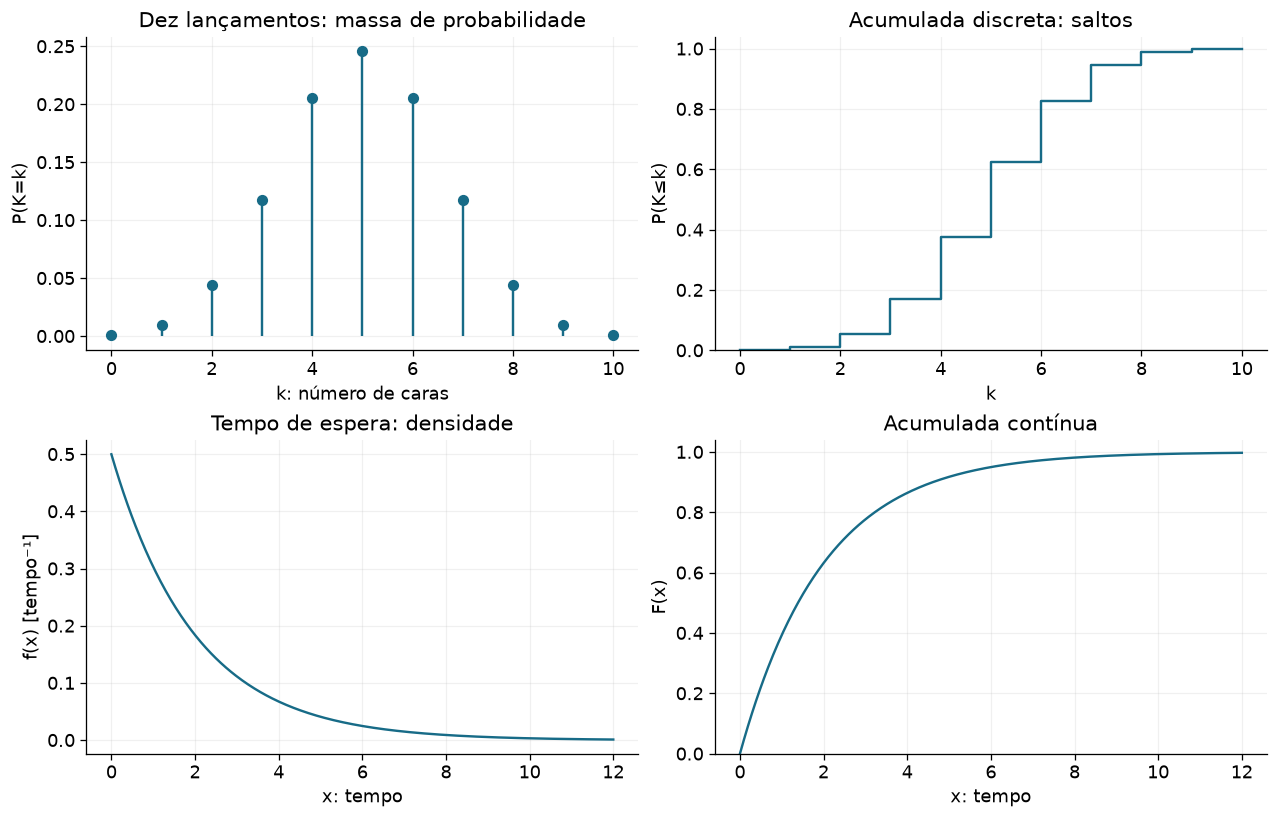

In [2]:
# Comparação da distribuição com sua acumulada.
n_moeda, p_cara = 10, 0.5
k_contagem = np.arange(n_moeda + 1)
moeda = stats.binom(n_moeda, p_cara)
espera = stats.expon(scale=2.0)  # Tempo médio de espera: 2 unidades.
x_tempo = np.linspace(0, 12, 500)
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
axs[0, 0].stem(k_contagem, moeda.pmf(k_contagem), basefmt=' ')
axs[0, 0].set(title='Dez lançamentos: massa de probabilidade', xlabel='k: número de caras', ylabel='P(K=k)')
axs[0, 1].step(k_contagem, moeda.cdf(k_contagem), where='post')
axs[0, 1].set(title='Acumulada discreta: saltos', xlabel='k', ylabel='P(K≤k)', ylim=(0, 1.04))
axs[1, 0].plot(x_tempo, espera.pdf(x_tempo))
axs[1, 0].set(title='Tempo de espera: densidade', xlabel='x: tempo', ylabel='f(x) [tempo⁻¹]')
axs[1, 1].plot(x_tempo, espera.cdf(x_tempo))
axs[1, 1].set(title='Acumulada contínua', xlabel='x: tempo', ylabel='F(x)', ylim=(0, 1.04))
conferir('normalização da binomial', moeda.pmf(k_contagem).sum(), 1)
conferir('área da exponencial', integrate.quad(espera.pdf, 0, np.inf)[0], 1)
finalizar(fig, '01_distribuicao_e_acumulada')


### 1.2 Momentos: médias de potências

O valor esperado é uma média ponderada pelas probabilidades:

$$\mathbb E[g(X)]=\sum_x g(x)p_X(x)\quad\text{ou}\quad
\mathbb E[g(X)]=\int_{-\infty}^{\infty}g(x)f_X(x)\,dx.$$

Para que essa média seja um número finito bem definido, precisamos de $\mathbb E[|g(X)|]<\infty$. Essa condição evita tentar cancelar duas contribuições infinitas. Nem toda distribuição possui média ou variância.

O **momento de ordem $r$ em torno da origem** é $m_r=\mathbb E[X^r]$, com $r$ inteiro não negativo. Usaremos $m_r$ no lugar de $\mu'_r$ dos slides para não confundir com os momentos centrais. Temos $m_0=1$ e $m_1=\mu$.

O **momento central** usa desvios em relação à média:

$$\mu_r=\mathbb E[(X-\mu)^r].$$

Vamos abrir as contas dos quatro primeiros. Pela linearidade de $\mathbb E$,

$$\mu_1=\mathbb E[X]-\mu=0,$$
$$\mu_2=\mathbb E[X^2-2\mu X+\mu^2]=m_2-2\mu m_1+\mu^2=m_2-\mu^2=\sigma^2,$$
$$\mu_3=m_3-3\mu m_2+3\mu^2m_1-\mu^3=m_3-3\mu m_2+2\mu^3,$$
$$\mu_4=m_4-4\mu m_3+6\mu^2m_2-4\mu^3m_1+\mu^4
=m_4-4\mu m_3+6\mu^2m_2-3\mu^4.$$

Se $X$ tem unidades de tempo, $m_r$ e $\mu_r$ têm unidades de tempo$^r$. Por isso não faz sentido comparar a assimetria de duas distribuições usando apenas $\mu_3$ quando suas escalas são diferentes e recorremos aos momentos normalizados!.

**Exercício do slide 11.** Se $Y=aX+b$, com $a,b$ fixos, então $\mathbb E[Y]=a\mu+b$ e

$$Y-\mathbb E[Y]=a(X-\mu),\qquad
\operatorname{Var}(Y)=\mathbb E[a^2(X-\mu)^2]=a^2\sigma^2.$$

O deslocamento $b$ não muda a dispersão. A escala $a$ multiplica o desvio padrão por $|a|$. Mais geralmente, $\mu_r(Y)=a^r\mu_r(X)$ para a transformação afim.

Vamos calcular momentos por integração, usando duas densidades simples. Para $X\sim U(0,1)$,

$$m_r=\int_0^1 x^r\,dx=\frac1{r+1}.$$

Para a exponencial $f_X(x)=\theta^{-1}e^{-x/\theta}$, $x>0$, com tempo médio $\theta>0$, a substituição $u=x/\theta$ fornece

$$m_r=\theta^r\int_0^\infty u^re^{-u}\,du=r!\,\theta^r.$$

A última integral vale $r!$ para $r$ inteiro: integração por partes reduz a ordem de $r$ para $r-1$, até chegar a $\int_0^\infty e^{-u}du=1$. Quando estudarmos a Gamma, vamos definir a mesma integral para ordens não inteiras.


,distribuição,m₁,m₂,m₃,m₄,μ₂,μ₃,μ₄
0,"Uniforme U(0,1)",0.5,0.333333,0.25,0.2,0.083333,0.0,0.0125
1,"Exponencial, θ=2",2.0,8.000000,48.00,384.0,4.000000,16.0,144.0000


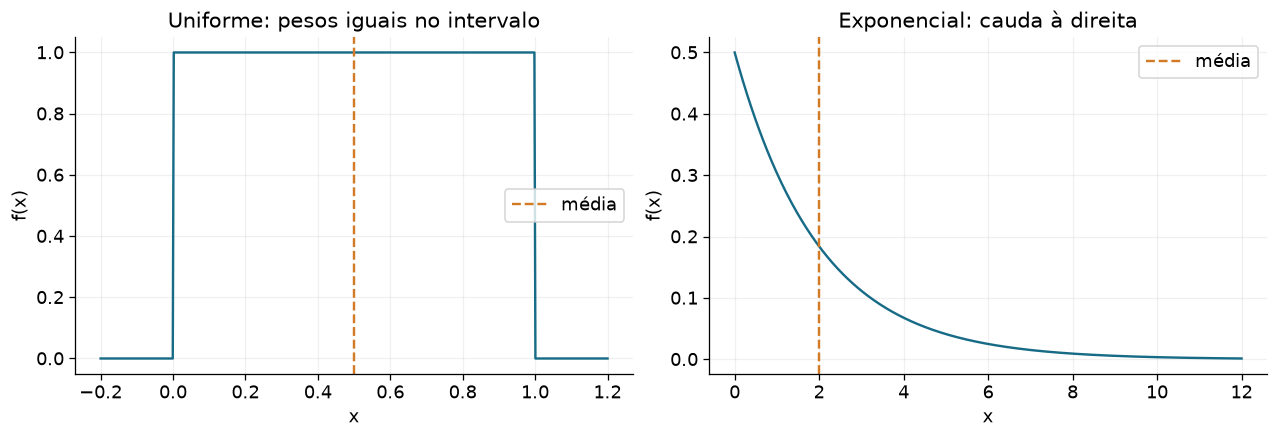

In [3]:
# Integramos cada potência e comparamos com a fórmula analítica.
theta_momento = 2.0
linhas = []
for nome, dist, limites, formula in [
    ('Uniforme U(0,1)', stats.uniform(), (0, 1), lambda r: 1/(r+1)),
    ('Exponencial, θ=2', stats.expon(scale=theta_momento), (0, np.inf),
     lambda r: math.factorial(r)*theta_momento**r),
]:
    momentos = [integrate.quad(lambda x: x**r*dist.pdf(x), *limites)[0] for r in range(5)]
    media = momentos[1]
    centrais = [integrate.quad(lambda x: (x-media)**r*dist.pdf(x), *limites)[0] for r in range(1, 5)]
    conferir(f'momentos por quadratura: {nome}', momentos, [formula(r) for r in range(5)])
    conferir(f'variância por duas rotas: {nome}', centrais[1], momentos[2]-media**2)
    linhas.append({'distribuição': nome, 'm₁': media, 'm₂': momentos[2],
                   'm₃': momentos[3], 'm₄': momentos[4], 'μ₂': centrais[1],
                   'μ₃': centrais[2], 'μ₄': centrais[3]})
tabela(linhas)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, dist, xx, titulo in [
    (axs[0], stats.uniform(), np.linspace(-.2, 1.2, 500), 'Uniforme: pesos iguais no intervalo'),
    (axs[1], stats.expon(scale=theta_momento), np.linspace(0, 12, 500), 'Exponencial: cauda à direita'),
]:
    ax.plot(xx, dist.pdf(xx))
    ax.axvline(dist.mean(), color=CORES[1], ls='--', label='média')
    ax.set(title=titulo, xlabel='x', ylabel='f(x)'); ax.legend()
finalizar(fig, '02_momentos_uniforme_exponencial')


### 1.3 Média, mediana e moda respondem a perguntas diferentes

A **média** $\mu=\int xf_X(x)dx$ leva em conta a posição de todos os valores, ponderada por probabilidade. A **mediana** $q_{0.5}$ divide a probabilidade em duas metades. Para uma CDF contínua e estritamente crescente, $F_X(q_{0.5})=1/2$. No caso geral, uma mediana satisfaz $P(X\leq q_{0.5})=1/2$ e $P(X\geq q_{0.5})=1/2$.

A **moda** é um máximo global da PMF ou PDF. Pode haver mais de uma moda. A condição $f'(x)=0$ ajuda em um máximo interior diferenciável, mas não contempla sozinha máximos nas bordas, distribuições uniformes ou vários picos (mais de um máximo).

Vamos usar a forma do exemplo do slide 14:

$$f_X(x)=30x(1-x)^4,\qquad 0<x<1.$$

Ela está normalizada porque $\int_0^1 x(1-x)^4dx=1/30$. Não precisamos dar um nome novo a essa distribuição para estudá-la agora. Expandindo $(1-x)^4$, podemos fazer todas as integrais como polinômios. Obtemos

$$\mu=30\int_0^1x^2(1-x)^4dx=\frac27,$$
$$f'_X(x)=30(1-x)^3(1-5x)\ \Rightarrow\ x_{\rm moda}=\frac15,$$
$$F_X(x)=1-(1-x)^5(1+5x).$$

Para a mediana, resolvemos $1-(1-q)^5(1+5q)=1/2$ numericamente. Aqui teremos moda $<$ mediana $<$ média. A cauda direita desloca a média, mas vamos conferir adiante por que essa ordem **não é um teorema geral sobre skewness**.

Outra interpretação útil: a média minimiza $\mathbb E[(X-a)^2]$ em relação a $a$ (a que deve ser escolhido para minimizar o erro - desvio padrão ), pois a derivada é $2(a-\mu)$. Uma mediana minimiza $\mathbb E[|X-a|]$, quando essa esperança existe - note que o módulo da função garante que estamos escolhendo o a que minimiza a distância entre os valores esperados, isso é a mediana.; para uma densidade contínua, a derivada é $P(X<a)-P(X>a)=2F_X(a)-1$, igualando a 0, obtemos $F_x(a)=\frac12$. A escolha depende da perda que faz sentido no problema.


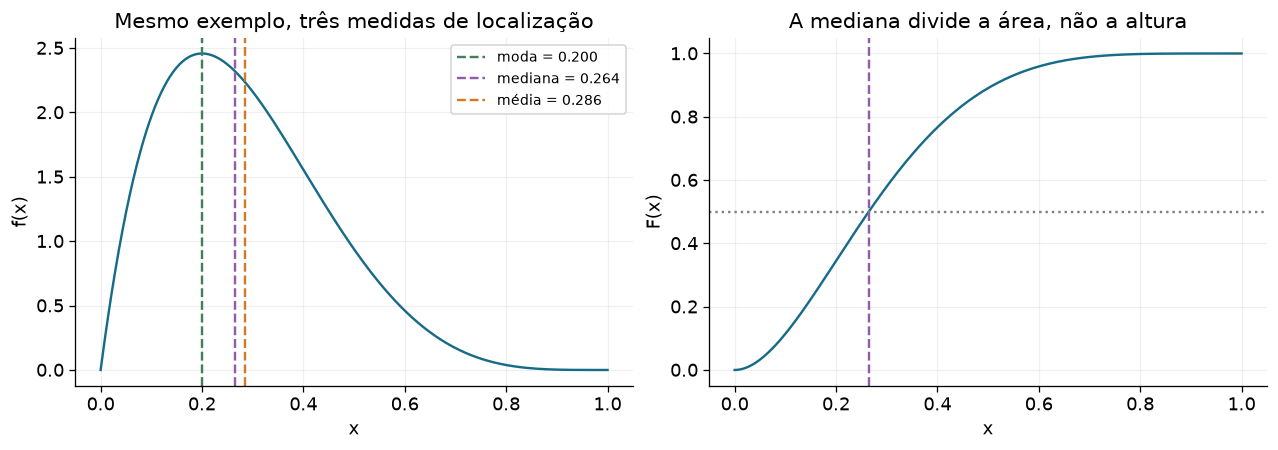

In [4]:
# O exemplo é calculado diretamente; depois reconheceremos a família Beta.
f_pol = lambda x: 30*x*(1-x)**4 if 0 <= x <= 1 else 0.
F_pol = lambda x: 1-(1-x)**5*(1+5*x)
media_pol = integrate.quad(lambda x: x*f_pol(x), 0, 1)[0]
mediana_pol = optimize.brentq(lambda x: F_pol(x)-.5, 0, 1)
moda_pol = .2
conferir('normalização do exemplo polinomial', integrate.quad(f_pol, 0, 1)[0], 1)
conferir('média do exemplo polinomial', media_pol, 2/7)
xx = np.linspace(0, 1, 700)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(xx, 30*xx*(1-xx)**4)
for valor, nome, cor in [(moda_pol, 'moda', CORES[2]), (mediana_pol, 'mediana', CORES[3]), (media_pol, 'média', CORES[1])]:
    axs[0].axvline(valor, color=cor, ls='--', label=f'{nome} = {valor:.3f}')
axs[0].set(title='Mesmo exemplo, três medidas de localização', xlabel='x', ylabel='f(x)')
axs[0].legend(fontsize=9)
axs[1].plot(xx, F_pol(xx)); axs[1].axhline(.5, color='gray', ls=':')
axs[1].axvline(mediana_pol, color=CORES[3], ls='--')
axs[1].set(title='A mediana divide a área, não a altura', xlabel='x', ylabel='F(x)')
finalizar(fig, '03_media_mediana_moda')


### 1.4 Skewness: o que o sinal permite afirmar?

Quando $0<\sigma^2<\infty$, podemos definir $Z=(X-\mu)/\sigma$. Então $\mathbb E[Z]=0$ e $\mathbb E[Z^2]=1$. O coeficiente de **skewness**, ou assimetria padronizada, é

$$\gamma_1=\mathbb E[Z^3]=\frac{\mu_3}{\sigma^3}.$$

Valores acima da média contribuem positivamente; abaixo dela, negativamente. O cubo dá peso grande a desvios grandes. Uma distribuição simétrica em torno da média tem $\gamma_1=0$, se esse momento existe. A recíproca não vale: contribuições distintas podem se cancelar sem a distribuição ser simétrica.

**A dúvida sobre média e moda.** Não podemos provar que $\gamma_1>0$ sempre implica média $>$ moda, porque a afirmação é falsa em geral. A skewness compara o terceiro momento em torno da média; a moda depende de onde a massa ou densidade atinge seu máximo. São informações diferentes.

Um contraexemplo direto:

$$P(X=-2)=0.48,\qquad P(X=0)=0.50,\qquad P(X=10)=0.02.$$

Temos moda $=0$, mediana $=0$ e média $=-0.76$. Porém,

$$\mu_3=0.48(-2+0.76)^3+0.50(0+0.76)^3+0.02(10+0.76)^3
=24.219648>0.$$

A rara ocorrência em 10 pesa muito no cubo; a massa em $-2$ ainda deixa a média abaixo da moda. Se trocarmos $X$ por $-X$, obtemos skewness negativa com média **acima** da moda.

Também podemos ter skewness zero sem simetria: massas $0.4,0.5,0.1$ em $-2,1,3$ dão média 0 e terceiro momento $-3.2+0.5+2.7=0$. Vamos mostrar os dois casos. As ordens familiares entre média, mediana e moda são úteis em famílias específicas, mas não devem substituir a distribuição completa.


,exemplo,média,mediana,moda,variância,μ₃,skewness
0,"Skewness positiva, média < moda",-0.76,0.0,0.0,3.3424,24.219648,3.963512
1,"Skewness zero, distribuição assimétrica",0.00,1.0,1.0,3.0000,0.000000,0.000000


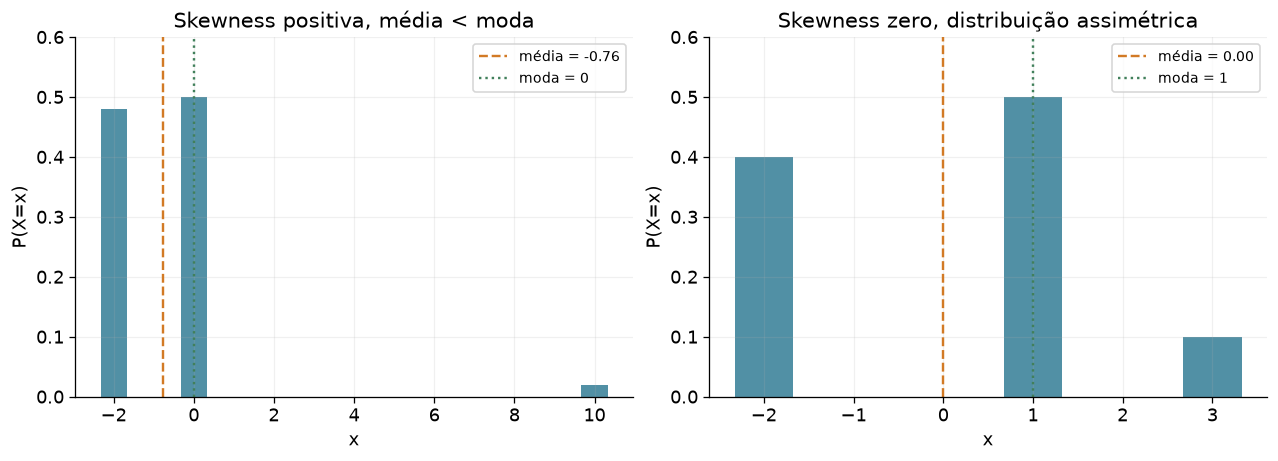

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
linhas = []
for ax, valores, probs, nome in [
    (axs[0], np.array([-2., 0., 10.]), np.array([.48, .50, .02]), 'Skewness positiva, média < moda'),
    (axs[1], np.array([-2., 1., 3.]), np.array([.4, .5, .1]), 'Skewness zero, distribuição assimétrica'),
]:
    mu = probs @ valores
    var = probs @ (valores-mu)**2
    mu3 = probs @ (valores-mu)**3
    med = valores[np.searchsorted(np.cumsum(probs), .5)]
    moda = valores[np.argmax(probs)]
    ax.bar(valores, probs, width=.65, alpha=.75)
    ax.axvline(mu, color=CORES[1], ls='--', label=f'média = {mu:.2f}')
    ax.axvline(moda, color=CORES[2], ls=':', label=f'moda = {moda:.0f}')
    ax.set(title=nome, xlabel='x', ylabel='P(X=x)', ylim=(0, .6)); ax.legend(fontsize=9)
    linhas.append({'exemplo': nome, 'média': mu, 'mediana': med, 'moda': moda, 'variância': var, 'μ₃': mu3, 'skewness': mu3/var**1.5})
conferir('terceiro momento do contraexemplo', linhas[0]['μ₃'], 24.219648)
conferir('skewness zero não implica simetria', linhas[1]['μ₃'], 0)
tabela(linhas)
finalizar(fig, '04_contraexemplos_skewness')


### 1.5 Kurtosis e valores extremos

Vamos usar duas quantidades e manter os nomes separados:

$$\beta_2=\mathbb E[Z^4]=\frac{\mu_4}{\sigma^4}
\quad\text{(kurtosis de Pearson)},\qquad
\gamma_2=\beta_2-3\quad\text{(excesso de kurtosis)}.$$

Nos slides, $\alpha_3$ corresponde à nossa $\gamma_1$ e $\alpha_4$ à nossa $\beta_2$. Aqui $\beta_2$ é um coeficiente; mais adiante $\beta$ será um parâmetro da distribuição Beta, e $B(a,b)$ será uma função. São objetos diferentes.

Por que a kurtosis tem relação com outliers? Um desvio de $5\sigma$ contribui com $5^4=625$ para $Z^4$, enquanto um desvio de $1\sigma$ contribui com 1. Uma probabilidade pequena em valores muito distantes pode pesar muito nesse momento. Um valor extremo não é automaticamente um erro: pode ser um resultado permitido pelo modelo ou indicar que o modelo não descreve bem os dados.

A Gaussiana tem $\beta_2=3$. A uniforme tem $\beta_2=9/5$ e a Laplace, cuja PDF é $f(x)=e^{-|x|/b}/(2b)$, tem $\beta_2=6$. Para comparar as formas, vamos padronizar todas para média 0 e variância 1.

Vamos também usar uma mistura: com probabilidade $1-\varepsilon$, $X\sim\mathcal N(0,1)$; com probabilidade $\varepsilon$, $X\sim\mathcal N(0,L^2)$. Então

$$\sigma^2=(1-\varepsilon)+\varepsilon L^2,$$
$$\mu_4=3[(1-\varepsilon)+\varepsilon L^4],\qquad
\beta_2=\frac{3[(1-\varepsilon)+\varepsilon L^4]}{[(1-\varepsilon)+\varepsilon L^2]^2}.$$

Com $\varepsilon=0.01$ e $L=10$, a kurtosis é grande. Não vamos interpretar $\beta_2$ apenas como “altura do pico”: ele é uma média de desvios à quarta potência. Também não determina sozinho a probabilidade de ultrapassar **um limiar específico** como $3\sigma$. Essa probabilidade deve ser calculada pela CDF ou cauda da distribuição.

A desigualdade de Markov dá uma conexão precisa, embora geralmente frouxa:

$$P(|Z|>a)=P(Z^4>a^4)\leq\frac{\mathbb E[Z^4]}{a^4}=\frac{\beta_2}{a^4},\qquad a>0.$$

Na prática, kurtosis e skewness calculadas em uma amostra finita também flutuam e são sensíveis a poucas observações. Aqui começamos pelos coeficientes **da distribuição**, que conhecemos no modelo.


,distribuição,kurtosis β₂,excesso γ₂,P(|Z|>3)
0,Gaussiana,3.000000,0.000000,0.002700
1,Uniforme,1.800000,-1.200000,0.000000
2,Laplace,6.000000,3.000000,0.014370
3,Mistura com 1% de componente larga,76.505644,73.505644,0.006744


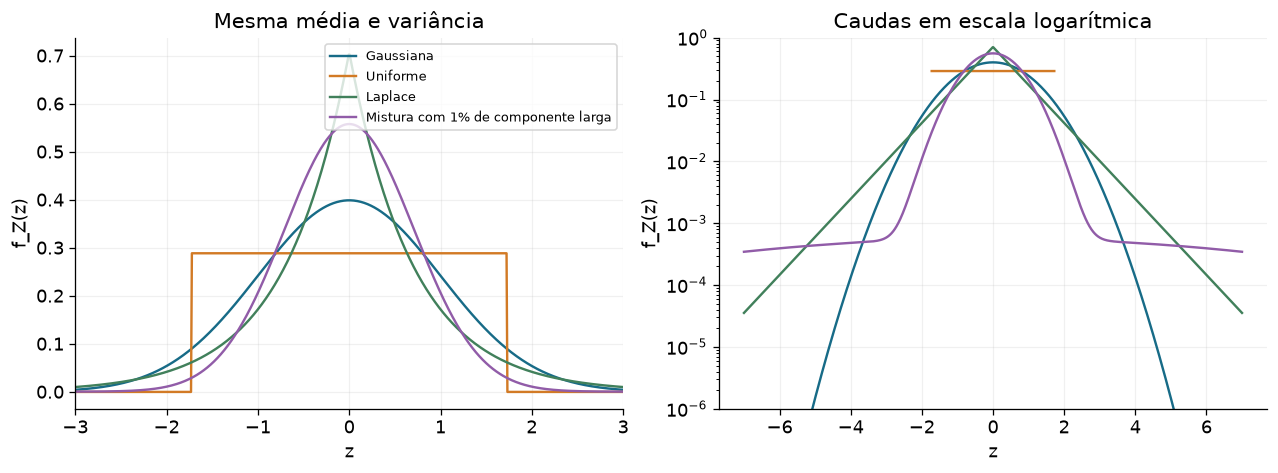

In [6]:
eps_cauda, L_cauda = .01, 10.
sig_mix = np.sqrt((1-eps_cauda)+eps_cauda*L_cauda**2)
pdf_mix = lambda z: sig_mix*((1-eps_cauda)*stats.norm.pdf(sig_mix*z)
                            +eps_cauda*stats.norm.pdf(sig_mix*z, scale=L_cauda))
kurt_mix = 3*((1-eps_cauda)+eps_cauda*L_cauda**4)/sig_mix**4
modelos_cauda = [
    ('Gaussiana', stats.norm().pdf, 3., 2*stats.norm.sf(3)),
    ('Uniforme', stats.uniform(-np.sqrt(3), 2*np.sqrt(3)).pdf, 1.8, 0.),
    ('Laplace', stats.laplace(scale=1/np.sqrt(2)).pdf, 6., 2*stats.laplace.sf(3, scale=1/np.sqrt(2))),
    ('Mistura com 1% de componente larga', pdf_mix, kurt_mix,
     2*((1-eps_cauda)*stats.norm.sf(3*sig_mix)+eps_cauda*stats.norm.sf(3*sig_mix/L_cauda))),
]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
zz = np.linspace(-7, 7, 1500)
for nome, pdf, kurt, cauda in modelos_cauda:
    valores_pdf = pdf(zz)
    axs[0].plot(zz, valores_pdf, label=nome)
    axs[1].semilogy(zz, np.where(valores_pdf > 0, valores_pdf, np.nan), label=nome)
axs[0].set(xlim=(-3, 3), title='Mesma média e variância', xlabel='z', ylabel='f_Z(z)')
axs[1].set(ylim=(1e-6, 1), title='Caudas em escala logarítmica', xlabel='z', ylabel='f_Z(z)')
axs[0].legend(fontsize=8)
tabela([{'distribuição': n, 'kurtosis β₂': k, 'excesso γ₂': k-3, 'P(|Z|>3)': c} for n, _, k, c in modelos_cauda])
conferir('quarto momento da mistura por integração', integrate.quad(lambda z: z**4*pdf_mix(z), -np.inf, np.inf)[0], kurt_mix)
finalizar(fig, '05_kurtosis_e_caudas')


### 1.6 E quando a média não existe?

Ainda podemos caracterizar a distribuição. A média é uma forma de resumir a localização, não uma condição para existir uma distribuição. A PDF, a CDF, os quantis, a mediana e a função característica continuam sendo úteis.

Um exemplo é a **Cauchy**, também chamada de Lorentziana:

$$f_X(x)=\frac{s}{\pi[(x-x_0)^2+s^2]},\qquad s>0.$$

$x_0$ é a localização do pico e da mediana; $s$ é um parâmetro de escala, **não** um desvio padrão. Sua CDF é

$$F_X(x)=\frac12+\frac1\pi\arctan\left(\frac{x-x_0}{s}\right).$$

Para $x_0=0$ e $s=1$, uma integral simétrica de $xf_X(x)$ entre $-A$ e $A$ dá zero, mas isso é um **valor principal**, não a esperança. A contribuição positiva é

$$\int_0^A\frac{x}{\pi(1+x^2)}dx=\frac{\ln(1+A^2)}{2\pi}\longrightarrow\infty.$$

A contribuição negativa diverge no outro sentido. Não podemos definir a média cancelando $+\infty$ e $-\infty$. A variância e os coeficientes de skewness/kurtosis usados acima também não existem. Ser simétrica não resolve a inexistência desses momentos.

Já o quantil de ordem $u$, $0<u<1$, é

$$q_u=x_0+s\tan[\pi(u-1/2)].$$

Temos mediana $x_0$ e intervalo interquartil $q_{0.75}-q_{0.25}=2s$. Vamos visualizar a cauda e a divergência. Não usaremos uma integração numérica sobre um intervalo finito como prova de que a média existe.


,quantil u,q_u
0,0.25,-1.0
1,0.50,0.0
2,0.75,1.0


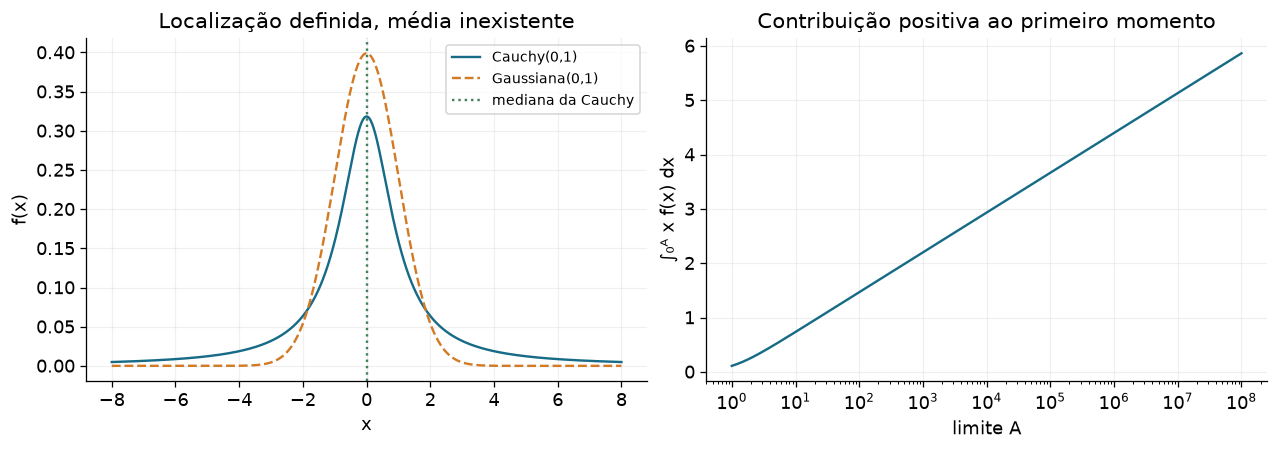

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
xx = np.linspace(-8, 8, 1200)
axs[0].plot(xx, stats.cauchy.pdf(xx), label='Cauchy(0,1)')
axs[0].plot(xx, stats.norm.pdf(xx), ls='--', label='Gaussiana(0,1)')
axs[0].axvline(0, color=CORES[2], ls=':', label='mediana da Cauchy')
axs[0].set(title='Localização definida, média inexistente', xlabel='x', ylabel='f(x)'); axs[0].legend(fontsize=9)
A = np.logspace(0, 8, 300)
axs[1].semilogx(A, np.log1p(A**2)/(2*np.pi))
axs[1].set(title='Contribuição positiva ao primeiro momento', xlabel='limite A', ylabel='∫₀ᴬ x f(x) dx')
tabela([{'quantil u': u, 'q_u': stats.cauchy.ppf(u)} for u in [.25, .5, .75]])
finalizar(fig, '06_cauchy_sem_media')


### 1.7 Fundo, sinal e ruído: o que a janela móvel faz?

Nos slides 16–17 e em Gregory §5.5.4, o detector registra picos estreitos sobre um fundo que varia lentamente. Vamos escrever

$$d_i=b_i+s_i+\eta_i.$$

$d_i$ é a medida no índice $i$; $b_i$ é o fundo ou baseline; $s_i$ é o sinal que queremos preservar; $\eta_i$ é o ruído aleatório, aqui com média 0 e desvio padrão $\sigma_\eta$. **Fundo e ruído são coisas diferentes.** Subtrair uma estimativa de $b_i$ ainda deixa $s_i+\eta_i$ e possíveis erros da estimativa.

Escolhemos uma janela com número ímpar de pontos $W=2h+1$, centrada em $i$:

$$\mathcal J_i=\{i-h,\ldots,i+h\},\qquad
\widehat b_i^{\rm med}=\operatorname{mediana}\{d_j:j\in\mathcal J_i\}.$$

Ela é **móvel** porque deslocamos o centro de um ponto a cada passo. O residual é $r_i=d_i-\widehat b_i$. A média móvel usa $\widehat b_i^{\rm mean}=W^{-1}\sum_{j\in\mathcal J_i}d_j$.

Para funcionar bem, queremos que a largura dos picos seja menor que a janela, e que a janela seja curta diante da escala de variação do fundo. Na janela, o sinal deve ocupar uma fração suficientemente pequena dos pontos. Se um sinal largo ocupa a maioria, a mediana também pode absorvê-lo.

Agora a relação com $S/N$: para um pico de amplitude $A$ em apenas um dos $W$ pontos, a média local aumenta em **$A/W$**. Se o ponto atravessa a posição central da lista ordenada, a mediana pode mudar para o próximo valor central; depois que esse ponto fica entre os maiores, aumentá-lo mais não continua deslocando a mediana. Essa é a robustez usada no exemplo. A frase “não depende de $S/N$” é uma aproximação para picos suficientemente altos e esparsos; não significa que qualquer mediana seja imune a qualquer sinal.

Vamos fazer duas visualizações: o efeito da amplitude em uma janela fixa com 21 pontos e a subtração ao longo de um espectro completo. Usaremos o mesmo ruído ao variar $A$, para isolar seu efeito. Nas bordas, a implementação abaixo reflete os dados; a escolha de tratamento das bordas faz parte do filtro.


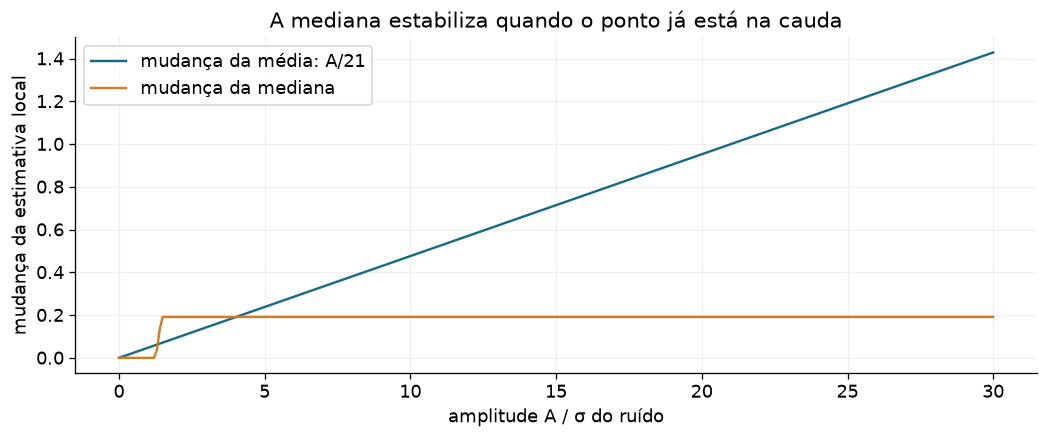

In [8]:
# Uma janela fixa: um único ponto recebe o sinal.
rng_janela = np.random.default_rng(5007)
janela = rng_janela.normal(0, 1, 21)
janela[10] = -1.8
amplitudes = np.linspace(0, 30, 301)
media_base, mediana_base = janela.mean(), np.median(janela)
mudanca_media, mudanca_mediana = [], []
for amplitude in amplitudes:
    contaminada = janela.copy(); contaminada[10] += amplitude
    mudanca_media.append(contaminada.mean()-media_base)
    mudanca_mediana.append(np.median(contaminada)-mediana_base)
conferir('um pico altera a média em A/W', mudanca_media, amplitudes/21)
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.plot(amplitudes, mudanca_media, label='mudança da média: A/21')
ax.plot(amplitudes, mudanca_mediana, label='mudança da mediana')
ax.set(title='A mediana estabiliza quando o ponto já está na cauda', xlabel='amplitude A / σ do ruído', ylabel='mudança da estimativa local')
ax.legend(); finalizar(fig, '07_uma_janela_e_amplitude')


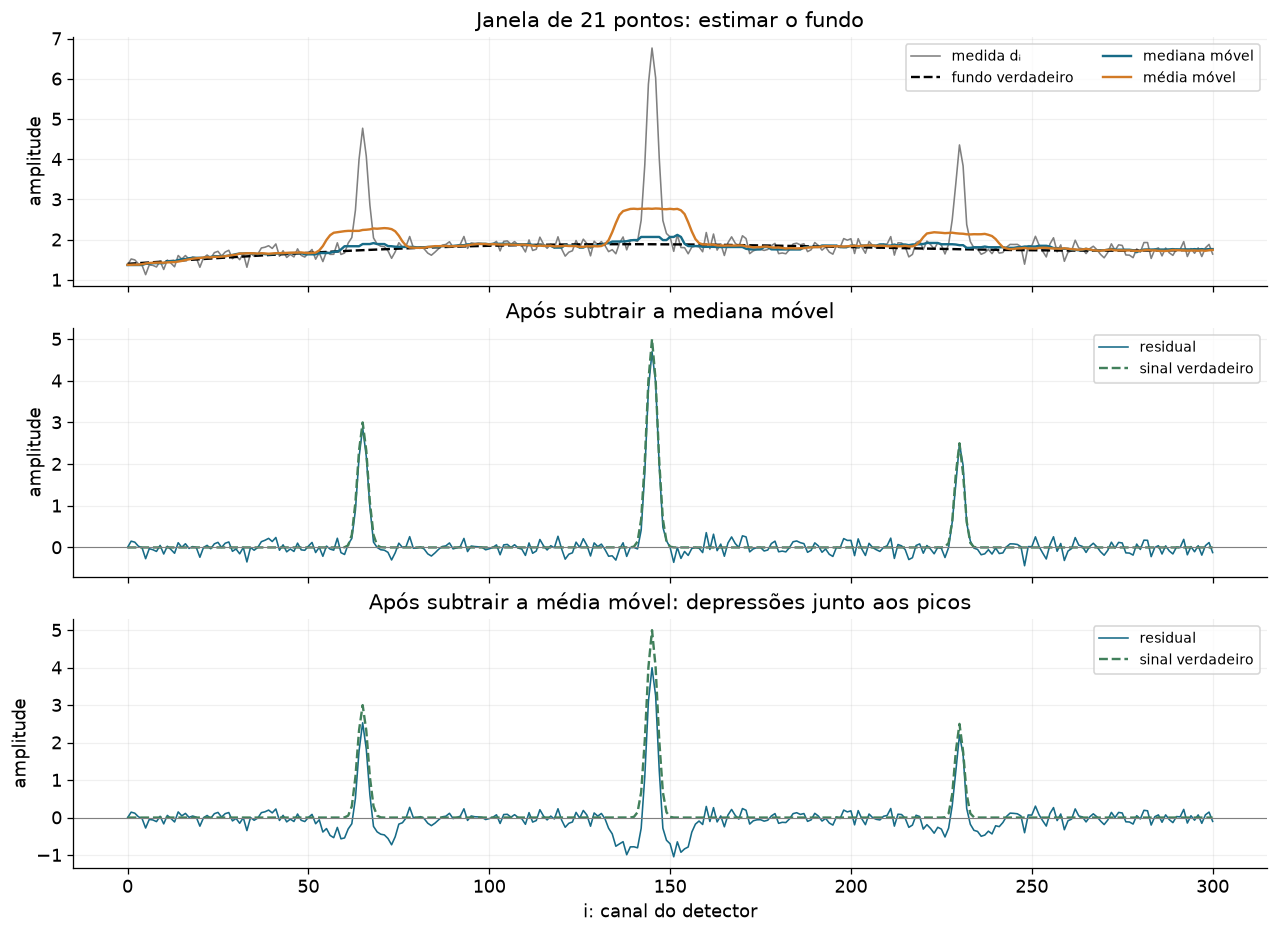

In [14]:
# Espectro simulado: fundo lento, três picos e ruído.
rng_fundo = np.random.default_rng(5017)
indice = np.arange(301)
fundo = 1.4 + .002*indice + .25*np.sin(indice/65)
sinal_picos = sum(A*np.exp(-.5*((indice-c)/w)**2) for A, c, w in [(3., 65, 1.4), (5., 145, 1.5), (2.5, 230, 1.2)])
sigma_ruido = .12
dados_fundo = fundo+sinal_picos+rng_fundo.normal(0, sigma_ruido, indice.size)
W = 21
fundo_mediana = ndimage.median_filter(dados_fundo, size=W, mode='reflect')
fundo_media = ndimage.uniform_filter1d(dados_fundo, size=W, mode='reflect')
fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axs[0].plot(indice, dados_fundo, color='gray', lw=1, label='medida dᵢ')
axs[0].plot(indice, fundo, color='black', ls='--', label='fundo verdadeiro')
axs[0].plot(indice, fundo_mediana, label='mediana móvel')
axs[0].plot(indice, fundo_media, label='média móvel')
axs[0].set(title='Janela de 21 pontos: estimar o fundo', ylabel='amplitude'); axs[0].legend(ncol=2, fontsize=9)
for ax, estimativa, titulo in [(axs[1], fundo_mediana, 'Após subtrair a mediana móvel'), (axs[2], fundo_media, 'Após subtrair a média móvel: depressões junto aos picos')]:
    ax.plot(indice, dados_fundo-estimativa, lw=1, label='residual')
    ax.plot(indice, sinal_picos, color=CORES[2], ls='--', label='sinal verdadeiro')
    ax.axhline(0, color='gray', lw=.7); ax.set(title=titulo, ylabel='amplitude'); ax.legend(fontsize=9)
axs[-1].set_xlabel('i: canal do detector')
finalizar(fig, '08_subtracao_fundo_movel')


**Como ler os dois exemplos.** Na janela fixa, o deslocamento da mediana satura, enquanto o da média cresce linearmente com a amplitude. No espectro, a média móvel absorve parte dos picos e eleva a estimativa do fundo nas vizinhanças; subtraí-la produz uma depressão negativa. A mediana preserva melhor os picos estreitos neste caso, mas os residuais continuam ruidosos.

O residual filtrado também pode ter correlações entre canais, porque janelas vizinhas compartilham dados. Em uma aplicação quantitativa, precisamos estudar a resposta do filtro, o viés no sinal e a covariância dos residuais. Para GW–galáxias, há uma conexão útil de raciocínio: remover um fundo ou tendência pode alterar o sinal e a covariância.

**Para modificar:** experimente $W=7$ e $W=81$, depois aumente a largura de um pico para 20 canais. Observe quando a hipótese de sinal estreito deixa de valer.

## Bloco 2 — Uma função que reúne os momentos
### 2.1 Função geradora de momentos: por que ela funciona?

A **função geradora de momentos**, abreviada MGF, é

$$M_X(t)=\mathbb E[e^{tX}]=\sum_x e^{tx}p_X(x)
\quad\text{ou}\quad M_X(t)=\int_{-\infty}^\infty e^{tx}f_X(x)\,dx.$$

$t$ é uma variável auxiliar. Se $X$ tem unidades, $t$ tem unidades inversas às de $X$, para que $tX$ seja adimensional. A MGF existe no sentido usado aqui quando é finita em alguma vizinhança aberta de $t=0$. O fato de $M_X(0)=1$ sozinho não basta.

Por que as derivadas produzem momentos? A expansão do exponencial é

$$e^{tX}=1+tX+\frac{t^2X^2}{2!}+\frac{t^3X^3}{3!}+\cdots.$$

Quando a MGF existe perto de zero, podemos tomar a esperança termo a termo nessa região:

$$M_X(t)=1+m_1t+\frac{m_2t^2}{2!}+\frac{m_3t^3}{3!}+\cdots.$$

Derivar $r$ vezes e avaliar em zero elimina os outros termos, deixando

$$M_X^{(r)}(0)=m_r.$$

Também podemos ver isso diretamente: $d^re^{tX}/dt^r=X^re^{tX}$, e em $t=0$ sobra $X^r$. A condição de existência justifica trocar derivada e integral.

Para os momentos centrais, precisamos primeiro **centrar a variável**:

$$M_{X-\mu}(t)=\mathbb E[e^{t(X-\mu)}]=e^{-\mu t}M_X(t),
\qquad M_{X-\mu}^{(r)}(0)=\mu_r.$$

Observe que centrar a MGF não é tomar seu logaritmo (veremos mais adiante com a transformada). São operações diferentes, que vamos relacionar já a seguir.

**Exemplo do slide 19: exponencial.** Com $f_X(x)=\theta^{-1}e^{-x/\theta}$, $x>0$,

$$M_X(t)=\frac1\theta\int_0^\infty e^{-(1/\theta-t)x}dx
=\frac1{1-\theta t},\qquad t<1/\theta.$$

A integral converge somente se $1/\theta-t>0$. Fazendo as derivadas,

$$M'_X(t)=\frac{\theta}{(1-\theta t)^2},\qquad
M''_X(t)=\frac{2\theta^2}{(1-\theta t)^3}.$$

Logo $\mu=\theta$, $m_2=2\theta^2$ e $\sigma^2=2\theta^2-\theta^2=\theta^2$. A série geométrica $M_X(t)=\sum_{r=0}^\infty(\theta t)^r$ também recupera $m_r=r!\theta^r$ ao comparar com a expansão acima.


,t,integral,fórmula
0,-0.3,0.625000,0.625000
1,0.0,1.000000,1.000000
2,0.2,1.666667,1.666667
3,0.4,5.000000,5.000000


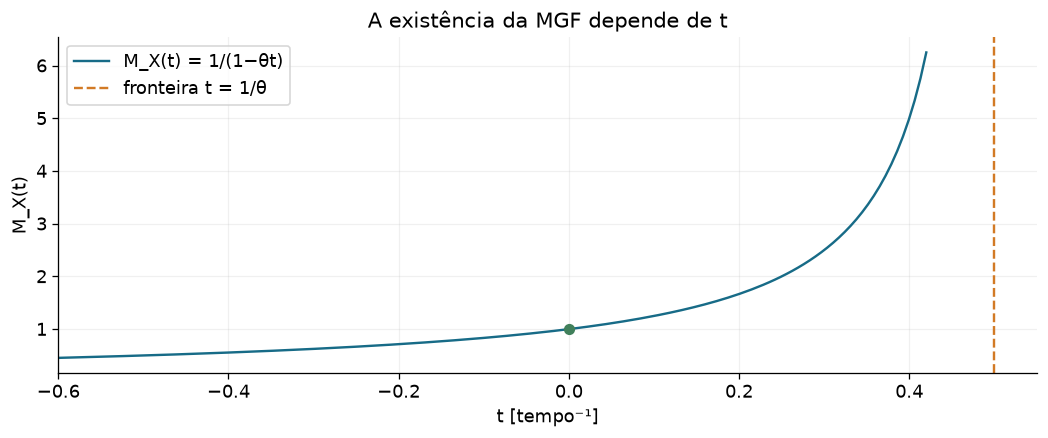

In [15]:
# A integral da definição e a expressão fechada devem concordar.
theta_mgf = 2.0
t_mgf = np.linspace(-.6, .42, 150)
M_exp = lambda t: 1/(1-theta_mgf*t)
resultados_mgf = []
for t in [-.3, 0., .2, .4]:
    valor_integral = integrate.quad(lambda x: np.exp(-(1/theta_mgf-t)*x)/theta_mgf, 0, np.inf)[0]
    conferir(f'MGF exponencial por integração, t={t}', valor_integral, M_exp(t))
    resultados_mgf.append({'t': t, 'integral': valor_integral, 'fórmula': M_exp(t)})
tabela(resultados_mgf)
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.plot(t_mgf, M_exp(t_mgf), label='M_X(t) = 1/(1−θt)')
ax.axvline(1/theta_mgf, color=CORES[1], ls='--', label='fronteira t = 1/θ')
ax.scatter([0], [1], color=CORES[2], zorder=3)
ax.set(title='A existência da MGF depende de t', xlabel='t [tempo⁻¹]', ylabel='M_X(t)', xlim=(-.6, .55))
ax.legend(); finalizar(fig, '09_mgf_exponencial')


### 2.2 Cumulantes: por que tomar o logaritmo?

Definimos a **função geradora de cumulantes** por

$$K_X(t)=\ln M_X(t)=\sum_{r=1}^\infty\kappa_r\frac{t^r}{r!}.$$

$\kappa_r=K_X^{(r)}(0)$ é o cumulante de ordem $r$, note que $\kappa_0=0$. Se $X$ e $Y$ são independentes,

$$M_{X+Y}(t)=\mathbb E[e^{tX}e^{tY}]=M_X(t)M_Y(t),$$
$$K_{X+Y}(t)=K_X(t)+K_Y(t).$$

Portanto **cumulantes de variáveis independentes somam**. Essa propriedade vai explicar os limites gaussianos e a soma das fontes de incerteza do capítulo anterior.

Vamos relacioná-los aos momentos sem pular a conta. Escreva $K=\ln M$, logo $M=e^K$. Derivando,

$$M'=K'M,$$
$$M''=[K''+(K')^2]M,$$
$$M^{(3)}=[K^{(3)}+3K'K''+(K')^3]M,$$
$$M^{(4)}=[K^{(4)}+4K'K^{(3)}+3(K'')^2+6(K')^2K''+(K')^4]M.$$

Em $t=0$, $M(0)=1$, $M^{(r)}(0)=m_r$ e $K^{(r)}(0)=\kappa_r$. Assim,

$$m_1=\kappa_1,\qquad m_2=\kappa_2+\kappa_1^2,$$
$$m_3=\kappa_3+3\kappa_1\kappa_2+\kappa_1^3,$$
$$m_4=\kappa_4+4\kappa_1\kappa_3+3\kappa_2^2+6\kappa_1^2\kappa_2+\kappa_1^4.$$

Ao centrar a variável, sua geradora é $K_{X-\mu}(t)=K_X(t)-\mu t$, isso faz com que $K_{X-\mu \mid 1}=0$. = É mais interessante olhar par ao próprio $K_{X}(t)$ centrado em zero. O que encontramos é:

$$\boxed{\kappa_1=\mu,\quad\kappa_2=\sigma^2=\mu_2,\quad
\kappa_3=\mu_3,\quad\kappa_4=\mu_4-3\mu_2^2.}$$

Note que os 3 primeiros cumulantes são exatamente os momentos já centrados da distribuição. O quarto cumulante não é o quarto momento central. A diferença $3\sigma^4$ é justamente a contribuição que resta para uma Gaussiana, que tem $\kappa_r=0$ para $r\geq3$, diferenciando as Leptkurtikas e platykurticas. Portanto

$$\gamma_1=\frac{\kappa_3}{\kappa_2^{3/2}},\qquad
\gamma_2=\frac{\kappa_4}{\kappa_2^2}.$$

Para obter ordens maiores sem inventar novas regras, derivamos $M'=K'M$ repetidamente. A regra do produto fornece a recorrência

$$m_r=\sum_{j=1}^r\binom{r-1}{j-1}\kappa_jm_{r-j},\qquad m_0=1.$$

O termo $j=r$ é $\kappa_r$, então podemos isolá-lo. A mesma recorrência vale para momentos centrais se usarmos $\kappa_1=0$. Por exemplo, $\mu_5=\kappa_5+10\kappa_2\kappa_3$. Vamos usar essa conta para conferir os cumulantes da exponencial.


In [16]:
def cumulantes_de_momentos(momentos):
    """momentos[r] contém E[X**r], começando em momentos[0]=1."""
    cumulantes = np.zeros(len(momentos))
    for r in range(1, len(momentos)):
        termos_anteriores = sum(math.comb(r-1, j-1)*cumulantes[j]*momentos[r-j]
                               for j in range(1, r))
        cumulantes[r] = momentos[r]-termos_anteriores
    return cumulantes

theta_cum = 1.7
momentos_exp = [integrate.quad(lambda x: x**r*np.exp(-x/theta_cum)/theta_cum, 0, np.inf)[0]
                for r in range(6)]
kappas_exp = cumulantes_de_momentos(momentos_exp)
# K(t) = −ln(1−θt) = Σ (θt)^r/r; portanto κ_r = (r−1)! θ^r.
kappas_teoria = [math.factorial(r-1)*theta_cum**r for r in range(1, 6)]
conferir('cumulantes da exponencial por momentos', kappas_exp[1:], kappas_teoria)
tabela([{'ordem r': r, 'momento m_r': momentos_exp[r],
         'cumulante κ_r': kappas_exp[r], 'κ_r analítico': kappas_teoria[r-1]} for r in range(1, 6)])
print('κ₄ difere de μ₄; a recorrência evita confundir essas quantidades.')


,ordem r,momento m_r,cumulante κ_r,κ_r analítico
0,1,1.7000,1.70000,1.70000
1,2,5.7800,2.89000,2.89000
2,3,29.4780,9.82600,9.82600
3,4,200.4504,50.11260,50.11260
4,5,1703.8284,340.76568,340.76568


κ₄ difere de μ₄; a recorrência evita confundir essas quantidades.


### 2.3 $t=ik$: função característica e Fourier

Agora vamos fazer a conexão que motivou este bloco. Seja $i=\sqrt{-1}$ e $k\in\mathbb R$ uma variável auxiliar com unidades inversas às de $X$. Definimos a **função característica**

$$\varphi_X(k)=\mathbb E[e^{ikX}]=\int_{-\infty}^\infty e^{ikx}f_X(x)dx.$$

Essa é a transformada de Fourier da PDF na convenção com sinal positivo no expoente. Quando $\varphi$ é integrável, a inversa é

$$f_X(x)=\frac1{2\pi}\int_{-\infty}^\infty e^{-ikx}\varphi_X(k)dk.$$

Em condições mais gerais, a inversão exige uma interpretação apropriada; não precisamos dela para os exemplos abaixo. No caso discreto, usamos a mesma definição com uma soma.

Podemos escrever formalmente $\varphi_X(k)=M_X(ik)$ quando a expressão da MGF admite essa extensão. **A definição de $\varphi$ não depende de a MGF real existir.** Como $|e^{ikX}|=1$, $|\varphi_X(k)|\leq1$, e a função característica existe para toda distribuição de probabilidade, inclusive a Cauchy. Ela determina a distribuição de forma única.

Se $\mathbb E[|X|^r]<\infty$, então

$$\varphi_X^{(r)}(0)=i^r m_r,\qquad m_r=\frac{\varphi_X^{(r)}(0)}{i^r}.$$

O logaritmo de $\varphi$, escolhido continuamente perto de $k=0$ com $\log\varphi(0)=0$, gera os mesmos cumulantes nas ordens em que os momentos necessários existem:

$$\log\varphi_X(k)=i\mu k-\frac{\sigma^2k^2}{2}
 +\frac{\kappa_3(ik)^3}{3!}+\frac{\kappa_4(ik)^4}{4!}+\cdots.$$

Aqui a série completa requer condições de convergência; quando só alguns momentos existem, usamos uma expansão local até a ordem justificada. A parte real e a parte imaginária de $\varphi$ são $\mathbb E[\cos(kX)]$ e $\mathbb E[\sin(kX)]$.

Para a exponencial, $\varphi(k)=(1-i\theta k)^{-1}$. Para a Gaussiana, $\varphi(k)=e^{i\mu k-\sigma^2k^2/2}$. A Cauchy tem $\varphi(k)=e^{ix_0k-s|k|}$; o módulo de $k$ impede a derivada em zero que tentaríamos usar para obter a média.

Vamos conferir a exponencial pela média de senos e cossenos em amostras simuladas. A integral e a média amostral calculam o mesmo objeto, com precisões diferentes.


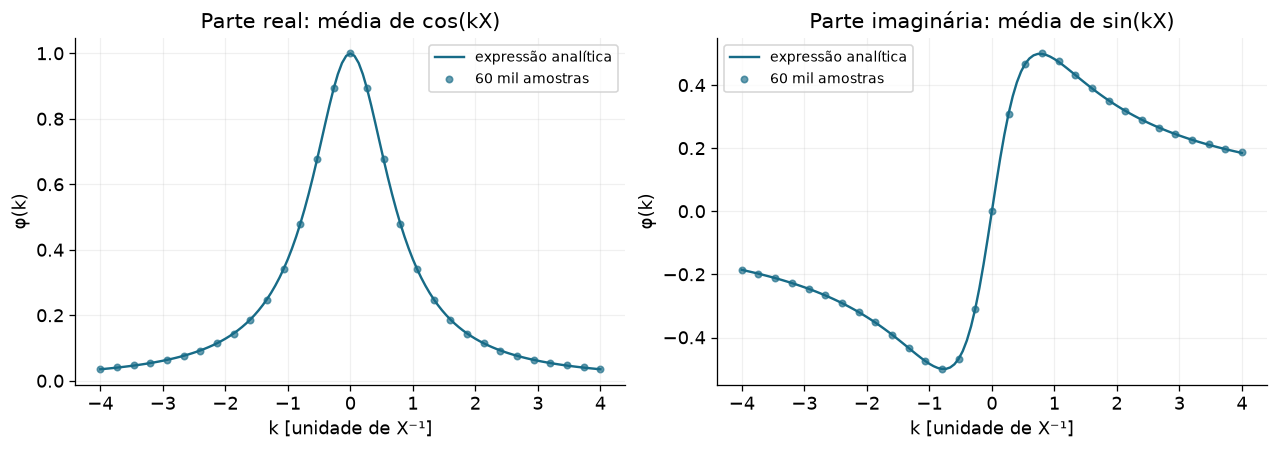

In [17]:
rng_fourier = np.random.default_rng(5023)
amostra_fourier = rng_fourier.exponential(scale=1.3, size=60000)
ks = np.linspace(-4, 4, 121)
phi_teoria = 1/(1-1j*1.3*ks)
phi_empirica = np.array([np.exp(1j*k*amostra_fourier).mean() for k in ks])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, parte, titulo in [(axs[0], np.real, 'Parte real: média de cos(kX)'), (axs[1], np.imag, 'Parte imaginária: média de sin(kX)')]:
    ax.plot(ks, parte(phi_teoria), label='expressão analítica')
    ax.scatter(ks[::4], parte(phi_empirica)[::4], s=16, alpha=.65, label='60 mil amostras')
    ax.set(title=titulo, xlabel='k [unidade de X⁻¹]', ylabel='φ(k)'); ax.legend(fontsize=9)
for k in [.4, 1.2]:
    phi_integral = (integrate.quad(lambda x: np.cos(k*x)*np.exp(-x/1.3)/1.3, 0, np.inf)[0]
                    +1j*integrate.quad(lambda x: np.sin(k*x)*np.exp(-x/1.3)/1.3, 0, np.inf)[0])
    conferir(f'função característica por integração, k={k}', phi_integral, 1/(1-1j*1.3*k))
finalizar(fig, '10_funcao_caracteristica')


**Conexão com a pesquisa.** Na função característica, fazemos Fourier da **distribuição de uma variável**. Em cosmologia também fazemos Fourier de um **campo no espaço**, como a densidade de galáxias. Os objetos não são os mesmos, mas a ideia de organizar informação em momentos conectados aparece nos dois casos.

Para variáveis centradas $A$ e $B$, o cumulante conjunto de segunda ordem é $\langle AB\rangle$, a covariância. Para quatro variáveis centradas, a parte conectada é

$$\langle ABCD\rangle_c=\langle ABCD\rangle
-\langle AB\rangle\langle CD\rangle
-\langle AC\rangle\langle BD\rangle
-\langle AD\rangle\langle BC\rangle.$$

Quando $A=B=C=D=X-\mu$, recuperamos $\kappa_4=\mu_4-3\sigma^4$. A correlação GW–galáxias é uma estatística de segunda ordem entre dois traçadores; a covariância dessa estatística pode envolver momentos de quarta ordem. Um modelo conjuntamente gaussiano elimina a parte conectada de quarta ordem, mas preserva os produtos das correlações de segunda ordem. Máscaras, ruído de contagem e não gaussianidade do campo precisam ser tratados no modelo apropriado.

O ponto útil agora é entender a subtração das partes desconectadas, sem assumir gaussianidade automaticamente.


## Bloco 3 — Distribuições e suas funções geradoras
### 3.1 Binomial: número de sucessos em $n$ tentativas

Fixamos $n$ tentativas independentes com probabilidade $p$ de sucesso, $0<p<1$. A variável $K$ conta os sucessos. Os resultados possíveis são $k=0,\ldots,n$:

$$P(K=k)=\binom nk p^k(1-p)^{n-k}.$$

Uma sequência específica com $k$ sucessos tem probabilidade $p^k(1-p)^{n-k}$. O fator $\binom nk=n!/[k!(n-k)!]$ conta quantas sequências possuem essa contagem. A normalização segue de $\sum_k\binom nk p^k(1-p)^{n-k}=[p+(1-p)]^n=1$.

Se $B_i$ vale 1 no sucesso e 0 no fracasso, $K=\sum_iB_i$. A MGF (moment generating function) de um ensaio é $M_{B_i}(t)=1-p+pe^t$. Pela independência,

$$M_K(t)=(1-p+pe^t)^n,\qquad K_K(t)=n\ln(1-p+pe^t).$$

Aqui $K_K(t)$ é a geradora de cumulantes **da variável $K$**, não uma nova contagem. Para abrir a conta, ponha $A(t)=1-p+pe^t$ e $A'=A''=pe^t$:

$$K'_K(t)=n\frac{A'}A,\qquad
K''_K(t)=n\left[\frac{A''}A-\left(\frac{A'}A\right)^2\right].$$

Em zero, $A(0)=1$, e obtemos $\kappa_1=np$ e $\kappa_2=np(1-p)$. Derivando mais duas vezes,

$$\kappa_3=np(1-p)(1-2p),\qquad
\kappa_4=np(1-p)[1-6p(1-p)].$$

Portanto $\gamma_1=(1-2p)/\sqrt{np(1-p)}$ e
$\gamma_2=[1-6p(1-p)]/[np(1-p)]$. A assimetria se reduz quando aumentamos $n$ com $p$ fixo. Vamos verificar os quatro cumulantes pela soma direta de momentos, que é independente da derivação pela MGF.

O Box 5.2 do Gregory dá $1-F(4)$ para dez lançamentos justos: essa é a probabilidade de **mais de quatro**, ou pelo menos cinco, caras. Para “pelo menos quatro”, usamos $1-F(3)$. 


,p,média,variância,skewness,kurtosis
0,0.2,4.0,3.2,0.33541,3.0125
1,0.5,10.0,5.0,0.00000,2.9000
2,0.8,16.0,3.2,-0.33541,3.0125


Dez lançamentos: P(K≥5)=0.623047; P(K≥4)=0.828125


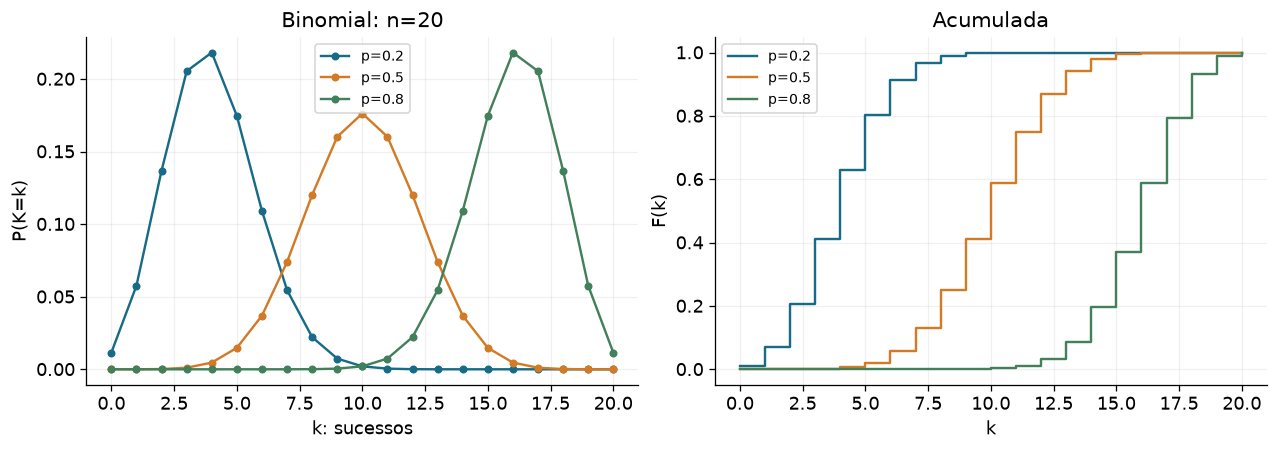

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
linhas_bin = []
for p in [.2, .5, .8]:
    n = 20; k = np.arange(n+1); dist = stats.binom(n, p); pmf = dist.pmf(k)
    axs[0].plot(k, pmf, 'o-', ms=4, label=f'p={p}')
    axs[1].step(k, dist.cdf(k), where='post', label=f'p={p}')
    m = [np.sum(k**r*pmf) for r in range(5)]
    cumulantes = cumulantes_de_momentos(m)[1:]
    analiticos = [n*p, n*p*(1-p), n*p*(1-p)*(1-2*p), n*p*(1-p)*(1-6*p*(1-p))]
    conferir(f'quatro cumulantes binomiais, p={p}', cumulantes, analiticos, atol=1e-7)
    linhas_bin.append({'p': p, 'média': cumulantes[0], 'variância': cumulantes[1],
                      'skewness': cumulantes[2]/cumulantes[1]**1.5,
                      'kurtosis': 3+cumulantes[3]/cumulantes[1]**2})
axs[0].set(title='Binomial: n=20', xlabel='k: sucessos', ylabel='P(K=k)')
axs[1].set(title='Acumulada', xlabel='k', ylabel='F(k)')
for ax in axs: ax.legend(fontsize=9)
tabela(linhas_bin)
print(f'Dez lançamentos: P(K≥5)={stats.binom.sf(4, 10, .5):.6f}; P(K≥4)={stats.binom.sf(3, 10, .5):.6f}')
finalizar(fig, '11_binomial_momentos')


### 3.2 Poisson e o limite de eventos raros

Vamos fixar um intervalo de observação $T$. Se a taxa homogênea de eventos é $\rho$, a contagem média é $\lambda=\rho T$. Aqui $\lambda$ é uma **contagem esperada**, não uma taxa. A variável $K$ pode assumir qualquer inteiro $k\geq0$:

$$P(K=k)=e^{-\lambda}\frac{\lambda^k}{k!}.$$

A normalização é $e^{-\lambda}\sum_k\lambda^k/k!=1$. A MGF resulta da mesma série exponencial:

$$M_K(t)=e^{-\lambda}\sum_{k=0}^\infty\frac{(\lambda e^t)^k}{k!}
=e^{\lambda(e^t-1)},\qquad K_K(t)=\lambda(e^t-1).$$

Cada derivada de $e^t$ em zero vale 1. Logo **todos os cumulantes são $\lambda$**:

$$\mu=\sigma^2=\lambda,\qquad \gamma_1=\lambda^{-1/2},\qquad
\beta_2=3+\lambda^{-1}.$$

**Binomial $\to$ Poisson, slides 21–22.** Tomamos $n\to\infty$, $p=\lambda/n\to0$, mantendo $\lambda$ fixo. Para um $k$ fixo,

$$P(K=k)=\frac{\lambda^k}{k!}
\underbrace{\prod_{j=0}^{k-1}\left(1-\frac jn\right)}_{\to1}
\underbrace{\left(1-\frac\lambda n\right)^n}_{\to e^{-\lambda}}
\underbrace{\left(1-\frac\lambda n\right)^{-k}}_{\to1}.$$

Também podemos ver o limite pela MGF (da binomial) que recaímos, quando $n\rightarrow \infty$ na MGF da Poisson:

$$M_K(t)=\left[1+\frac{\lambda}{n}(e^t-1)\right]^n
\longrightarrow e^{\lambda(e^t-1)}.$$
estamos
Os ensaios tornam-se muitos e a chance por ensaio pequena, com contagem média constante. A direção assintótica é binomial $\to$ Poisson. A binomial obtida ao **condicionar duas contagens de Poisson no total** é outra relação, estudada no capítulo 4.

**Poisson $\to$ Gaussiana, slide 23.** Para $Z_\lambda=(K-\lambda)/\sqrt\lambda$,

$$\log\varphi_{Z_\lambda}(k)=\lambda\left(e^{ik/\sqrt\lambda}-1-\frac{ik}{\sqrt\lambda}\right)
=-\frac{k^2}{2}+O(\lambda^{-1/2}),$$

usando $e^{iu}=1+iu-u^2/2+O(u^3)$. Assim, quando $\lambda\to\infty$, $Z_\lambda$ tende em distribuição à normal padrão. Vamos comparar contagens com uma normal de média $\lambda$ e variância $\lambda$, como nos exemplos $\lambda=1,2,40$ dos slides.

Para comparar corretamente uma massa discreta com uma distribuição contínua, integramos a normal na classe $[k-1/2,k+1/2]$:

$$P_{\rm normal}(K=k)\approx\Phi\left(\frac{k+1/2-\lambda}{\sqrt\lambda}\right)
-\Phi\left(\frac{k-1/2-\lambda}{\sqrt\lambda}\right).$$

$\Phi$ é a CDF da normal padrão, definida em detalhe na seção da Gaussiana. Esse procedimento é a **correção de continuidade**. Para $\lambda$ pequeno, a normal pode atribuir probabilidade a contagens negativas: uma limitação visível da aproximação.


,λ,média,variância,skewness,kurtosis
0,1.0,1.0,1.0,1.000000,4.000
1,2.0,2.0,2.0,0.707107,3.500
2,40.0,40.0,40.0,0.158114,3.025


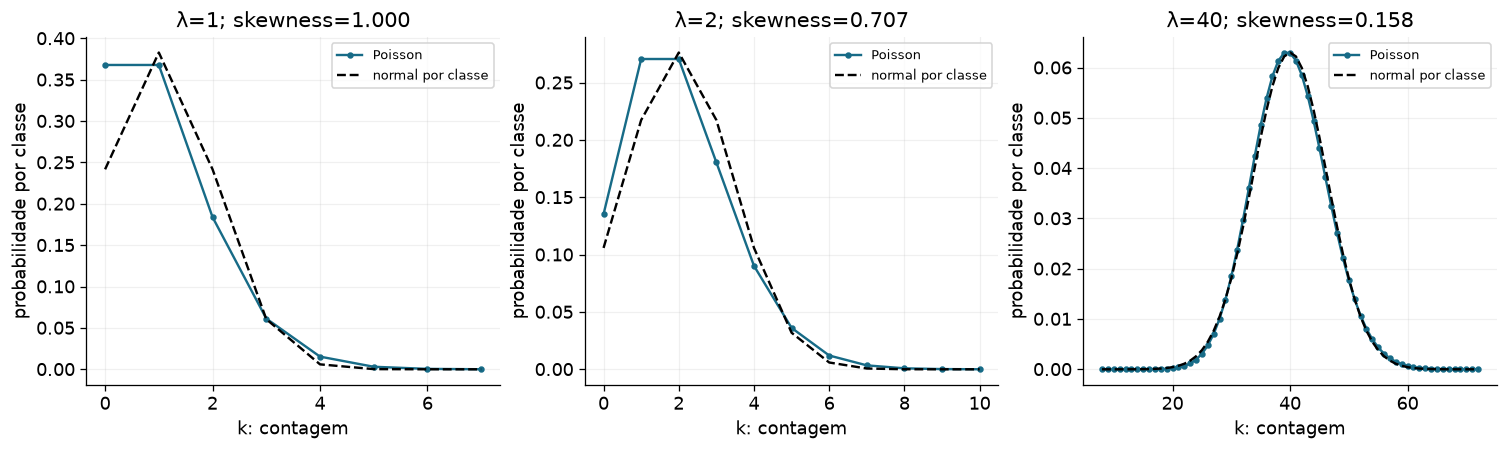

,n,p=λ/n,var binomial,distância TV
0,10,0.400,2.400,0.126726
1,40,0.100,3.600,0.026453
2,200,0.020,3.920,0.005067
3,1000,0.004,3.984,0.001005


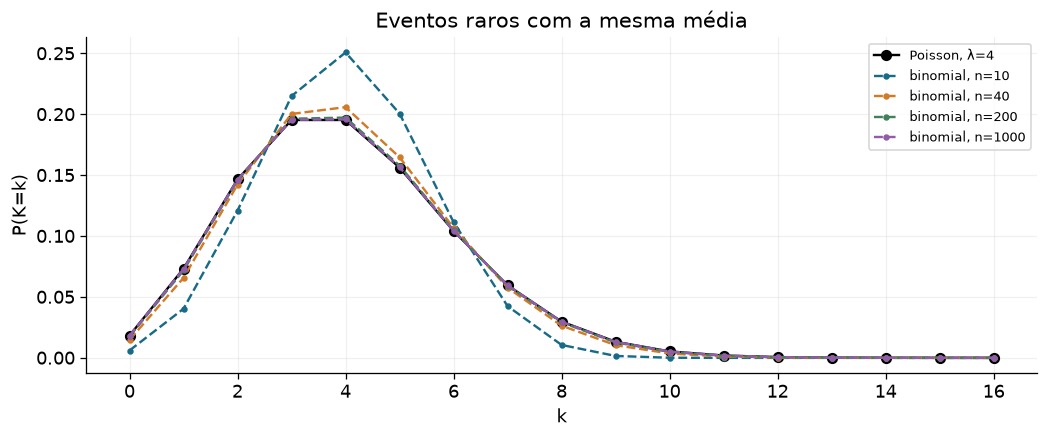

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
linhas_poi = []
for ax, lam in zip(axs, [1., 2., 40.]):
    k = np.arange(max(0, int(lam-5*np.sqrt(lam))), int(lam+5*np.sqrt(lam))+2)
    dist = stats.poisson(lam)
    normal_classes = stats.norm.cdf(k+.5, loc=lam, scale=np.sqrt(lam))-stats.norm.cdf(k-.5, loc=lam, scale=np.sqrt(lam))
    ax.plot(k, dist.pmf(k), 'o-', ms=3, label='Poisson')
    ax.plot(k, normal_classes, ls='--', color='black', label='normal por classe')
    ax.set(title=f'λ={lam:g}; skewness={1/np.sqrt(lam):.3f}', xlabel='k: contagem', ylabel='probabilidade por classe')
    ax.legend(fontsize=8)
    # A soma estendida inclui a cauda que não cabe no painel.
    kt = np.arange(int(dist.ppf(1-1e-13))+1)
    momentos = [np.sum(kt**r*dist.pmf(kt)) for r in range(5)]
    conferir(f'cumulantes da Poisson, λ={lam}', cumulantes_de_momentos(momentos)[1:], [lam]*4, rtol=3e-7, atol=1e-5)
    linhas_poi.append({'λ': lam, 'média': lam, 'variância': lam, 'skewness': 1/np.sqrt(lam), 'kurtosis': 3+1/lam})
tabela(linhas_poi); finalizar(fig, '12_poisson_limite_gaussiano')

# Distância de variação total: metade da soma de diferenças de probabilidades.
# Somamos em todo o suporte binomial e acrescentamos a cauda de Poisson > n.
lam_raro = 4.
linhas_limite = []
fig, ax = plt.subplots(figsize=(9, 3.7))
k_plot = np.arange(17)
ax.plot(k_plot, stats.poisson.pmf(k_plot, lam_raro), 'o-', color='black', label='Poisson, λ=4')
for n in [10, 40, 200, 1000]:
    p = lam_raro/n
    kk = np.arange(n+1)
    tv = .5*(np.abs(stats.binom.pmf(kk, n, p)-stats.poisson.pmf(kk, lam_raro)).sum()+stats.poisson.sf(n, lam_raro))
    ax.plot(k_plot, stats.binom.pmf(k_plot, n, p), '.--', label=f'binomial, n={n}')
    linhas_limite.append({'n': n, 'p=λ/n': p, 'var binomial': n*p*(1-p), 'distância TV': tv})
ax.set(title='Eventos raros com a mesma média', xlabel='k', ylabel='P(K=k)'); ax.legend(fontsize=8)
tabela(linhas_limite); finalizar(fig, '13_binomial_poisson')


### 3.3 Binomial negativa: agora fixamos os sucessos

No slide 25, interrompemos as tentativas assim que ocorre o $m$-ésimo sucesso, com $m$ inteiro positivo. $N$ é o **número total de tentativas**, que agora é variável, e $p$ é a probabilidade de sucesso por tentativa. Precisamos de $N\geq m$.

Se $N=n$, a última tentativa foi sucesso. Entre as $n-1$ anteriores, há $m-1$ sucessos. Logo

$$P(N=n)=\binom{n-1}{m-1}p^m(1-p)^{n-m},\qquad n=m,m+1,\ldots.$$

O SciPy usa outra variável: $F=N-m$, o **número de fracassos antes dos $m$ sucessos**. Assim

$$P(F=f)=\binom{f+m-1}{m-1}p^m(1-p)^f,\qquad f=0,1,\ldots.$$

Para um sucesso, o número de fracassos $G$ tem distribuição geométrica. Sua MGF é a série geométrica

$$M_G(t)=\sum_{f=0}^\infty p[(1-p)e^t]^f
=\frac p{1-(1-p)e^t},\qquad t<-\ln(1-p).$$

Os intervalos de fracassos entre sucessos são independentes neste modelo, então $F=G_1+\cdots+G_m$:

$$M_F(t)=\left[\frac p{1-(1-p)e^t}\right]^m,\qquad
M_N(t)=e^{mt}M_F(t).$$

Para abrir as derivadas, ponha $q=1-p$ e $u=qe^t$. Temos
$K_F(t)=m\ln p-m\ln(1-u)$ e $u'=u$, logo

$$K_F'(t)=\frac{mu}{1-u},\quad
K_F''(t)=\frac{mu}{(1-u)^2},\quad
K_F^{(3)}(t)=\frac{mu(1+u)}{(1-u)^3},$$
$$K_F^{(4)}(t)=\frac{mu(1+4u+u^2)}{(1-u)^4}.$$

Em zero, $u=q$, então $\mathbb E[F]=mq/p$ e $\operatorname{Var}(F)=mq/p^2$. Como $N=F+m$,

$$\mathbb E[N]=\frac mp,\qquad \operatorname{Var}(N)=\frac{m(1-p)}{p^2}.$$

O deslocamento altera só o primeiro cumulante. Os cumulantes superiores são os mesmos de $F$. Em uma estratégia de observação que espera obter certo número de detecções, $N$ descreve o esforço necessário sob este modelo de tentativas independentes. O protocolo de parada precisa fazer parte da definição do experimento.


,variável,média,variância
0,F: fracassos,7.428571,21.22449
1,N: tentativas,11.428571,21.22449


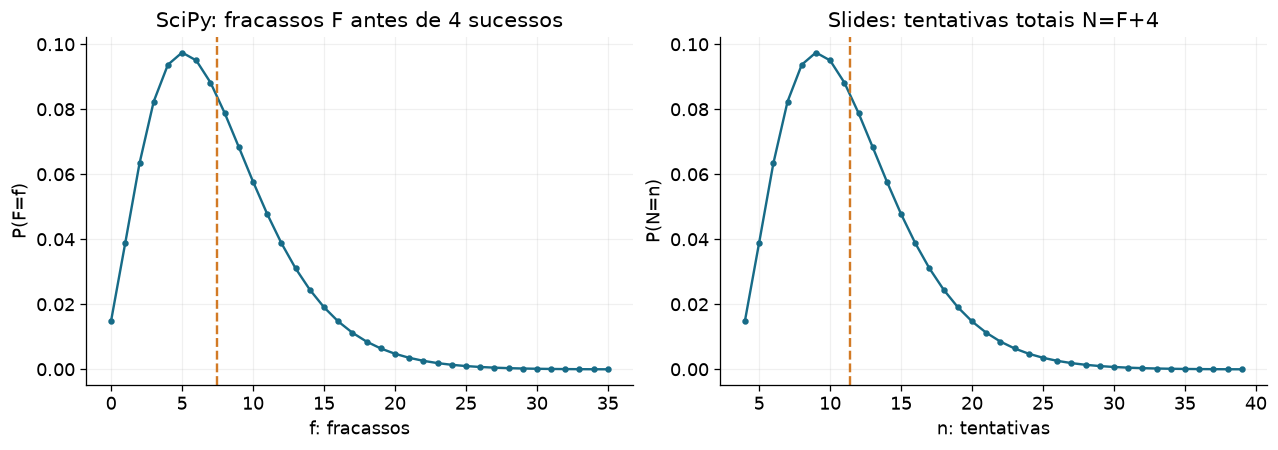

In [20]:
m_sucessos, p_sucesso = 4, .35
dist_fracassos = stats.nbinom(m_sucessos, p_sucesso)
f_fracassos = np.arange(int(dist_fracassos.ppf(.9999))+1)
n_tentativas = f_fracassos+m_sucessos
pmf_neg = dist_fracassos.pmf(f_fracassos)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(f_fracassos, pmf_neg, 'o-', ms=3)
axs[0].axvline(m_sucessos*(1-p_sucesso)/p_sucesso, color=CORES[1], ls='--')
axs[0].set(title='SciPy: fracassos F antes de 4 sucessos', xlabel='f: fracassos', ylabel='P(F=f)')
axs[1].plot(n_tentativas, pmf_neg, 'o-', ms=3)
axs[1].axvline(m_sucessos/p_sucesso, color=CORES[1], ls='--')
axs[1].set(title='Slides: tentativas totais N=F+4', xlabel='n: tentativas', ylabel='P(N=n)')
# Usamos uma soma mais longa para os momentos de ordem alta.
ff = np.arange(int(dist_fracassos.ppf(1-1e-13))+1)
momentos_nb = [np.sum(ff**r*dist_fracassos.pmf(ff)) for r in range(5)]
q = 1-p_sucesso; p = p_sucesso; m = m_sucessos
k_nb = [m*q/p, m*q/p**2, m*q*(1+q)/p**3, m*q*(1+4*q+q**2)/p**4]
conferir('cumulantes da binomial negativa', cumulantes_de_momentos(momentos_nb)[1:], k_nb, rtol=3e-7)
tabela([{'variável': 'F: fracassos', 'média': m*q/p, 'variância': m*q/p**2},
        {'variável': 'N: tentativas', 'média': m/p, 'variância': m*q/p**2}])
finalizar(fig, '14_binomial_negativa_duas_convencoes')


### 3.4 Gaussiana e os intervalos de $\sigma$

Escrevemos $X\sim\mathcal N(\mu,\sigma^2)$, com média $\mu\in\mathbb R$ e desvio padrão $\sigma>0$:

$$f_X(x)=\frac1{\sqrt{2\pi}\sigma}\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].$$

A forma física de um pico gaussiano em um espectro e uma distribuição gaussiana **dos erros** são hipóteses distintas. Aqui estamos estudando a distribuição dos valores possíveis de uma variável.

Para obter a MGF, completamos o quadrado no expoente:

$$tx-\frac{(x-\mu)^2}{2\sigma^2}
=-\frac{[x-(\mu+\sigma^2t)]^2}{2\sigma^2}
+\mu t+\frac{\sigma^2t^2}{2}.$$

A integral da primeira parte é a normalização de uma normal com média deslocada. Portanto

$$M_X(t)=e^{\mu t+\sigma^2t^2/2},\qquad
K_X(t)=\mu t+\frac{\sigma^2t^2}{2}.$$

Temos $\kappa_1=\mu$, $\kappa_2=\sigma^2$ e todos os cumulantes superiores iguais a zero. Os momentos superiores não são todos nulos: por exemplo, $\mu_4=3\sigma^4$, justamente porque ele contém a parte $3\kappa_2^2$.

A normal padrão usa $Z=(X-\mu)/\sigma$. Sua CDF é

$$\Phi(z)=\frac1{\sqrt{2\pi}}\int_{-\infty}^{z}e^{-u^2/2}du.$$

Essa integral não tem primitiva em funções elementares, mas pode ser escrita com a **função erro**, definida por

$$\operatorname{erf}(a)=\frac2{\sqrt\pi}\int_0^ae^{-u^2}du,
\qquad \Phi(z)=\frac12[1+\operatorname{erf}(z/\sqrt2)].$$

Assim, para $a>0$, $P(|X-\mu|\leq a\sigma)=\Phi(a)-\Phi(-a)$. Os valores 68.27%, 95.45% e 99.73% correspondem a 1, 2 e 3 desvios padrão **para esta distribuição**. Não são valores universais para qualquer PDF com o mesmo desvio padrão.

**Binomial $\to$ Gaussiana, slide 26.** Escreva $v=np(1-p)$ e $Z=(K-np)/\sqrt v$. Expandimos a geradora de cumulantes de uma Bernoulli,

$$\ln(1-p+pe^u)=pu+\frac{p(1-p)}2u^2+O(u^3).$$

Usando $u=ik/\sqrt v$ e subtraindo o termo da média,

$$\log\varphi_Z(k)=n\ln(1-p+pe^{ik/\sqrt v})-\frac{iknp}{\sqrt v}
=-\frac{k^2}{2}+O(n^{-1/2}),$$

para $p$ fixo no interior de $(0,1)$. A normal aproxima melhor a região central quando **sucessos e fracassos esperados são ambos grandes**: $np\gg1$ e $n(1-p)\gg1$. Apenas exigir $np\gg1$ não controla uma distribuição concentrada junto a $n$.


,a: desvios padrão,P(|Z|≤a),probabilidade nas duas caudas
0,1,0.682689,0.317311
1,2,0.954500,0.045500
2,3,0.997300,0.002700
3,4,0.999937,0.000063
4,5,0.999999,0.000001


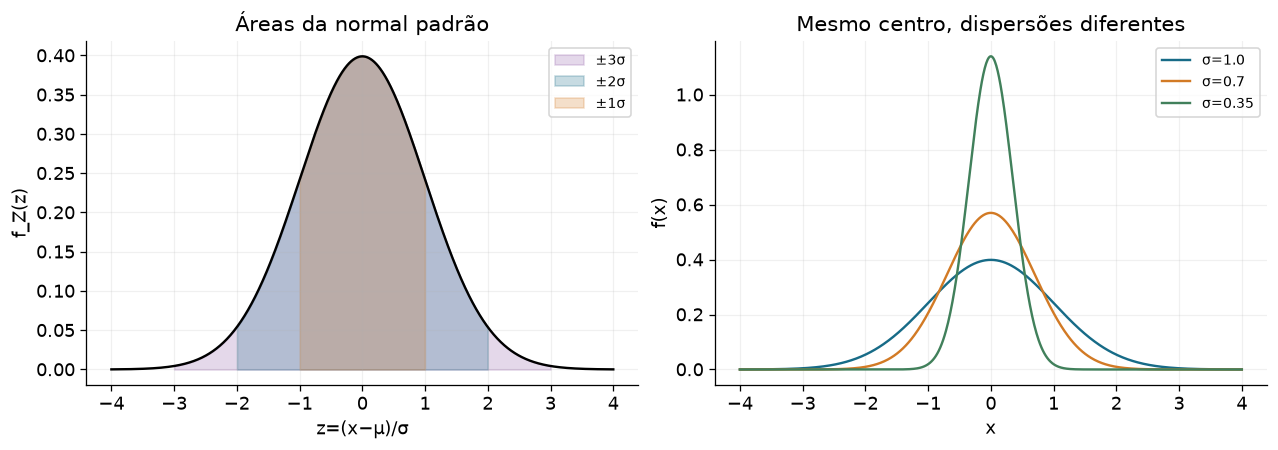

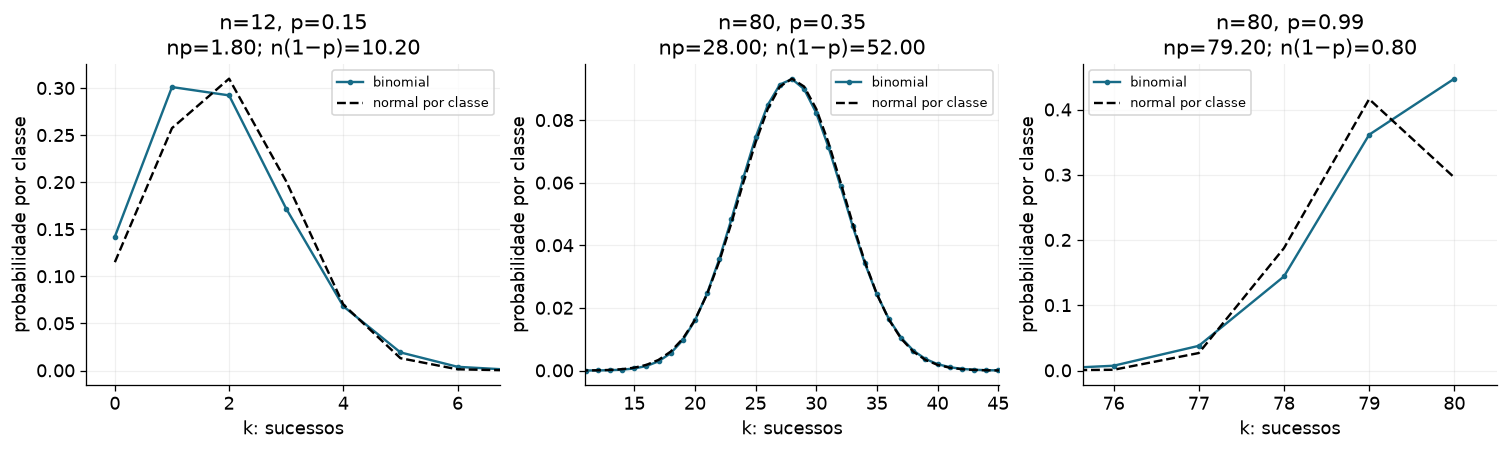

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
zz = np.linspace(-4, 4, 1000)
axs[0].plot(zz, stats.norm.pdf(zz), color='black')
for a, cor in [(3, CORES[3]), (2, CORES[0]), (1, CORES[1])]:
    mask = np.abs(zz) <= a
    axs[0].fill_between(zz[mask], stats.norm.pdf(zz[mask]), alpha=.24, color=cor, label=f'±{a}σ')
axs[0].set(title='Áreas da normal padrão', xlabel='z=(x−μ)/σ', ylabel='f_Z(z)'); axs[0].legend(fontsize=9)
for sig in [1., .7, .35]:
    xx = np.linspace(-4, 4, 700)
    axs[1].plot(xx, stats.norm.pdf(xx, scale=sig), label=f'σ={sig}')
axs[1].set(title='Mesmo centro, dispersões diferentes', xlabel='x', ylabel='f(x)'); axs[1].legend(fontsize=9)
tabela([{'a: desvios padrão': a, 'P(|Z|≤a)': stats.norm.cdf(a)-stats.norm.cdf(-a),
         'probabilidade nas duas caudas': 2*stats.norm.sf(a)} for a in range(1, 6)])
conferir('CDF normal e função erro', stats.norm.cdf(zz), .5*(1+special.erf(zz/np.sqrt(2))))
finalizar(fig, '15_gaussiana_intervalos_sigma')

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, n, p in zip(axs, [12, 80, 80], [.15, .35, .99]):
    k = np.arange(n+1); mu, sig = n*p, np.sqrt(n*p*(1-p))
    aproxima = stats.norm.cdf(k+.5, mu, sig)-stats.norm.cdf(k-.5, mu, sig)
    ax.plot(k, stats.binom.pmf(k, n, p), 'o-', ms=2.5, label='binomial')
    ax.plot(k, aproxima, '--', color='black', label='normal por classe')
    ax.set(title=f'n={n}, p={p}\nnp={n*p:.2f}; n(1−p)={n*(1-p):.2f}',
           xlabel='k: sucessos', ylabel='probabilidade por classe',
           xlim=(max(-.5, mu-4*sig), min(n+.5, mu+4*sig)))
    ax.legend(fontsize=8)
finalizar(fig, '16_binomial_gaussiana_e_limites')


### 3.5 Uniforme: todos os intervalos de mesmo tamanho têm o mesmo peso

Para $X\sim U(a,b)$, com $a<b$, a densidade vale $1/(b-a)$ dentro do intervalo e zero fora. A média é $(a+b)/2$. Deslocando a origem para o centro e pondo $L=b-a$, temos $Y=X-(a+b)/2\sim U(-L/2,L/2)$. Logo

$$\mu_{2r}=\frac1L\int_{-L/2}^{L/2}y^{2r}dy
=\frac{L^{2r}}{2^{2r}(2r+1)},\qquad \mu_{2r+1}=0.$$

Para $r=1$ e $r=2$, obtemos $\sigma^2=L^2/12$ e $\mu_4=L^4/80$. Portanto $\beta_2=(L^4/80)/(L^4/144)=9/5$.

A MGF é uma integral elementar:

$$M_X(t)=\frac1{b-a}\int_a^be^{tx}dx
=\frac{e^{bt}-e^{at}}{(b-a)t},\qquad t\ne0.$$

Em zero usamos o limite $M_X(0)=1$. A aparente singularidade é removível. A mediana coincide com a média; todos os pontos do intervalo têm a mesma densidade, então não existe uma moda única.

Erros de arredondamento ou quantização podem ser modelados por uma uniforme quando as posições dentro de uma célula são aproximadamente equiprováveis. Essa é uma hipótese sobre o mecanismo de medida, não uma propriedade automática de todo arredondamento.


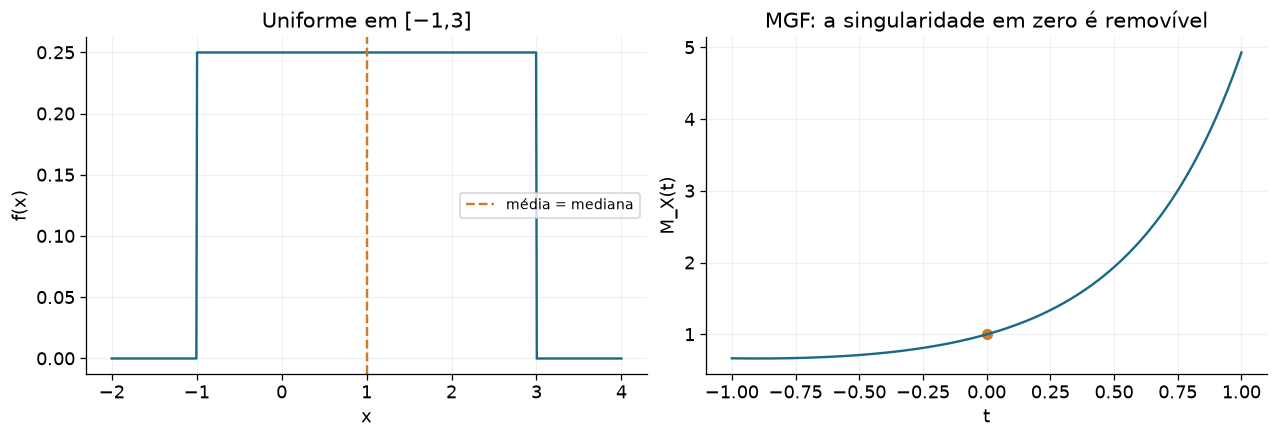

In [22]:
a_uni, b_uni = -1., 3.
def mgf_uniforme(t, a, b):
    """expm1 evita cancelar duas exponenciais quase iguais perto de zero."""
    tt = np.asarray(t, dtype=float)
    out = np.ones_like(tt)
    mask = tt != 0
    out[mask] = np.exp(a*tt[mask])*np.expm1((b-a)*tt[mask])/((b-a)*tt[mask])
    return out.item() if out.ndim == 0 else out

fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
xx = np.linspace(-2, 4, 700)
axs[0].plot(xx, stats.uniform(a_uni, b_uni-a_uni).pdf(xx))
axs[0].axvline((a_uni+b_uni)/2, color=CORES[1], ls='--', label='média = mediana')
axs[0].set(title='Uniforme em [−1,3]', xlabel='x', ylabel='f(x)'); axs[0].legend(fontsize=9)
tt = np.linspace(-1, 1, 400)
axs[1].plot(tt, mgf_uniforme(tt, a_uni, b_uni)); axs[1].scatter([0], [1], color=CORES[1])
axs[1].set(title='MGF: a singularidade em zero é removível', xlabel='t', ylabel='M_X(t)')
for t in [-.5, 0, .4]:
    integral = integrate.quad(lambda x: np.exp(t*x)/(b_uni-a_uni), a_uni, b_uni)[0]
    conferir(f'MGF uniforme por integração, t={t}', integral, mgf_uniforme(t, a_uni, b_uni))
finalizar(fig, '17_uniforme_mgf')


### 3.6 Gamma: definir a função antes de usar a distribuição

A função **Gamma de Euler** generaliza os fatoriais. Para $a>0$, sua definição é

$$\Gamma(a)=\int_0^\infty u^{a-1}e^{-u}du.$$

Por integração por partes,

$$\Gamma(a+1)=\int_0^\infty u^ae^{-u}du
=\left[-u^ae^{-u}\right]_0^\infty+a\int_0^\infty u^{a-1}e^{-u}du
=a\Gamma(a).$$

Como $\Gamma(1)=1$, $\Gamma(m)=(m-1)!$ para $m$ inteiro positivo. Também $\Gamma(1/2)=\sqrt\pi$, obtido pela substituição $u=v^2$ e pela integral gaussiana. Não confundir $\Gamma(a)$, uma função de um argumento, com $\gamma_1$ e $\gamma_2$, nossos coeficientes de forma.

A **distribuição Gamma** tem dois parâmetros: forma $\alpha>0$ e escala $\theta>0$:

$$f_X(x)=\frac{x^{\alpha-1}e^{-x/\theta}}{\Gamma(\alpha)\theta^\alpha},\qquad x>0.$$

O parâmetro $\theta$ tem as unidades de $X$. Outra convenção usa a taxa $\rho=1/\theta$; neste notebook e no SciPy vamos usar **escala**. Substituir $u=x/\theta$ verifica a normalização.

Os momentos vêm da mesma substituição:

$$m_r=\theta^r\frac{\Gamma(\alpha+r)}{\Gamma(\alpha)}
=\theta^r\alpha(\alpha+1)\cdots(\alpha+r-1).$$

Na MGF, combinamos os exponenciais e usamos novamente a integral Gamma:

$$M_X(t)=\frac1{\Gamma(\alpha)\theta^\alpha}
\int_0^\infty x^{\alpha-1}e^{-(1/\theta-t)x}dx
=(1-\theta t)^{-\alpha},\qquad t<1/\theta.$$

Logo $K_X(t)=-\alpha\ln(1-\theta t)$, e

$$\kappa_r=\alpha(r-1)!\theta^r,\quad
\mu=\alpha\theta,\quad\sigma^2=\alpha\theta^2,\quad
\gamma_1=\frac2{\sqrt\alpha},\quad\beta_2=3+\frac6\alpha.$$

Se $\alpha=m$ é inteiro, ela descreve o tempo até o $m$-ésimo evento de um processo de Poisson homogêneo: somamos $m$ tempos de espera exponenciais independentes. Esse caso é chamado **Erlang**. Para $\alpha$ não inteiro, a família continua válida, mas a interpretação literal como número de eventos não se aplica. Para $\alpha=1$, recuperamos a exponencial; para $\alpha$ grande, a variável padronizada se aproxima de uma normal.

**Exemplo do Gregory §5.8.3.** Um material falha após dois ciclos de tensão. Os ciclos ocorrem como eventos de Poisson a uma taxa de 2 por 100 horas. Então $X$, tempo até a falha, segue Gamma com $\alpha=2$, $\theta=50\,\mathrm h$, média 100 h e desvio padrão $50\sqrt2\,\mathrm h$.

O evento $X\leq t$ significa que houve pelo menos dois ciclos até $t$. Como a contagem é Poisson com média $t/\theta$,

$$F_X(t)=1-P(N(t)=0)-P(N(t)=1)
=1-e^{-t/\theta}(1+t/\theta).$$

Vamos calcular $P(\mu-\sigma<X<\mu+\sigma)$. O resultado não precisa ser 68.27%, porque a distribuição ainda é assimétrica.


Intervalo: [29.2893, 170.7107] h; probabilidade = 0.737519


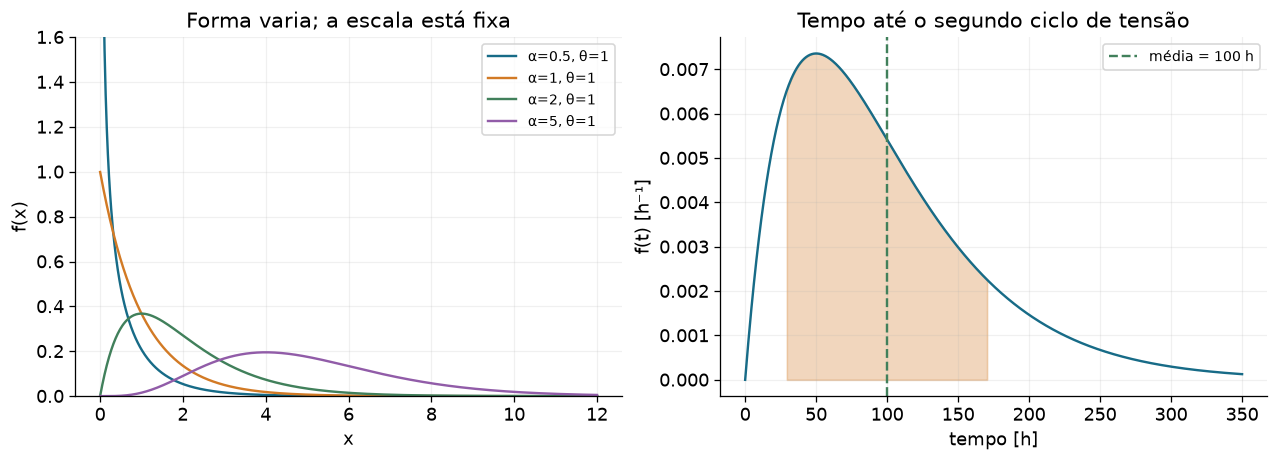

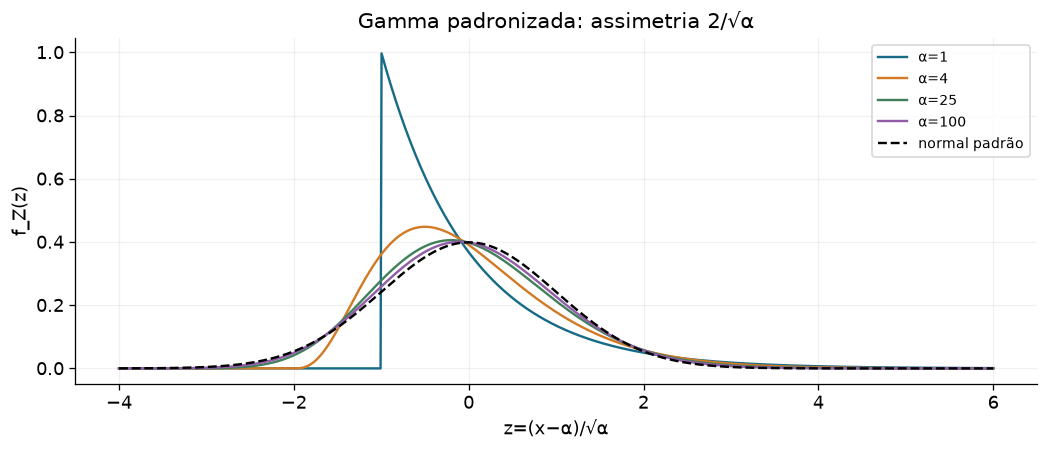

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
xx = np.linspace(.001, 12, 900)
for alpha in [.5, 1, 2, 5]:
    dist = stats.gamma(alpha, scale=1)
    axs[0].plot(xx, dist.pdf(xx), label=f'α={alpha}, θ=1')
axs[0].set(title='Forma varia; a escala está fixa', xlabel='x', ylabel='f(x)', ylim=(0, 1.6)); axs[0].legend(fontsize=9)
dist_falha = stats.gamma(2, scale=50)
mu_falha, sig_falha = dist_falha.mean(), dist_falha.std()
tt = np.linspace(0, 350, 800)
axs[1].plot(tt, dist_falha.pdf(tt))
mask = (tt >= mu_falha-sig_falha)&(tt <= mu_falha+sig_falha)
axs[1].fill_between(tt[mask], dist_falha.pdf(tt[mask]), color=CORES[1], alpha=.3)
axs[1].axvline(mu_falha, color=CORES[2], ls='--', label='média = 100 h')
axs[1].set(title='Tempo até o segundo ciclo de tensão', xlabel='tempo [h]', ylabel='f(t) [h⁻¹]'); axs[1].legend(fontsize=9)
prob_falha = dist_falha.cdf(mu_falha+sig_falha)-dist_falha.cdf(mu_falha-sig_falha)
F_falha = lambda t: 1-np.exp(-t/50)*(1+t/50)
conferir('CDF Gamma do exemplo físico', dist_falha.cdf(tt), F_falha(tt))
print(f'Intervalo: [{mu_falha-sig_falha:.4f}, {mu_falha+sig_falha:.4f}] h; probabilidade = {prob_falha:.6f}')
finalizar(fig, '18_gamma_e_tempo_ate_falha')

# Limite Gamma → normal após centrar e padronizar.
fig, ax = plt.subplots(figsize=(9, 3.8))
zz = np.linspace(-4, 6, 900)
for alpha in [1, 4, 25, 100]:
    mu, sig = alpha, np.sqrt(alpha)
    ax.plot(zz, sig*stats.gamma.pdf(mu+sig*zz, alpha), label=f'α={alpha}')
ax.plot(zz, stats.norm.pdf(zz), '--', color='black', label='normal padrão')
ax.set(title='Gamma padronizada: assimetria 2/√α', xlabel='z=(x−α)/√α', ylabel='f_Z(z)'); ax.legend(fontsize=9)
finalizar(fig, '19_gamma_limite_normal')


### 3.7 Uma ligação entre Gamma, Poisson e binomial negativa

Na Poisson, a variância é igual à média **condicionada a uma contagem esperada fixa**. E se a intensidade variar entre regiões ou exposições? Defina $\Lambda$ como a contagem esperada em uma região, com $K\mid\Lambda\sim\operatorname{Poisson}(\Lambda)$ e $\Lambda\sim\operatorname{Gamma}(a,\theta)$.

Somamos sobre as intensidades possíveis:

$$P(K=k)=\int_0^\infty\frac{e^{-\lambda}\lambda^k}{k!}
\frac{\lambda^{a-1}e^{-\lambda/\theta}}{\Gamma(a)\theta^a}d\lambda.$$

Juntando as potências e os exponenciais,

$$P(K=k)=\frac{\Gamma(a+k)}{\Gamma(a)k!}
\frac{\theta^k}{(1+\theta)^{a+k}}.$$

Isso é uma binomial negativa com parâmetros $a$ e $p=1/(1+\theta)$. A Gamma permite $a$ não inteiro; nesse caso é a generalização da distribuição de contagens, sem uma interpretação de “parar no $a$-ésimo sucesso”.

A lei da esperança total e a decomposição da variância dão

$$\mathbb E[K]=\mathbb E[\Lambda]=a\theta,$$
$$\operatorname{Var}(K)=\mathbb E[\operatorname{Var}(K\mid\Lambda)]
+\operatorname{Var}(\mathbb E[K\mid\Lambda])
=a\theta+a\theta^2.$$

A segunda parcela é a variabilidade da intensidade. Assim, variância maior que a média não é incompatível com uma amostragem Poisson **condicional**. Em contagens de galáxias, essa construção ajuda a pensar na diferença entre flutuações de contagem e variações da densidade subjacente. A Gamma é um modelo ilustrativo, não uma descrição universal do campo cosmológico.

Há também um limite extra útil: mantendo a média $\lambda$ e pondo $\theta=\lambda/a$, a MGF da mistura é $[1-(\lambda/a)(e^t-1)]^{-a}$. Quando $a\to\infty$, ela tende a $e^{\lambda(e^t-1)}$: a binomial negativa se aproxima da Poisson quando a dispersão da intensidade relativa desaparece.


,forma a,média,variância
0,1,6.0,42.00
1,5,6.0,13.20
2,100,6.0,6.36


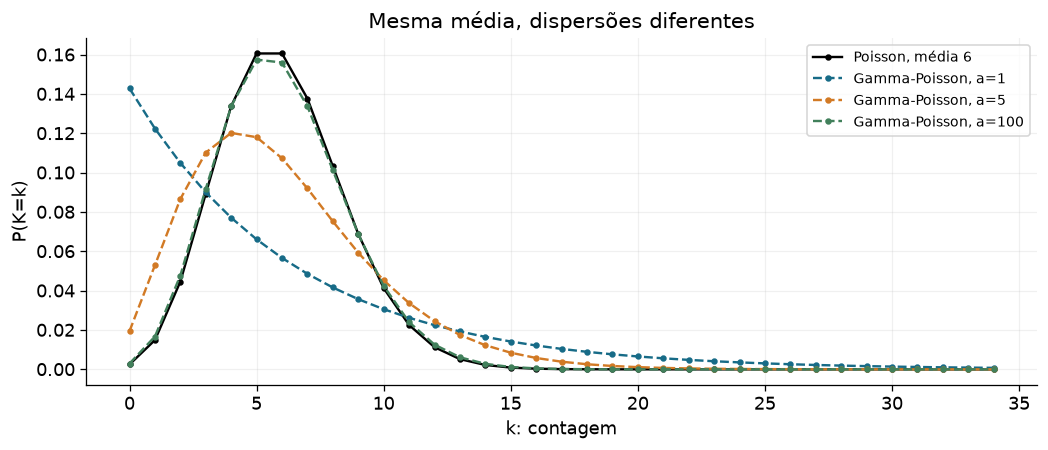

In [24]:
media_contagem = 6.
fig, ax = plt.subplots(figsize=(9, 3.8))
kk = np.arange(35)
ax.plot(kk, stats.poisson.pmf(kk, media_contagem), 'o-', color='black', ms=3, label='Poisson, média 6')
linhas_mix = []
for forma in [1, 5, 100]:
    escala = media_contagem/forma
    p_nb_mix = 1/(1+escala)
    ax.plot(kk, stats.nbinom.pmf(kk, forma, p_nb_mix), '.--', label=f'Gamma-Poisson, a={forma}')
    linhas_mix.append({'forma a': forma, 'média': media_contagem, 'variância': media_contagem+media_contagem**2/forma})
    for k in [0, 3, 8]:
        integral = integrate.quad(lambda lam: stats.poisson.pmf(k, lam)*stats.gamma.pdf(lam, forma, scale=escala), 0, np.inf)[0]
        conferir(f'mistura Gamma-Poisson, a={forma}, k={k}', integral, stats.nbinom.pmf(k, forma, p_nb_mix), atol=2e-8)
ax.set(title='Mesma média, dispersões diferentes', xlabel='k: contagem', ylabel='P(K=k)'); ax.legend(fontsize=9)
tabela(linhas_mix); finalizar(fig, '20_mistura_gamma_poisson')


### 3.8 Beta: primeiro a função de normalização

Para $\alpha,\beta>0$, a **função Beta de Euler** é definida pela integral

$$B(\alpha,\beta)=\int_0^1u^{\alpha-1}(1-u)^{\beta-1}du.$$

Ela é um número para cada par de argumentos. Não é uma PDF, uma posterior ou um novo parâmetro físico. Serve para normalizar a família de densidades que vamos construir.

Sua relação com a função Gamma pode ser demonstrada pela integral dupla

$$\Gamma(\alpha)\Gamma(\beta)=\int_0^\infty\int_0^\infty
x^{\alpha-1}y^{\beta-1}e^{-(x+y)}dx\,dy.$$

Faça $s=x+y$ e $u=x/(x+y)$, de modo que $x=su$, $y=s(1-u)$, $s>0$, $0<u<1$ e $|\partial(x,y)/\partial(s,u)|=s$. Assim a integral se separa:

$$\Gamma(\alpha)\Gamma(\beta)=
\underbrace{\int_0^\infty s^{\alpha+\beta-1}e^{-s}ds}_{\Gamma(\alpha+\beta)}
\underbrace{\int_0^1u^{\alpha-1}(1-u)^{\beta-1}du}_{B(\alpha,\beta)}.$$

Portanto $B(\alpha,\beta)=\Gamma(\alpha)\Gamma(\beta)/\Gamma(\alpha+\beta)$. Agora podemos definir a **distribuição Beta**:

$$f_P(p\mid\alpha,\beta)=\frac{p^{\alpha-1}(1-p)^{\beta-1}}{B(\alpha,\beta)},
\qquad 0<p<1.$$

$P$ é a variável cujo valor possível é $p$; ela pode representar uma proporção ou nossa incerteza sobre uma probabilidade de sucesso. $\alpha$ e $\beta$ são parâmetros de forma. O nome da distribuição e a função de normalização estão relacionados, mas seus papéis são distintos.

**Momentos com as contas abertas.** Multiplicar a PDF por $p^r$ apenas aumenta o primeiro expoente:

$$\mathbb E[P^r]=\frac{B(\alpha+r,\beta)}{B(\alpha,\beta)}
=\prod_{j=0}^{r-1}\frac{\alpha+j}{\alpha+\beta+j}.$$

Em particular,

$$\mu=\frac\alpha{\alpha+\beta},\qquad
m_2=\frac{\alpha(\alpha+1)}{(\alpha+\beta)(\alpha+\beta+1)}.$$

Subtraindo $\mu^2$ e usando denominador comum,

$$\boxed{\sigma^2=\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}.}$$

Para a moda interior, derivamos $\ln f$: $(\alpha-1)/p-(\beta-1)/(1-p)=0$. Se $\alpha,\beta>1$, resulta $p_{\rm moda}=(\alpha-1)/(\alpha+\beta-2)$. Se um parâmetro for menor ou igual a 1, precisamos examinar as bordas; não usamos essa expressão automaticamente.

Quando $\alpha=\beta$, a densidade é simétrica em torno de $1/2$. Quando $\alpha=\beta=1$, recuperamos a uniforme. Nosso exemplo $30p(1-p)^4$ do bloco 1 é precisamente Beta$(2,5)$, porque $B(2,5)=1/30$.

Como $0<P<1$, a MGF existe para todo $t$ real. Podemos escrevê-la sem introduzir uma função especial nova:

$$M_P(t)=\frac1{B(\alpha,\beta)}\int_0^1e^{tp}p^{\alpha-1}(1-p)^{\beta-1}dp
=\sum_{r=0}^\infty\frac{t^r}{r!}\prod_{j=0}^{r-1}\frac{\alpha+j}{\alpha+\beta+j}.$$

O produto vazio, para $r=0$, vale 1. Esta é a mesma regra de gerar momentos que já estudamos.


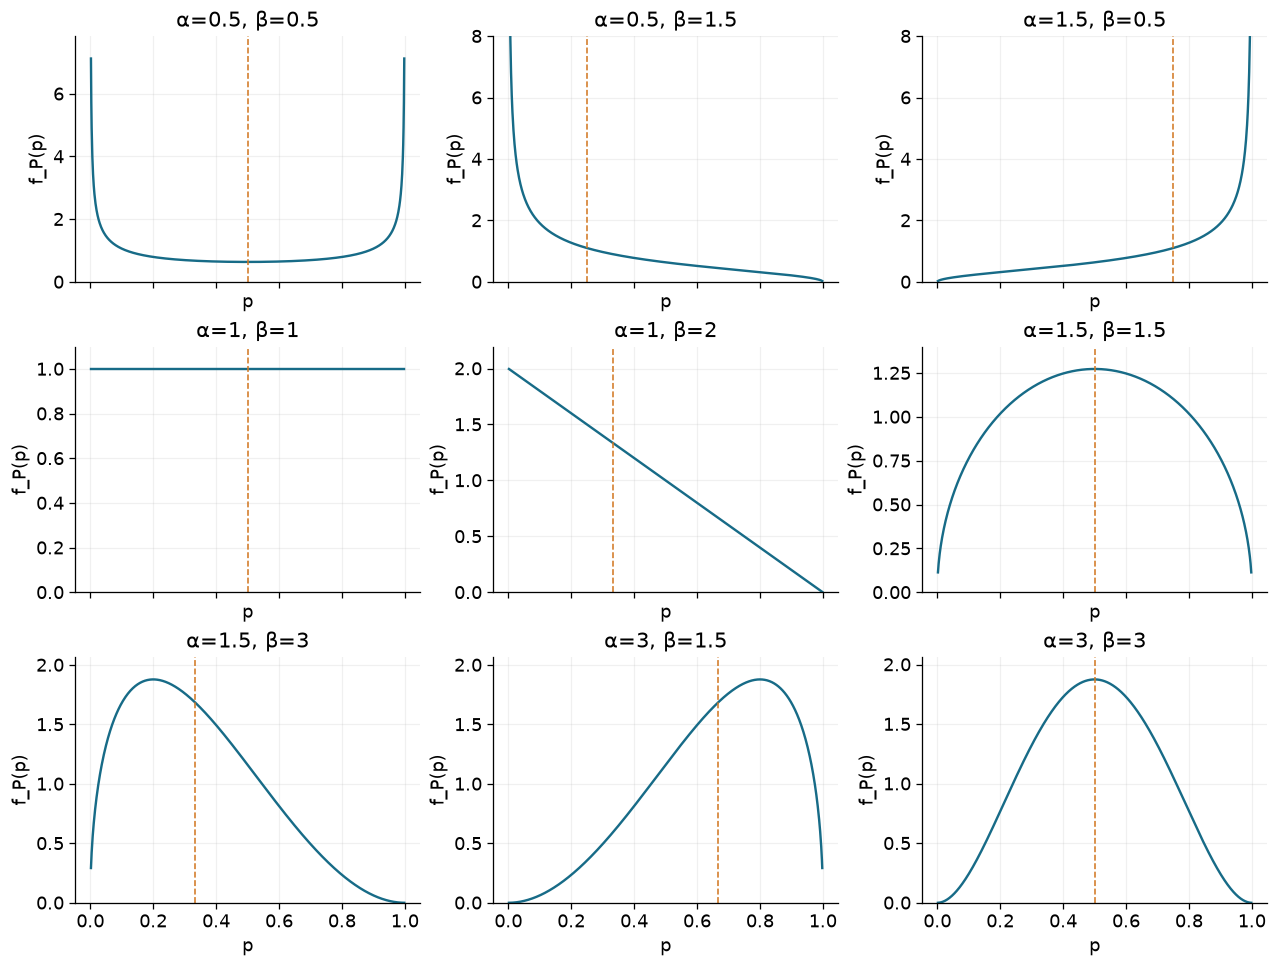

,r,E[P^r]
0,1,0.384615
1,2,0.179487
2,3,0.095023
3,4,0.055013


A função Beta foi definida antes de entrar na posterior.


In [25]:
# Formas ilustradas no Gregory e nos slides. Evitamos avaliar os extremos
# quando α ou β < 1, porque a PDF pode divergir ali e ainda ser integrável.
parametros_beta = [(.5, .5), (.5, 1.5), (1.5, .5), (1, 1), (1, 2), (1.5, 1.5), (1.5, 3), (3, 1.5), (3, 3)]
pp = np.linspace(.002, .998, 900)
fig, axs = plt.subplots(3, 3, figsize=(11, 8.3), sharex=True)
for ax, (alpha, beta) in zip(axs.ravel(), parametros_beta):
    ax.plot(pp, stats.beta.pdf(pp, alpha, beta))
    ax.axvline(alpha/(alpha+beta), color=CORES[1], ls='--', lw=1)
    ax.set(title=f'α={alpha}, β={beta}', xlabel='p', ylabel='f_P(p)')
    ax.set_ylim(0, min(8, 1.1*stats.beta.pdf(pp, alpha, beta).max()))
finalizar(fig, '21_formas_beta')

alpha_beta, beta_beta = 2.5, 4.
dist_beta = stats.beta(alpha_beta, beta_beta)
momentos_beta = []
for r in range(5):
    integral = integrate.quad(lambda p: p**r*dist_beta.pdf(p), 0, 1)[0]
    formula = np.prod([(alpha_beta+j)/(alpha_beta+beta_beta+j) for j in range(r)])
    conferir(f'momento Beta ordem {r}', integral, formula)
    momentos_beta.append(formula)
conferir('função B integral e relação Gamma', integrate.quad(lambda u: u**(alpha_beta-1)*(1-u)**(beta_beta-1), 0, 1)[0],
         special.gamma(alpha_beta)*special.gamma(beta_beta)/special.gamma(alpha_beta+beta_beta))
conferir('variância Beta pela diferença de momentos', momentos_beta[2]-momentos_beta[1]**2,
         alpha_beta*beta_beta/((alpha_beta+beta_beta)**2*(alpha_beta+beta_beta+1)))
tabela([{'r': r, 'E[P^r]': momentos_beta[r]} for r in range(1, 5)])
# Avaliação da MGF por série e por quadratura, sem funções não definidas.
for t in [-1., .5, 2.]:
    termo, soma = 1., 1.
    for r in range(1, 61):
        termo *= t/r*(alpha_beta+r-1)/(alpha_beta+beta_beta+r-1)
        soma += termo
    integral = integrate.quad(lambda p: np.exp(t*p)*dist_beta.pdf(p), 0, 1)[0]
    conferir(f'MGF Beta: série versus integral, t={t}', soma, integral)
print('A função Beta foi definida antes de entrar na posterior.')


### 3.9 Beta como prior: conjugação não significa “mesma likelihood”

Suponha uma prior $P\sim\operatorname{Beta}(\alpha_0,\beta_0)$ e dados de $y$ sucessos em $n$ tentativas. Para $p$ fixo, a contagem tem likelihood binomial:

$$\mathcal L(p)=P(Y=y\mid p,n)=\binom ny p^y(1-p)^{n-y}.$$

Multiplicando pela prior,

$$\pi(p\mid y,n)\propto p^{\alpha_0-1+y}(1-p)^{\beta_0-1+n-y}.$$

Reconhecemos e normalizamos a família Beta:

$$P\mid y,n\sim\operatorname{Beta}(\alpha_0+y,\beta_0+n-y).$$

Dizemos que a **prior Beta é conjugada à likelihood binomial** porque prior e posterior pertencem à família Beta. A likelihood binomial não precisa pertencer à família da prior. Isso corrige a leitura literal de uma frase abreviada do slide 30.

Com prior uniforme, $\alpha_0=\beta_0=1$, a média posterior é $(y+1)/(n+2)$ e a moda, quando interior, é $y/n$. Nenhuma dessas quantidades é a distribuição amostral de $Y$.

Também vamos usar a transformação do slide 32: se $P\in[0,1]$ e $Q=a+(c-a)P$, com limites fixos $a<c$, então

$$f_Q(q)=\frac1{c-a}f_P\left(\frac{q-a}{c-a}\right),\qquad a<q<c.$$

A média e a variância são $a+(c-a)\mu_P$ e $(c-a)^2\sigma_P^2$. O fator $1/(c-a)$ é o jacobiano. A forma com quatro parâmetros é útil quando a variável vive em um intervalo físico diferente de $[0,1]$.


,média posterior,mediana,moda,quantil 2.5%,quantil 97.5%
0,0.318182,0.312584,0.3,0.145877,0.521751


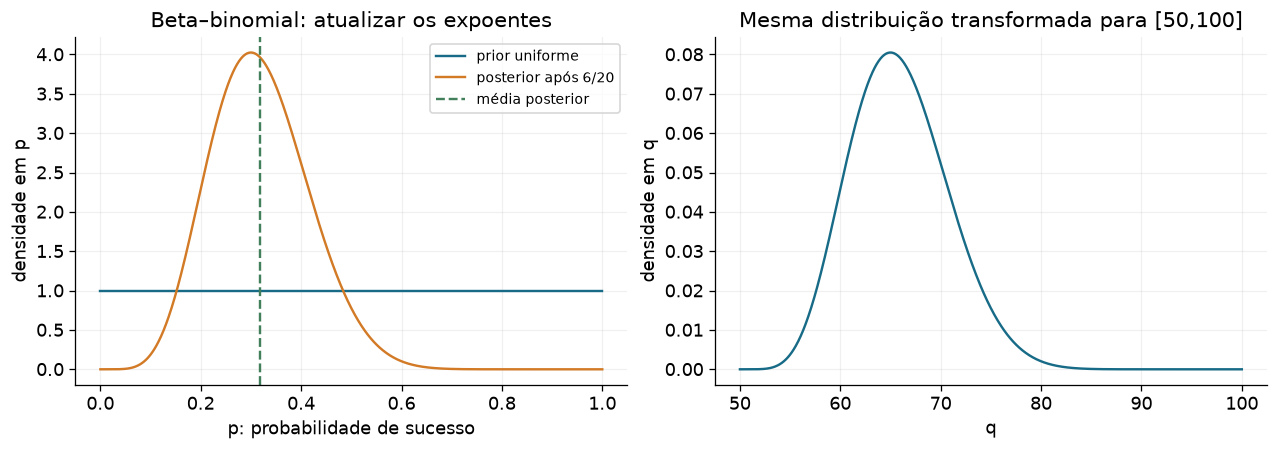

In [26]:
alpha0, beta0, n_beta, y_beta = 1., 1., 20, 6
prior_beta = stats.beta(alpha0, beta0)
posterior_beta = stats.beta(alpha0+y_beta, beta0+n_beta-y_beta)
pp = np.linspace(.0001, .9999, 1000)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(pp, prior_beta.pdf(pp), label='prior uniforme')
axs[0].plot(pp, posterior_beta.pdf(pp), label='posterior após 6/20')
axs[0].axvline(posterior_beta.mean(), color=CORES[2], ls='--', label='média posterior')
axs[0].set(title='Beta–binomial: atualizar os expoentes', xlabel='p: probabilidade de sucesso', ylabel='densidade em p'); axs[0].legend(fontsize=9)
a_q, c_q = 50., 100.
qq = a_q+(c_q-a_q)*pp
pdf_q = posterior_beta.pdf(pp)/(c_q-a_q)
axs[1].plot(qq, pdf_q)
axs[1].set(title='Mesma distribuição transformada para [50,100]', xlabel='q', ylabel='densidade em q')
evidencia_beta = integrate.quad(lambda p: stats.binom.pmf(y_beta, n_beta, p)*prior_beta.pdf(p), 0, 1)[0]
post_direta = stats.binom.pmf(y_beta, n_beta, pp)*prior_beta.pdf(pp)/evidencia_beta
conferir('posterior Beta por produto e normalização', post_direta, posterior_beta.pdf(pp))
conferir('Beta em quatro parâmetros normaliza', integrate.quad(lambda q: posterior_beta.pdf((q-a_q)/(c_q-a_q))/(c_q-a_q), a_q, c_q)[0], 1)
tabela([{'média posterior': posterior_beta.mean(), 'mediana': posterior_beta.median(),
         'moda': y_beta/n_beta, 'quantil 2.5%': posterior_beta.ppf(.025), 'quantil 97.5%': posterior_beta.ppf(.975)}])
finalizar(fig, '22_beta_posterior_e_transformacao')


### 3.10 Exemplo dos slides 33–38: positivos observados e proporção verdadeira

Vamos usar o exemplo histórico de **5 positivos em 250 testes** do slide 36. Ele serve para estudar o modelo estatístico. Não é uma estimativa atual de prevalência nem uma orientação clínica.

Defina $p$ como a proporção verdadeira da propriedade investigada. Seja $\varepsilon$ a taxa de falso positivo e $\delta$ a taxa de falso negativo. A probabilidade de um teste positivo é

$$q(p)=P(+\mid p)=\underbrace{(1-\delta)p}_{\text{verdadeiro positivo}}
+\underbrace{\varepsilon(1-p)}_{\text{falso positivo}}
=\varepsilon+(1-\delta-\varepsilon)p.$$

Chamaremos $s=1-\delta-\varepsilon$ a inclinação dessa relação, assumindo $s>0$. **Não** é a sensibilidade: a sensibilidade é $1-\delta$. Vamos começar tratando os valores centrais dos slides, $\varepsilon=0.01$ e $\delta=0.152$, como conhecidos.

Para $Y=y$ positivos em $n$ testes independentes e uma prior uniforme em $p\in[0,1]$,

$$\pi(p\mid y,n,\varepsilon,\delta)
=\frac{q(p)^y[1-q(p)]^{n-y}}
{\int_0^1q(u)^y[1-q(u)]^{n-y}du},\qquad 0\leq p\leq1.$$

Se o teste fosse perfeito, $q=p$ e a posterior seria Beta$(y+1,n-y+1)$. Com os erros conhecidos, **a posterior em $q$ é uma Beta restrita ao intervalo físico** $\varepsilon\leq q\leq1-\delta$. Escreva $g(q)$ para a PDF Beta$(y+1,n-y+1)$ e $G(q)$ para sua CDF. Pela transformação $q=\varepsilon+sp$,

$$\pi(p\mid D)=\frac{s\,g(\varepsilon+sp)}{G(1-\delta)-G(\varepsilon)},\qquad0\leq p\leq1.$$

Essa é uma expressão **exata para as hipóteses que acabamos de declarar**. Uma Beta deslocada sem restrição permitiria proporções negativas; restringir o suporte também exige renormalizar.

Os slides dão incertezas em $\varepsilon$ e $\delta$. Se esses parâmetros são incertos, devemos marginalizá-los:

$$\pi(p\mid D)\propto\pi(p)\int\!\!\int
q(p,\varepsilon,\delta)^y[1-q(p,\varepsilon,\delta)]^{n-y}
\pi(\varepsilon,\delta\mid I)\,d\varepsilon\,d\delta.$$

Não basta inserir dois intervalos de confiança nessa integral: é necessário especificar a distribuição de informação sobre os erros e suas dependências. Por isso o gráfico abaixo reproduz **o exemplo da cidade com erros fixos**, e não a marginalização completa do artigo ou os resultados estaduais dos slides 37–38, cujos dados individuais não estão fornecidos aqui.

Vamos comparar o teste perfeito, a correção com suporte físico e uma aproximação Beta ajustada pelos dois primeiros momentos. Para uma média $\bar p$ e variância $v$, a concentração da Beta aproximada é $c=\bar p(1-\bar p)/v-1$; então $\alpha=c\bar p$, $\beta=c(1-\bar p)$. Igualar dois momentos não garante que caudas ou modo também coincidam.


,modelo,média,mediana,q2.5%,q97.5%
0,teste perfeito,0.023810,0.022560,0.008822,0.045873
1,"erros fixos, corrigido",0.017297,0.015576,0.001475,0.043124


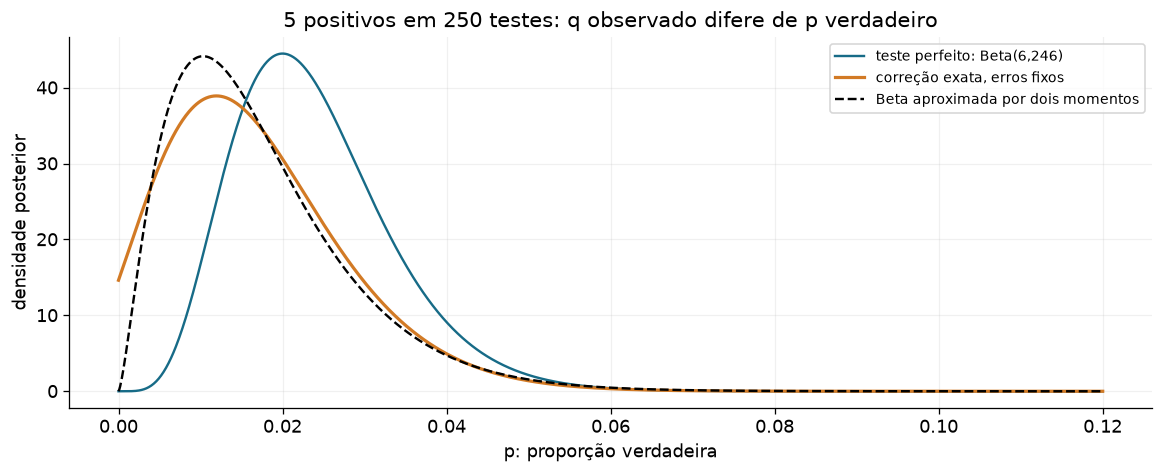

In [27]:
n_teste, y_teste, eps_teste, delta_teste = 250, 5, .01, .152
incl_teste = 1-delta_teste-eps_teste
beta_obs = stats.beta(y_teste+1, n_teste-y_teste+1)
norm_q = beta_obs.cdf(1-delta_teste)-beta_obs.cdf(eps_teste)
def post_corrigida(p):
    q = eps_teste+incl_teste*np.asarray(p)
    return incl_teste*beta_obs.pdf(q)/norm_q

normalizador = integrate.quad(lambda p: (eps_teste+incl_teste*p)**y_teste*(1-eps_teste-incl_teste*p)**(n_teste-y_teste), 0, 1,
                             epsabs=1e-20, epsrel=1e-9)[0]
grid_teste = np.linspace(0, .12, 1200)
direta = (eps_teste+incl_teste*grid_teste)**y_teste*(1-eps_teste-incl_teste*grid_teste)**(n_teste-y_teste)/normalizador
conferir('posterior de proporção: transformação versus integral', direta, post_corrigida(grid_teste), rtol=1e-7)
conferir('normalização da proporção corrigida', integrate.quad(post_corrigida, 0, 1)[0], 1)
mu_pc = integrate.quad(lambda p: p*post_corrigida(p), 0, 1)[0]
var_pc = integrate.quad(lambda p: (p-mu_pc)**2*post_corrigida(p), 0, 1)[0]
concentracao = mu_pc*(1-mu_pc)/var_pc-1
aprox_beta = stats.beta(mu_pc*concentracao, (1-mu_pc)*concentracao)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid_teste, beta_obs.pdf(grid_teste), label='teste perfeito: Beta(6,246)')
ax.plot(grid_teste, post_corrigida(grid_teste), color=CORES[1], lw=2, label='correção exata, erros fixos')
ax.plot(grid_teste, aprox_beta.pdf(grid_teste), '--', color='black', label='Beta aproximada por dois momentos')
ax.set(title='5 positivos em 250 testes: q observado difere de p verdadeiro', xlabel='p: proporção verdadeira', ylabel='densidade posterior')
ax.legend(fontsize=9)
def quantil_pc(u):
    q = beta_obs.ppf(beta_obs.cdf(eps_teste)+u*norm_q)
    return (q-eps_teste)/incl_teste
tabela([{'modelo': 'teste perfeito', 'média': beta_obs.mean(), 'mediana': beta_obs.median(),
         'q2.5%': beta_obs.ppf(.025), 'q97.5%': beta_obs.ppf(.975)},
        {'modelo': 'erros fixos, corrigido', 'média': mu_pc, 'mediana': quantil_pc(.5),
         'q2.5%': quantil_pc(.025), 'q97.5%': quantil_pc(.975)}])
finalizar(fig, '23_exemplo_proporcao_testes')


**Ligação com seleção e detecção.** A estrutura $P(\text{dado}\mid\text{estado verdadeiro})$ reaparece em eficiência de detecção, incompletude e contaminação de catálogos. O que observamos não precisa ter a mesma distribuição do que existe fisicamente. Em uma análise GW–galáxias, a função de seleção e as incertezas relevantes devem entrar no modelo; uma correção linear como a deste teste é apenas um exemplo simples de como separar essas duas camadas.

Para reunir o bloco sem esconder as derivações, esta tabela pode servir de consulta:

| Variável/distribuição | MGF $M_X(t)$ | Média | Variância | Região da MGF |
|:--|:--|:--|:--|:--|
| Binomial $(n,p)$ | $(1-p+pe^t)^n$ | $np$ | $np(1-p)$ | todo $t\in\mathbb R$ |
| Poisson $(\lambda)$ | $e^{\lambda(e^t-1)}$ | $\lambda$ | $\lambda$ | todo $t$ |
| Fracassos NB $(m,p)$ | $[p/(1-(1-p)e^t)]^m$ | $m(1-p)/p$ | $m(1-p)/p^2$ | $t<-\ln(1-p)$ |
| Gaussiana $(\mu,\sigma^2)$ | $e^{\mu t+\sigma^2t^2/2}$ | $\mu$ | $\sigma^2$ | todo $t$ |
| Uniforme $(a,b)$ | $(e^{bt}-e^{at})/[(b-a)t]$, com limite 1 em zero | $(a+b)/2$ | $(b-a)^2/12$ | todo $t$ |
| Gamma $(\alpha,\theta)$ | $(1-\theta t)^{-\alpha}$ | $\alpha\theta$ | $\alpha\theta^2$ | $t<1/\theta$ |
| Beta $(\alpha,\beta)$ | integral/série definida em §3.8 | $\alpha/(\alpha+\beta)$ | $\alpha\beta/[(\alpha+\beta)^2(\alpha+\beta+1)]$ | todo $t$ |

As fórmulas têm sentido junto de suas hipóteses. Por exemplo, contagem Poisson com intensidade conhecida, posterior sobre uma proporção e tempo de espera Gamma não são três nomes para o mesmo experimento.


## Bloco 4 — Somar variáveis e fazer médias
### 4.1 qual distribuição está estreitando?

Seja $X_1,\ldots,X_n$ uma amostra IID com média $\mu$ e variância finita $\sigma^2$. A **média amostral** é uma nova variável:

$$\bar X_n=\frac1n\sum_{i=1}^nX_i.$$

Antes de observar os dados, ela tem uma distribuição: diferentes repetições do experimento produzem diferentes médias. Depois da observação, $\bar x_n$ é um número calculado com os dados. O slide 49 fala da **distribuição de $\bar X_n$**, e não da distribuição original $f_X$ ou de uma posterior para o parâmetro $\mu$.

A média é calculada pela linearidade:

$$\mathbb E[\bar X_n]=\frac1n\sum_i\mathbb E[X_i]=\mu.$$

Vamos abrir a variância, mantendo primeiro os termos cruzados:

$$\operatorname{Var}(\bar X_n)=\frac1{n^2}\mathbb E\left[\left(\sum_i(X_i-\mu)\right)^2\right]
=\frac1{n^2}\left[\sum_i\mathbb E[(X_i-\mu)^2]
+2\sum_{i<j}\mathbb E[(X_i-\mu)(X_j-\mu)]\right].$$

Definimos $\operatorname{Cov}(X_i,X_j)=\mathbb E[(X_i-\mu_i)(X_j-\mu_j)]$. Pela independência, para $i\ne j$, a esperança do produto é o produto das esperanças centradas, que vale zero. Sobra

$$\boxed{\operatorname{Var}(\bar X_n)=\frac{n\sigma^2}{n^2}=\frac{\sigma^2}{n}.}$$

Essas duas relações são **exatas para todo $n$**, sem exigir que a distribuição original seja gaussiana. O desvio padrão da média é $\sigma/\sqrt n$, às vezes chamado de erro padrão. O desvio padrão de **uma observação** continua sendo $\sigma$.

Há duas ideias diferentes:

| Resultado | O que afirma |
|:--|:--|
| Variância da média | a largura cai como $1/\sqrt n$ sob as hipóteses acima |
| Lei dos grandes números | a média se aproxima de $\mu$ em probabilidade |
| Teorema do limite central | a distribuição **centrada e reescalada** tende à normal |

A primeira dá a segunda via Chebyshev: $P(|\bar X_n-\mu|\geq\epsilon)\leq\sigma^2/(n\epsilon^2)\to0$. Aqui $\epsilon>0$ é uma tolerância, não o falso positivo do exemplo anterior.

Sem reescalar, o limite da distribuição de $\bar X_n$ é uma massa concentrada em $\mu$, não uma normal com largura fixa. O TLC descreve

$$Z_n=\frac{\sqrt n(\bar X_n-\mu)}{\sigma}.$$

Vamos usar tempos exponenciais para ver as duas escalas lado a lado. A média possui uma distribuição Gamma exata, com forma $n$ e escala $\theta/n$. Não precisamos de Monte Carlo para essa primeira comparação.


,n,média de uma medida,σ de uma medida,σ da média,skewness da média
0,1,2.0,2.0,2.00,2.00
1,4,2.0,2.0,1.00,1.00
2,16,2.0,2.0,0.50,0.50
3,64,2.0,2.0,0.25,0.25


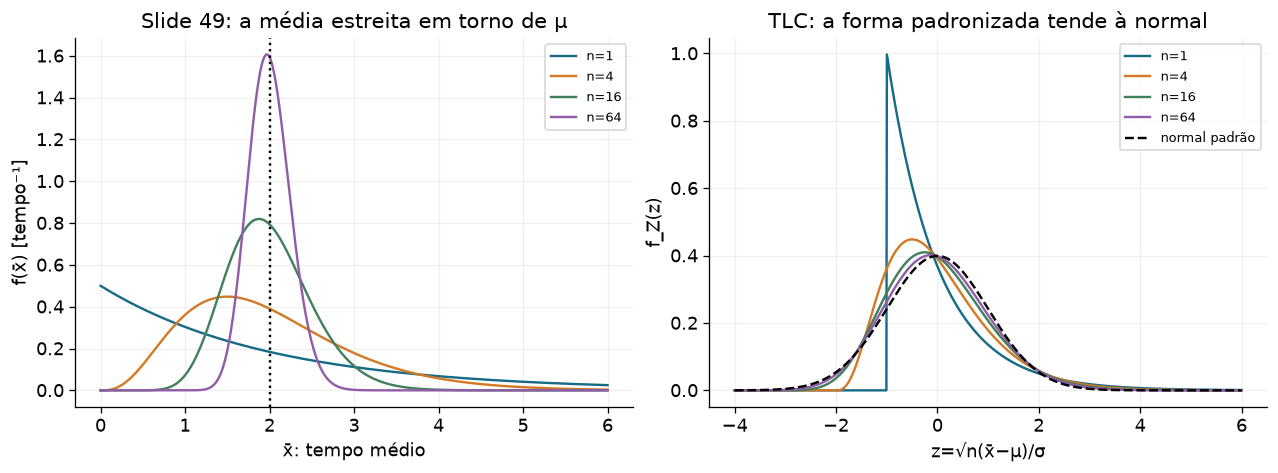

In [28]:
theta_medias = 2.
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(.001, 6, 1000)
zz = np.linspace(-4, 6, 1000)
linhas_media = []
for n in [1, 4, 16, 64]:
    dist_media = stats.gamma(n, scale=theta_medias/n)
    sig_media = theta_medias/np.sqrt(n)
    axs[0].plot(xx, dist_media.pdf(xx), label=f'n={n}')
    axs[1].plot(zz, sig_media*dist_media.pdf(theta_medias+sig_media*zz), label=f'n={n}')
    conferir(f'variância exata da média exponencial, n={n}', dist_media.var(), theta_medias**2/n)
    linhas_media.append({'n': n, 'média de uma medida': theta_medias, 'σ de uma medida': theta_medias,
                         'σ da média': sig_media, 'skewness da média': 2/np.sqrt(n)})
axs[0].axvline(theta_medias, color='black', ls=':')
axs[0].set(title='Slide 49: a média estreita em torno de μ', xlabel='x̄: tempo médio', ylabel='f(x̄) [tempo⁻¹]')
axs[1].plot(zz, stats.norm.pdf(zz), '--', color='black', label='normal padrão')
axs[1].set(title='TLC: a forma padronizada tende à normal', xlabel='z=√n(x̄−μ)/σ', ylabel='f_Z(z)')
for ax in axs: ax.legend(fontsize=8)
tabela(linhas_media); finalizar(fig, '24_slide49_media_e_padronizacao')


### 4.2 Demonstração do TLC: a rota dos slides e sua hipótese adicional

O TLC IID afirma: se $X_i$ são independentes, identicamente distribuídas, com $\mathbb E[X_i]=\mu$ e $0<\operatorname{Var}(X_i)=\sigma^2<\infty$, então

$$Z_n=\frac1{\sqrt n}\sum_{i=1}^nY_i
\xrightarrow{d}\mathcal N(0,1),\qquad Y_i=\frac{X_i-\mu}{\sigma}.$$

$\xrightarrow{d}$ significa **convergência em distribuição**: a CDF de $Z_n$ tende à CDF normal em seus pontos de continuidade. Não afirma que uma sequência particular de valores observados de $Z_n$ converge para um número.

Nos slides 39–41 e no Gregory §5.9, a demonstração usa a MGF. Se ela existe numa vizinhança de zero, a expansão de $M_Y$ dá

$$M_Y(u)=1+\mathbb E[Y]u+\frac{\mathbb E[Y^2]}2u^2+o(u^2)
=1+\frac{u^2}{2}+o(u^2).$$

O símbolo $o(u^2)$ designa um resto que, dividido por $u^2$, tende a zero quando $u\to0$. Pela independência e pelas marginais iguais,

$$M_{Z_n}(t)=\left[M_Y\left(\frac t{\sqrt n}\right)\right]^n
=\left[1+\frac{t^2}{2n}+o(n^{-1})\right]^n.$$

Usando $\ln(1+v)=v+o(v)$ perto de zero,

$$\ln M_{Z_n}(t)=n\left[\frac{t^2}{2n}+o(n^{-1})\right]\to\frac{t^2}{2},$$

logo $M_{Z_n}(t)\to e^{t^2/2}$, a MGF da normal padrão. A convergência da MGF perto da origem identifica o limite.

**Por que precisamos de outra rota?** Variância finita não garante que a MGF exista. Por exemplo, se $X=e^V$ com $V$ gaussiana, $X$ é lognormal e possui todos os momentos inteiros, mas $\mathbb E[e^{tX}]=\infty$ para $t>0$: a exponencial de $X$ cresce mais rapidamente que a cauda da distribuição decai. O TLC ainda se aplica, porque a variância é finita.

Vamos então usar a função característica, que sempre existe. Com segundo momento finito,

$$\varphi_Y(u)=1+i\mathbb E[Y]u-\frac{\mathbb E[Y^2]}2u^2+o(u^2)
=1-\frac{u^2}{2}+o(u^2).$$

Não precisamos assumir a existência de momentos de ordem 3 ou 4 para essa expansão. A finitude do segundo momento permite controlar o resto por convergência dominada. Seguindo a mesma conta,

$$\varphi_{Z_n}(k)=\left[1-\frac{k^2}{2n}+o(n^{-1})\right]^n
\to e^{-k^2/2}.$$

O **teorema de continuidade de Lévy** afirma que a convergência pontual das funções características para uma função característica contínua em zero implica convergência em distribuição. Ele fecha a demonstração para as hipóteses gerais do TLC IID.

Se cumulantes de ordens maiores existem, há uma leitura adicional:

$$\kappa_r(Z_n)=n^{1-r/2}\frac{\kappa_r(X)}{\sigma^r}.$$

O segundo permanece em 1; o terceiro cai como $1/\sqrt n$ e o quarto como $1/n$. Assim, $\gamma_1(\bar X_n)=\gamma_1(X)/\sqrt n$ e $\gamma_2(\bar X_n)=\gamma_2(X)/n$. Essas relações ajudam a entender a redução da não gaussianidade, mas zerar poucos coeficientes não substitui a demonstração por funções características.


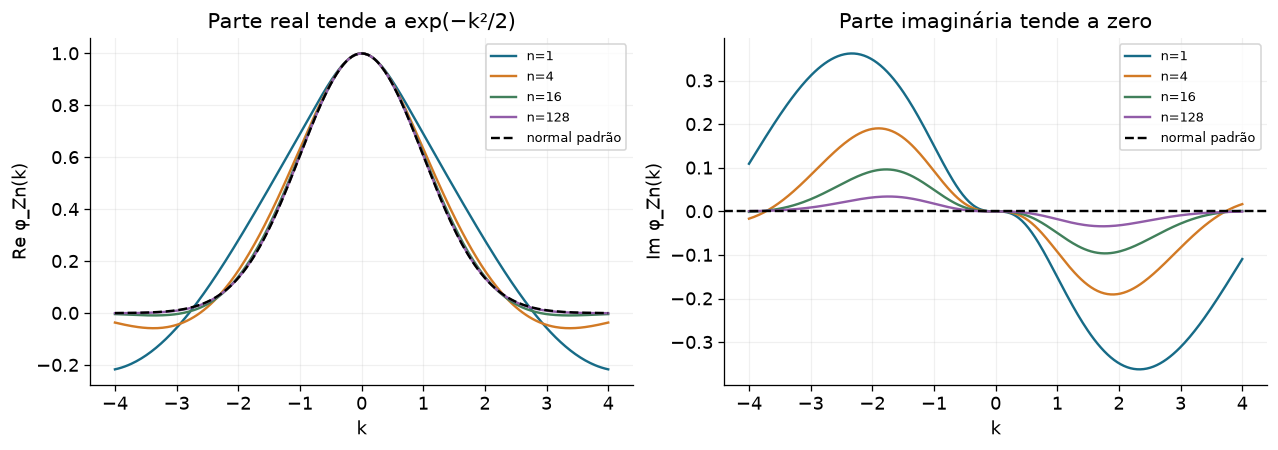

In [29]:
# Conferir diretamente a função característica do Z_n exponencial.
# Para θ=1, μ=σ=1: φ_Zn(k) = exp(−ik√n) (1−ik/√n)^(−n).
ks = np.linspace(-4, 4, 301)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for n in [1, 4, 16, 128]:
    log_phi = -1j*ks*np.sqrt(n)-n*np.log1p(-1j*ks/np.sqrt(n))
    phi = np.exp(log_phi)
    axs[0].plot(ks, phi.real, label=f'n={n}')
    axs[1].plot(ks, phi.imag, label=f'n={n}')
axs[0].plot(ks, np.exp(-ks**2/2), '--', color='black', label='normal padrão')
axs[1].axhline(0, color='black', ls='--', label='normal padrão')
axs[0].set(title='Parte real tende a exp(−k²/2)', xlabel='k', ylabel='Re φ_Zn(k)')
axs[1].set(title='Parte imaginária tende a zero', xlabel='k', ylabel='Im φ_Zn(k)')
for ax in axs: ax.legend(fontsize=8)
finalizar(fig, '25_tlc_funcao_caracteristica')


### 4.3 Ponto de vista amostral: repetir o experimento

Vamos gerar muitas repetições independentes. Em cada uma, produzimos $n$ medidas e calculamos uma média. O histograma reúne essas médias padronizadas; não é o histograma das medidas individuais e não é uma posterior.

Teremos três distribuições originais com média 0 e variância 1 depois da padronização: uniforme, exponencial e uma mistura bimodal. Para a última, escreva

$$X=C+E,\qquad P(C=-d)=P(C=d)=1/2,\qquad E\sim\mathcal N(0,s^2),$$

com $C$ e $E$ independentes. Sua média é 0 e sua variância é $d^2+s^2$. Vamos usar $d=1.5$ e $s=0.2$. Ainda que os primeiros histogramas tenham vários picos, a forma se aproxima de uma normal à medida que somamos mais termos.

Não existe um número universal de observações que torne toda distribuição “gaussiana o bastante”. A qualidade da aproximação depende da distribuição original, da região da cauda que nos interessa e da precisão exigida. Simetria sozinha também não garante convergência rápida de toda a forma.


,distribuição,n,média empírica de Z,variância empírica de Z,skewness empírica,excesso empírico
0,Uniforme,1,0.006505,0.995483,-0.009188,-1.195975
1,Uniforme,2,0.005942,0.990899,0.004492,-0.597445
2,Uniforme,8,0.008136,0.994402,0.008116,-0.138318
3,Uniforme,32,0.002954,1.008717,0.027057,-0.067444
4,Exponencial,1,0.001941,1.018618,2.079762,6.771627
5,Exponencial,2,-0.010055,0.986951,1.409019,2.958546
6,Exponencial,8,-0.012468,1.000882,0.740716,0.932850
7,Exponencial,32,0.004338,1.006178,0.347132,0.161640
8,Bimodal,1,-0.000306,1.000670,0.000263,-1.931122
9,Bimodal,2,-0.000933,0.991399,0.001995,-0.950898


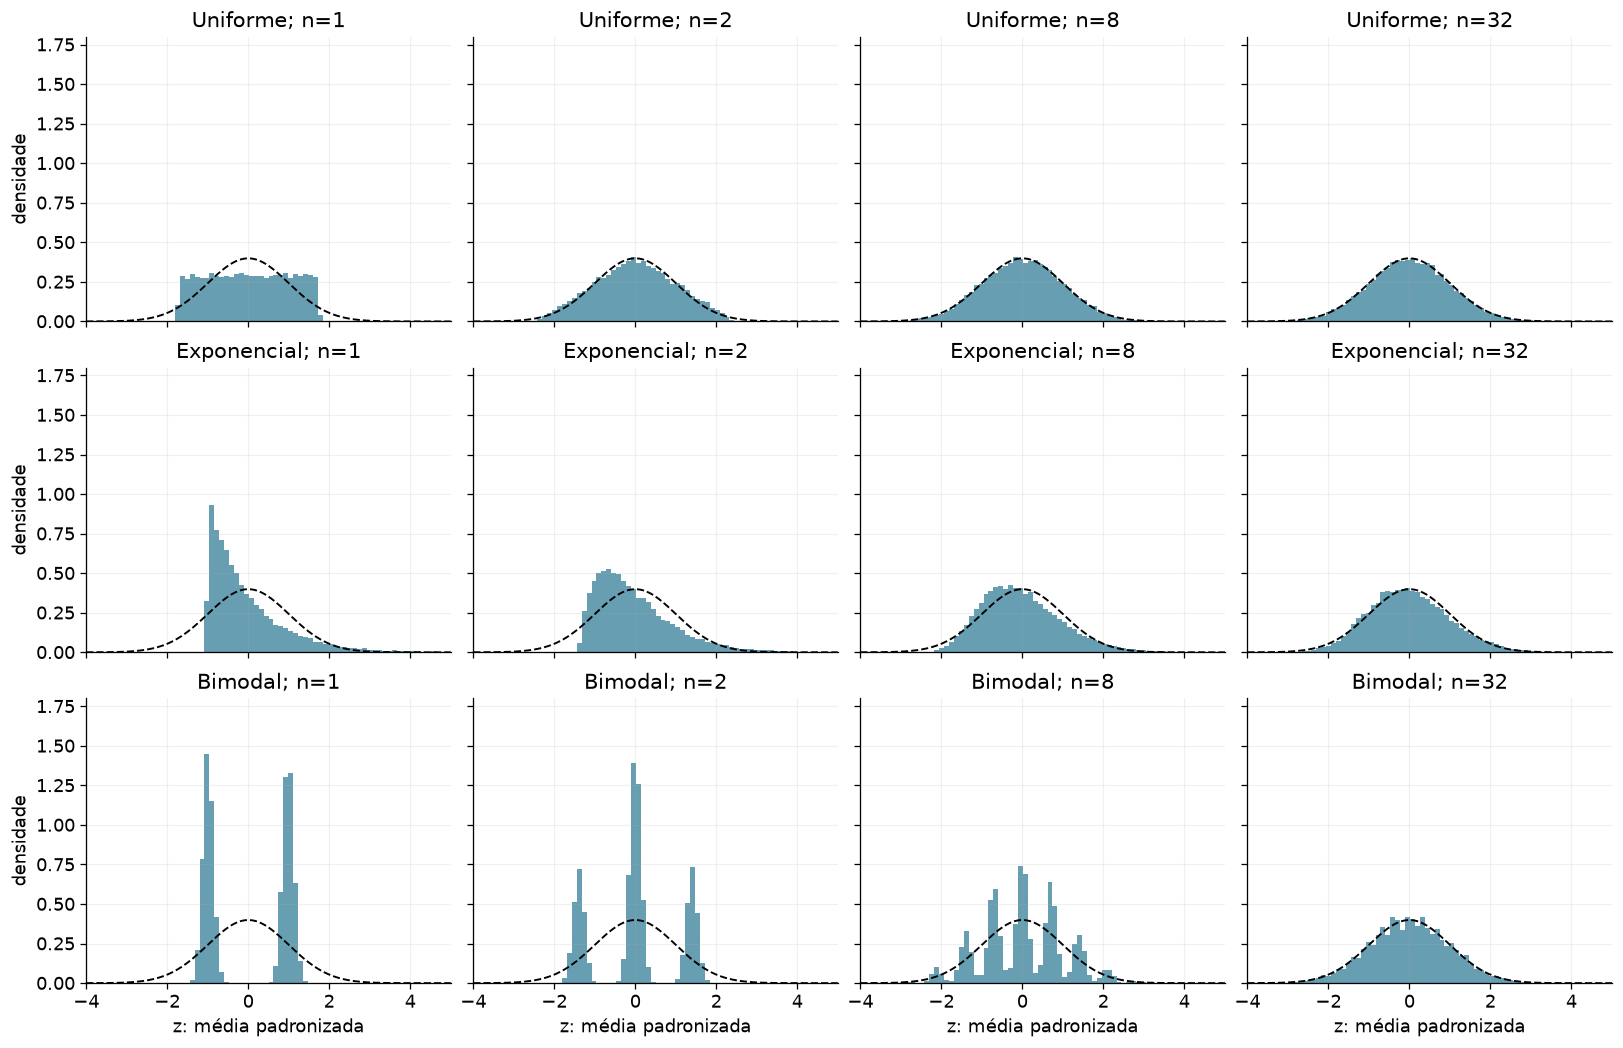

In [30]:
rng_tlc = np.random.default_rng(5039)
REPETICOES = 25000
n_valores = [1, 2, 8, 32]
fig, axs = plt.subplots(3, 4, figsize=(14, 9), sharex=True, sharey=True)
zz = np.linspace(-4, 5, 500)
linhas_tlc = []
for linha, nome in enumerate(['Uniforme', 'Exponencial', 'Bimodal']):
    for coluna, n in enumerate(n_valores):
        if nome == 'Uniforme':
            amostras = rng_tlc.uniform(0, 1, (REPETICOES, n)); mu, sigma = .5, 1/np.sqrt(12)
        elif nome == 'Exponencial':
            amostras = rng_tlc.exponential(1, (REPETICOES, n)); mu, sigma = 1., 1.
        else:
            amostras = 1.5*rng_tlc.choice([-1., 1.], (REPETICOES, n))+rng_tlc.normal(0, .2, (REPETICOES, n))
            mu, sigma = 0., np.sqrt(1.5**2+.2**2)
        z_medias = np.sqrt(n)*(amostras.mean(axis=1)-mu)/sigma
        ax = axs[linha, coluna]
        bordas = np.linspace(-4, 5, 75)
        # Probabilidade por célula dividida pela largura; a massa fora do
        # intervalo visível não é redistribuída nos bins que aparecem.
        pesos_hist = np.full(REPETICOES, 1/(REPETICOES*(bordas[1]-bordas[0])))
        ax.hist(z_medias, bins=bordas, weights=pesos_hist, alpha=.65)
        ax.plot(zz, stats.norm.pdf(zz), '--', color='black', lw=1.2)
        ax.set(title=f'{nome}; n={n}', xlim=(-4, 5), ylim=(0, 1.8))
        if linha == 2: ax.set_xlabel('z: média padronizada')
        if coluna == 0: ax.set_ylabel('densidade')
        linhas_tlc.append({'distribuição': nome, 'n': n, 'média empírica de Z': z_medias.mean(),
                          'variância empírica de Z': z_medias.var(), 'skewness empírica': stats.skew(z_medias),
                          'excesso empírico': stats.kurtosis(z_medias, fisher=True)})
tabela(linhas_tlc)
finalizar(fig, '26_tlc_simulacoes')


### 4.4 Ponto de vista do Gregory: a distribuição da soma por marginalização

Nos slides 42–45, queremos o comprimento total de um objeto composto por partes cujos comprimentos conhecemos com incerteza. Na linguagem bayesiana, as PDFs expressam a informação disponível sobre esses comprimentos. A álgebra da soma é a mesma da teoria de variáveis aleatórias; a interpretação é que pode se tratar de incerteza sobre comprimentos fixos.

Vamos usar $I$ para a informação que justifica as densidades $f_1$ e $f_2$ e a independência. Seja $S=X_1+X_2$. Fixados $x_1,x_2$, a soma é determinada, então

$$p(s\mid x_1,x_2,I)=\delta_D(s-x_1-x_2).$$

$\delta_D$ é a **delta de Dirac**, que tem a propriedade $\int g(x)\delta_D(x-a)dx=g(a)$. Ela representa uma relação exata na densidade condicional, não uma dispersão adicional. Marginalizando,

$$f_S(s)=\int\!\!\int f_1(x_1)f_2(x_2)\delta_D(s-x_1-x_2)dx_1dx_2
=\int_{-\infty}^\infty f_1(x)f_2(s-x)dx.$$

Essa última integral é a **convolução**, denotada $f_S=f_1*f_2$. Para um $s$ fixo, integramos todas as formas de dividir a soma entre as duas partes.

Se ambas são uniformes em $[0,1]$, o integrando vale 1 onde $0<x<1$ e $0<s-x<1$. Logo

$$\max(0,s-1)<x<\min(1,s).$$

A integral é o comprimento do intervalo de sobreposição:

$$f_S(s)=\begin{cases}s,&0<s<1,\\2-s,&1\leq s<2,\\0,&\text{fora}.
\end{cases}$$

Essa conta explica o triângulo: perto de $s=0$ ou $s=2$ há poucas combinações; perto de $s=1$ há muitas. A média $A=S/2$ tem outra densidade,

$$f_A(a)=2f_S(2a),$$

pois $ds=2da$. Para três partes, $f_{S_3}=f_{S_2}*f_3$; para $n$, repetimos a convolução. A relação geral entre a soma e a média é $f_{\bar X_n}(a)=n f_{S_n}(na)$.

A conexão com Fourier também pode ser aberta:

$$\varphi_S(k)=\int e^{iks}\left[\int f_1(x)f_2(s-x)dx\right]ds.$$

Com $y=s-x$, $e^{iks}=e^{ikx}e^{iky}$ e a integral dupla separa em $\varphi_1(k)\varphi_2(k)$. A multiplicação das funções características e a adição dos cumulantes são a mesma estrutura vista por outras operações.

Esta leitura não torna automaticamente gaussiana a posterior de qualquer parâmetro. Estamos propagando a distribuição de uma **soma de componentes independentes**. Uma posterior de $H_0$, por exemplo, envolve também likelihood, prior, seleção e degenerescências; o TLC sozinho não determina sua forma.


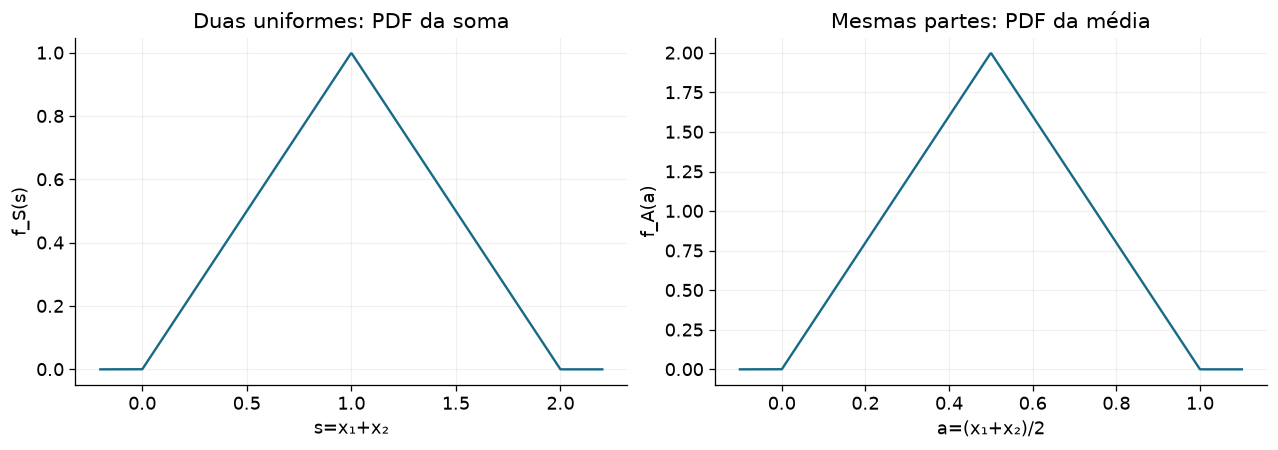

In [31]:
def triangulo_soma(s):
    s = np.asarray(s)
    return np.where((s >= 0)&(s <= 2), np.maximum(0, 1-np.abs(s-1)), 0.)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
ss = np.linspace(-.2, 2.2, 600)
aa = np.linspace(-.1, 1.1, 600)
axs[0].plot(ss, triangulo_soma(ss)); axs[0].set(title='Duas uniformes: PDF da soma', xlabel='s=x₁+x₂', ylabel='f_S(s)')
axs[1].plot(aa, 2*triangulo_soma(2*aa)); axs[1].set(title='Mesmas partes: PDF da média', xlabel='a=(x₁+x₂)/2', ylabel='f_A(a)')
for s in [.2, .8, 1.2, 1.8]:
    # Integramos apenas sobre a sobreposição, evitando descontinuidades internas.
    valor = integrate.quad(lambda x: 1., max(0, s-1), min(1, s))[0]
    conferir(f'convolução uniforme por sobreposição, s={s}', valor, triangulo_soma(s))
conferir('área da soma triangular', integrate.quad(lambda s: triangulo_soma(s), 0, 2)[0], 1)
conferir('variância da média de duas uniformes', integrate.quad(lambda a: (a-.5)**2*2*triangulo_soma(2*a), 0, 1)[0], 1/24)
finalizar(fig, '27_convolucao_uniformes_triangulo')


### 4.5 Várias convoluções, sem gerar amostras

Vamos repetir a convolução para uniforme, exponencial e uma mistura bimodal. Esta comparação complementa os histogramas: agora calculamos as distribuições numericamente a partir de suas PDFs/CDFs, sem erro de Monte Carlo.

Precisamos cuidar da discretização. Dividimos o eixo em células de largura $\Delta x$ e usamos

$$w_j=P(x_j-\Delta x/2<X<x_j+\Delta x/2)
=F_X(x_j+\Delta x/2)-F_X(x_j-\Delta x/2).$$

Os $w_j$ são **probabilidades por célula**, não alturas da PDF. A convolução discreta das probabilidades produz probabilidades para as somas; depois dividimos por $\Delta x$ para visualizar uma densidade aproximada. Para $Z_n=(S_n-n\mu)/(\sigma\sqrt n)$, o jacobiano multiplica a densidade por $\sigma\sqrt n$.

Para a exponencial e a mistura, usamos um intervalo finito contendo praticamente toda a massa. A normalização explícita corrige a pequena truncagem, que será impressa. Não devemos confundir a truncagem numérica com uma mudança deliberada no modelo. A função `fftconvolve` usa Fourier para acelerar a convolução **linear**, com extensão por zeros; não vamos fazer uma convolução circular que mistura as pontas do intervalo.

Também vamos reproduzir diretamente o slide 46: médias de $n=1,2,4,8$ uniformes em $[0,1]$, com o painel $n=8$ comparado à normal de média $1/2$ e variância $1/(12n)$.


Uniforme: massa antes de normalizar = 1.000000000000; Δx=0.00390625
Exponencial: massa antes de normalizar = 0.999999984770; Δx=0.00390625
Bimodal: massa antes de normalizar = 1.000000000000; Δx=0.00390625


,distribuição,n,média da soma,var da soma,var esperada
0,Uniforme,1,0.500000,0.083332,0.083333
1,Uniforme,2,1.000000,0.166664,0.166667
2,Uniforme,4,2.000000,0.333328,0.333333
3,Uniforme,8,4.000000,0.666656,0.666667
4,Uniforme,16,8.000000,1.333313,1.333333
5,Exponencial,1,1.000001,0.999994,1.000000
6,Exponencial,2,2.000002,1.999988,2.000000
7,Exponencial,4,4.000004,3.999975,4.000000
8,Exponencial,8,8.000008,7.999950,8.000000
9,Exponencial,16,16.000016,15.999901,16.000000


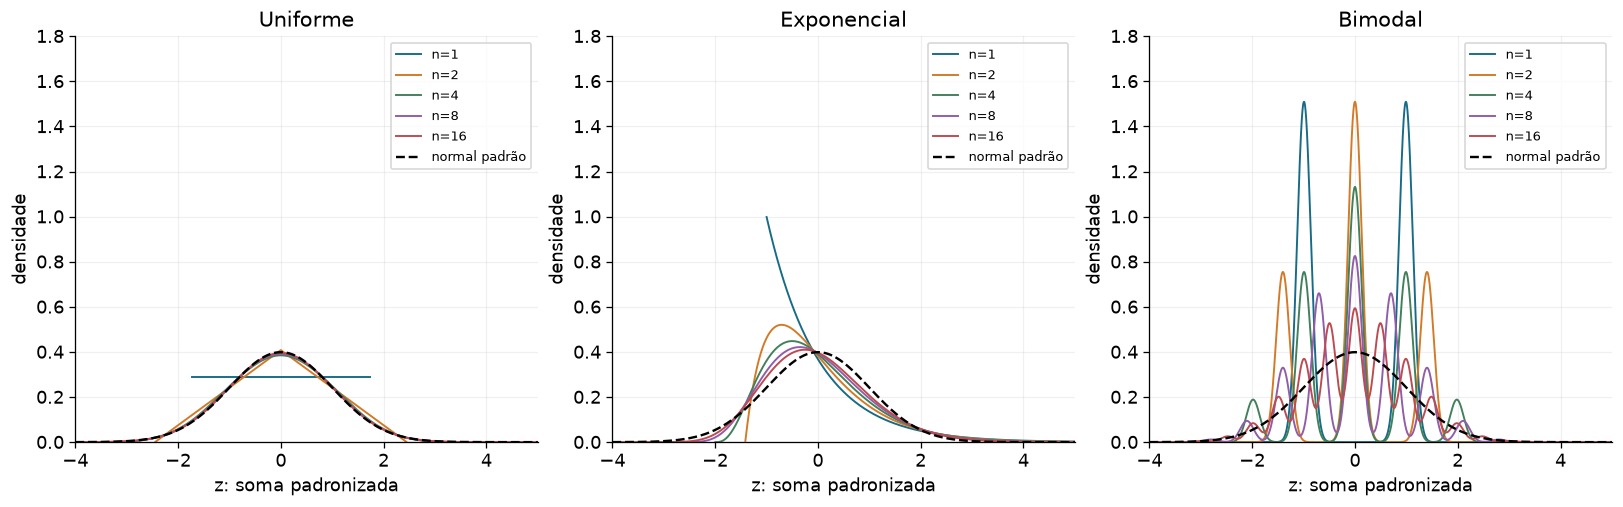

In [32]:
DX_CONV = 1/256

def massas_em_grade(cdf, esquerda, direita, dx=DX_CONV):
    """Integra a CDF em células; retorna centros, probabilidades e massa retida."""
    bordas = np.arange(esquerda, direita+dx/2, dx)
    centros = (bordas[1:]+bordas[:-1])/2
    massas = np.diff(cdf(bordas))
    massa_retida = massas.sum()
    return centros, massas/massa_retida, massa_retida

def convolucoes_iid(centros, massas, ordens):
    """Distribuição discretizada de S_n. Cada célula representa sua posição central."""
    dx = centros[1]-centros[0]
    atual = np.array([1.])
    resultados = {}
    for n in range(1, max(ordens)+1):
        atual = signal.fftconvolve(atual, massas, mode='full')
        # FFT produz arredondamentos ~1e−16; eliminamos somente negativos numéricos.
        atual = np.maximum(atual, 0)
        atual /= atual.sum()
        if n in ordens:
            eixo_soma = n*centros[0]+np.arange(atual.size)*dx
            resultados[n] = (eixo_soma, atual.copy())
    return resultados

cfg_conv = [
    ('Uniforme', stats.uniform().cdf, 0., 1., .5, 1/np.sqrt(12)),
    ('Exponencial', stats.expon().cdf, 0., 18., 1., 1.),
    ('Bimodal', lambda x: .5*stats.norm.cdf(x, -1.5, .2)+.5*stats.norm.cdf(x, 1.5, .2),
     -4.5, 4.5, 0., np.sqrt(1.5**2+.2**2)),
]
ordens_conv = [1, 2, 4, 8, 16]
resultados_conv = {}
fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
linhas_conv = []
for ax, (nome, cdf, esquerda, direita, mu, sigma) in zip(axs, cfg_conv):
    centros, massas, retida = massas_em_grade(cdf, esquerda, direita)
    print(f'{nome}: massa antes de normalizar = {retida:.12f}; Δx={DX_CONV:g}')
    assert 1-retida < 1e-6
    res = convolucoes_iid(centros, massas, ordens_conv)
    resultados_conv[nome] = res
    for n, (ss, pesos) in res.items():
        z = (ss-n*mu)/(sigma*np.sqrt(n))
        pdf_z = sigma*np.sqrt(n)*pesos/DX_CONV
        ax.plot(z, pdf_z, lw=1.2, label=f'n={n}')
        mu_num = pesos @ ss; var_num = pesos @ (ss-mu_num)**2
        conferir(f'média da convolução {nome}, n={n}', mu_num, n*mu, atol=6e-5*n)
        conferir(f'variância da convolução {nome}, n={n}', var_num, n*sigma**2, atol=3e-5*n)
        linhas_conv.append({'distribuição': nome, 'n': n, 'média da soma': mu_num, 'var da soma': var_num,
                            'var esperada': n*sigma**2})
    zz = np.linspace(-4, 5, 500)
    ax.plot(zz, stats.norm.pdf(zz), '--', color='black', label='normal padrão')
    ax.set(title=nome, xlabel='z: soma padronizada', ylabel='densidade', xlim=(-4, 5), ylim=(0, 1.8))
    ax.legend(fontsize=8)
tabela(linhas_conv)
finalizar(fig, '28_convolucoes_varias_distribuicoes')


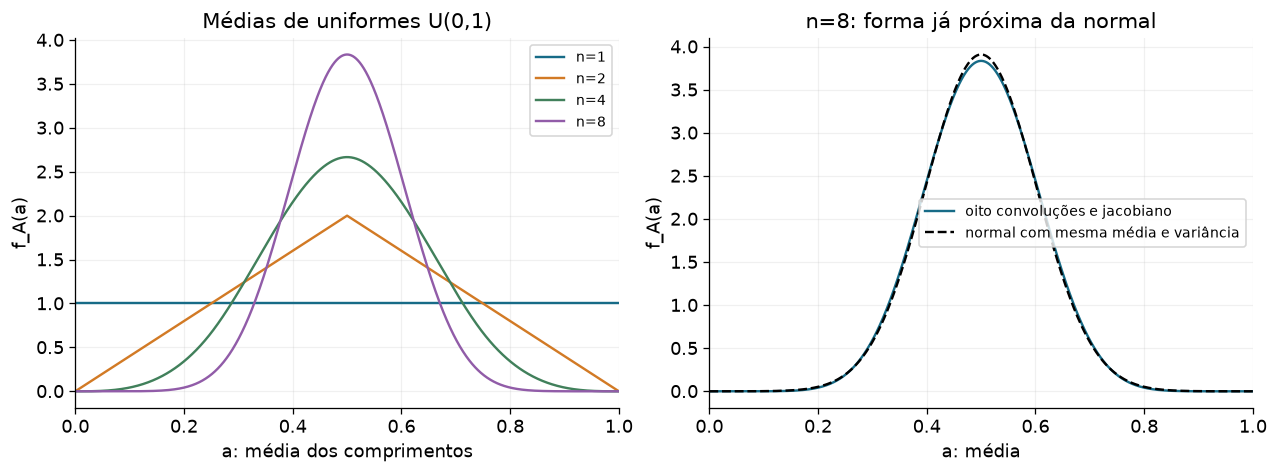

In [33]:
# Slide 46: voltamos ao eixo da média sem padronizar.
res_uniforme = resultados_conv['Uniforme']
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for n in [1, 2, 4, 8]:
    ss, pesos = res_uniforme[n]
    axs[0].plot(ss/n, n*pesos/DX_CONV, label=f'n={n}')
axs[0].set(title='Médias de uniformes U(0,1)', xlabel='a: média dos comprimentos', ylabel='f_A(a)', xlim=(0, 1))
axs[0].legend(fontsize=9)
ss, pesos = res_uniforme[8]
aa = np.linspace(0, 1, 900)
axs[1].plot(ss/8, 8*pesos/DX_CONV, label='oito convoluções e jacobiano')
axs[1].plot(aa, stats.norm.pdf(aa, .5, np.sqrt(1/(12*8))), '--', color='black', label='normal com mesma média e variância')
axs[1].set(title='n=8: forma já próxima da normal', xlabel='a: média', ylabel='f_A(a)', xlim=(0, 1))
axs[1].legend(fontsize=9)
finalizar(fig, '29_slide46_medias_uniformes')


**Interpretando as convoluções.** A uniforme perde suas bordas abruptas quando somada; a exponencial reduz a assimetria; a mistura bimodal produz inicialmente vários grupos de somas e só depois suaviza sua forma. Em todos esses exemplos, a distribuição padronizada tende à mesma normal. A distribuição original de cada componente permanece a mesma.

Os pequenos desvios numéricos na tabela vêm de representar cada célula por seu centro e de truncar o domínio. A cada refinamento de $\Delta x$, esse erro deve diminuir. A aproximação gaussiana é uma questão distinta desse erro numérico.


### 4.6 Limitações: Cauchy, uma componente dominante e correlações

O TLC IID não diz que qualquer soma com muitos termos é aproximadamente gaussiana.

**1. Cauchy.** Para $X_i\sim\operatorname{Cauchy}(x_0,s)$ IID, $\varphi_X(k)=e^{ix_0k-s|k|}$. A função característica da média é

$$\varphi_{\bar X_n}(k)=[\varphi_X(k/n)]^n=e^{ix_0k-s|k|}.$$

Portanto a média segue **a mesma Cauchy**, para qualquer $n$. Sua escala não estreita. Não há conflito com o TLC ou o slide 49: as hipóteses de média e variância finitas não são satisfeitas. Vamos comparar as distribuições por quantis, sem imprimir “média teórica da Cauchy = 0”.

**2. Uma componente dominante.** Uma uniforme muito larga somada a vários erros muito estreitos pode continuar quase uniforme. Esse exemplo não é IID; não contradiz o teorema demonstrado. Para extensões a termos diferentes, é necessário controlar a contribuição de cada um à variância total, de modo que nenhum termo domine. Vamos usar $U(-10,10)$ mais sete $U(-0.1,0.1)$.

**3. Correlações.** A fórmula geral é

$$\operatorname{Var}(\bar X_n)=\frac1{n^2}\sum_{i,j}\operatorname{Cov}(X_i,X_j).$$

Se todas as medidas têm a mesma variância $\sigma^2$ e correlação comum $\rho$, a covariância para $i\ne j$ é $\rho\sigma^2$. Logo

$$\operatorname{Var}(\bar X_n)=\sigma^2\left[\frac{1-\rho}{n}+\rho\right].$$

Uma forma concreta de obter isso é $X_i=\mu+C+E_i$, com um erro comum $C$ de variância $\rho\sigma^2$ e erros independentes $E_i$ de variância $(1-\rho)\sigma^2$. Fazer mais medidas reduz a parte independente, mas não elimina o erro comum. Aqui usaremos $0\leq\rho<1$.

Na pesquisa, modos de um campo, bins sobrepostos e erros de calibração podem ser correlacionados. O número bruto de pixels, galáxias ou medidas não é automaticamente o número de contribuições independentes. A matriz de covariância precisa acompanhar qualquer argumento sobre a precisão da média.


,n,q25 amostral,mediana amostral,q75 amostral,IQR amostral
0,1,-0.989310,0.014303,1.015034,2.004344
1,4,-1.022680,-0.011215,0.982320,2.005000
2,32,-1.031368,-0.013415,0.989185,2.020553


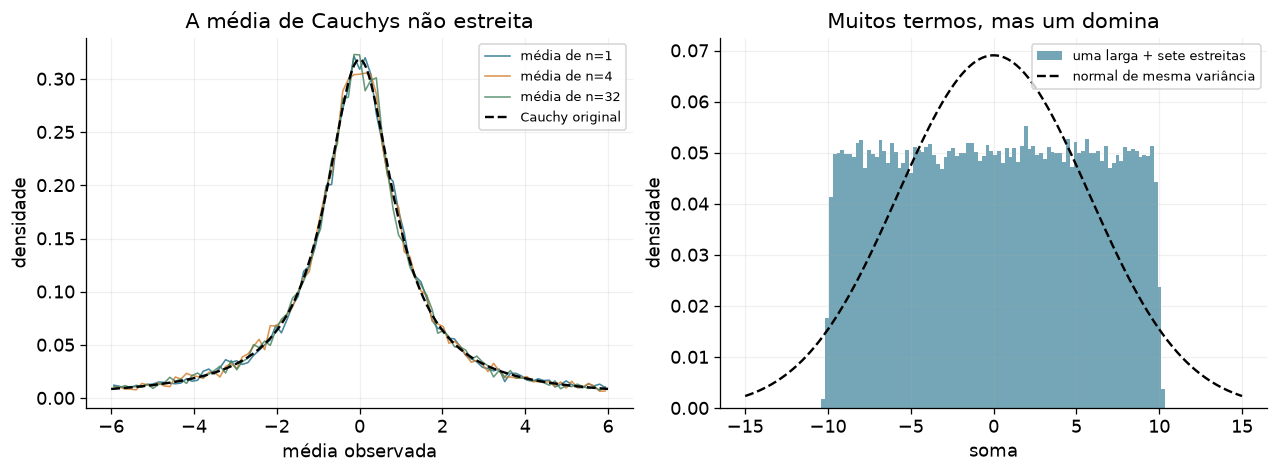

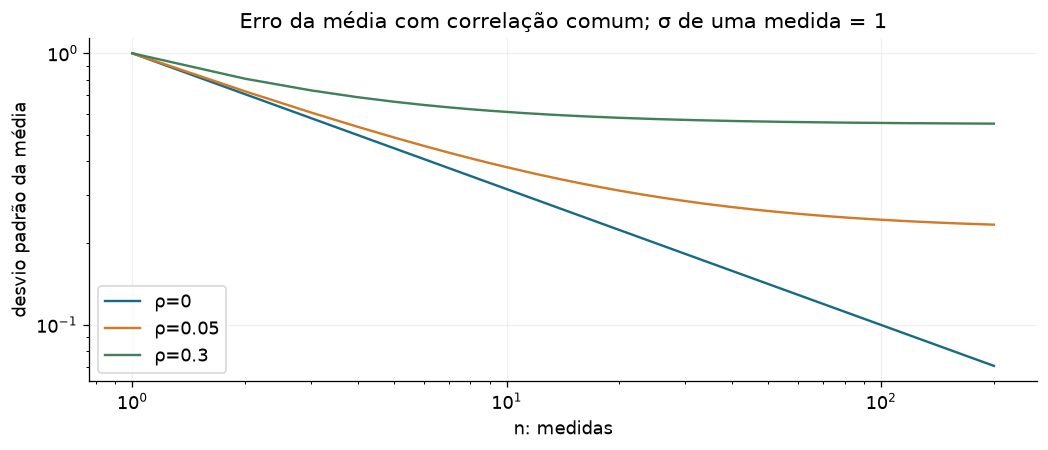

In [34]:
rng_limites = np.random.default_rng(5044)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
linhas_cauchy = []
xx = np.linspace(-6, 6, 500)
for n in [1, 4, 32]:
    amostra = rng_limites.standard_cauchy((22000, n)).mean(axis=1)
    # Counts / (total × largura): não renormalizamos apenas as amostras visíveis.
    bordas = np.linspace(-6, 6, 90)
    counts, _ = np.histogram(amostra, bordas)
    dens = counts/(amostra.size*np.diff(bordas))
    axs[0].plot((bordas[1:]+bordas[:-1])/2, dens, lw=1, alpha=.8, label=f'média de n={n}')
    q25, q50, q75 = np.quantile(amostra, [.25, .5, .75])
    linhas_cauchy.append({'n': n, 'q25 amostral': q25, 'mediana amostral': q50, 'q75 amostral': q75, 'IQR amostral': q75-q25})
axs[0].plot(xx, stats.cauchy.pdf(xx), '--', color='black', label='Cauchy original')
axs[0].set(title='A média de Cauchys não estreita', xlabel='média observada', ylabel='densidade'); axs[0].legend(fontsize=8)
dominante = rng_limites.uniform(-10, 10, 100000)+rng_limites.uniform(-.1, .1, (100000, 7)).sum(axis=1)
sig_dom = np.sqrt(100/3+7*.01/3)
axs[1].hist(dominante, bins=90, density=True, alpha=.6, label='uma larga + sete estreitas')
xd = np.linspace(-15, 15, 700)
axs[1].plot(xd, stats.norm.pdf(xd, scale=sig_dom), '--', color='black', label='normal de mesma variância')
axs[1].set(title='Muitos termos, mas um domina', xlabel='soma', ylabel='densidade'); axs[1].legend(fontsize=8)
tabela(linhas_cauchy); finalizar(fig, '30_limites_tlc')

fig, ax = plt.subplots(figsize=(9, 3.8))
ns = np.arange(1, 201)
for rho in [0, .05, .3]:
    ax.loglog(ns, np.sqrt((1-rho)/ns+rho), label=f'ρ={rho}')
ax.set(title='Erro da média com correlação comum; σ de uma medida = 1', xlabel='n: medidas', ylabel='desvio padrão da média')
ax.legend(); finalizar(fig, '31_correlacao_limita_media')


### 4.7 Sinal/ruído aumenta como $\sqrt n$ — sob quais condições?

O Gregory §5.11.1 soma exposições de um espectrômetro. Vamos separar o **índice do canal** $i$ do **índice da exposição** $j$:

$$D_{ji}=s_i+E_{ji},\qquad \mathbb E[E_{ji}]=0,\quad
\operatorname{Var}(E_{ji})=\sigma^2.$$

$s_i$ é o mesmo sinal físico em cada exposição. Se os erros das exposições forem independentes, no canal $i$ a soma $T_i=\sum_{j=1}^nD_{ji}$ tem sinal $ns_i$ e desvio padrão $\sqrt n\sigma$:

$$\left(\frac SN\right)_{\rm soma}=\frac{ns_i}{\sqrt n\sigma}
=\sqrt n\frac{s_i}{\sigma}.$$

Na média, o sinal permanece em $s_i$ e o desvio padrão cai para $\sigma/\sqrt n$, dando o mesmo $S/N$. Aqui $N$ em $S/N$ é a **escala RMS do ruído**, não o número de tentativas da binomial negativa. O número de exposições é $n$.

Isso também difere da janela móvel: aqui combinamos **novas exposições independentes do mesmo sinal**; antes estimávamos o fundo com **canais vizinhos que podem conter o sinal**. Um filtro de fundo não produz automaticamente o ganho de precisão de várias exposições.

Se a razão inicial é $s_i/\sigma=10^{-3}$, atingir $S/N=5$ requer $n=(5/10^{-3})^2=2.5\times10^7$ exposições independentes. O tempo físico depende da duração necessária para cada exposição ser independente. Erros comuns, variação do sinal e ruído correlacionado alteram esse cálculo.


,n,sinal no pico,ruído RMS da média,S/N esperado
0,1,0.7,1.000000,0.700000
1,2,0.7,0.707107,0.989949
2,8,0.7,0.353553,1.979899
3,64,0.7,0.125000,5.600000


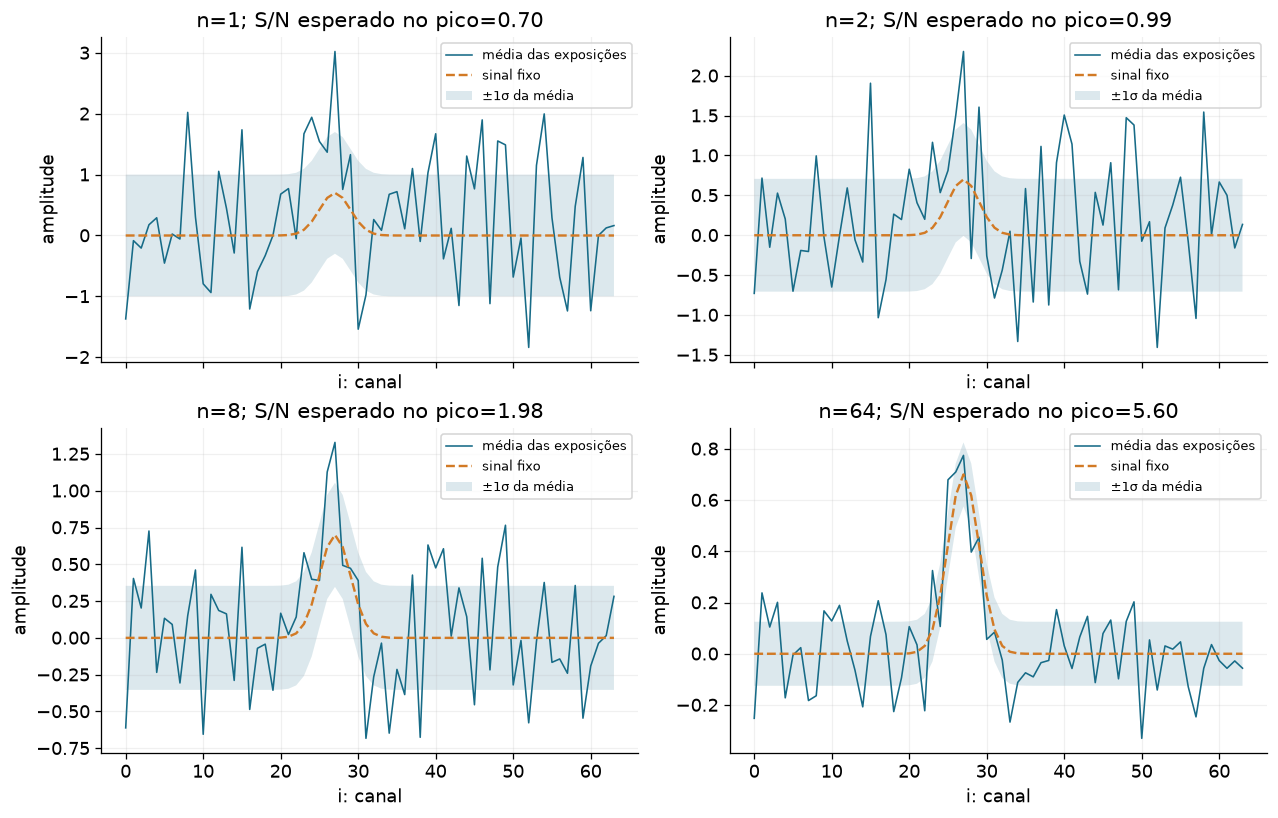

In [35]:
rng_exposicoes = np.random.default_rng(5049)
canal = np.arange(64)
sinal_linha = .7*np.exp(-.5*((canal-27)/2)**2)
sigma_exp = 1.
exposicoes = sinal_linha+rng_exposicoes.normal(0, sigma_exp, (64, 64))
fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
linhas_snr = []
for ax, n in zip(axs.ravel(), [1, 2, 8, 64]):
    media_exp = exposicoes[:n].mean(axis=0)
    ax.plot(canal, media_exp, lw=1, label='média das exposições')
    ax.plot(canal, sinal_linha, color=CORES[1], ls='--', label='sinal fixo')
    ax.fill_between(canal, sinal_linha-sigma_exp/np.sqrt(n), sinal_linha+sigma_exp/np.sqrt(n), alpha=.15, label='±1σ da média')
    ax.set(title=f'n={n}; S/N esperado no pico={.7*np.sqrt(n):.2f}', xlabel='i: canal', ylabel='amplitude')
    ax.legend(fontsize=8)
    linhas_snr.append({'n': n, 'sinal no pico': .7, 'ruído RMS da média': sigma_exp/np.sqrt(n), 'S/N esperado': .7*np.sqrt(n)})
tabela(linhas_snr); finalizar(fig, '32_empilhar_exposicoes_sinal_ruido')


## Bloco 5 — De uma uniforme para qualquer distribuição
### 5.1 O teorema do slide 50: transformação integral de probabilidade

Fixe uma distribuição contínua com CDF $F_X$. Se $X$ segue essa distribuição, então

$$U=F_X(X)\sim U(0,1).$$

$F_X$ é uma função conhecida; $X$ é variável; por isso $F_X(X)$ também é variável. Já $F_X(x)$, avaliada em um valor fixo $x$, é apenas um número. Essa distinção é o mesmo cuidado que tivemos entre $\bar X_n$ e $\bar x_n$.

**Prova pela CDF.** Comecemos com $F_X$ estritamente crescente no suporte, de modo que exista a inversa $Q=F_X^{-1}$. Para $0<u<1$,

$$P(U\leq u)=P(F_X(X)\leq u)=P(X\leq Q(u))
=F_X(Q(u))=u.$$

Essa é precisamente a CDF uniforme: 0 antes de 0, $u$ entre 0 e 1, e 1 depois de 1. Não basta dizer que $F_X(X)$ “está entre 0 e 1”: muitas variáveis ficam nesse intervalo sem serem uniformes. A conta mostra **como a probabilidade está distribuída** nele.

**Prova pelo jacobiano, como no Gregory §5.13.** Onde $f_X(x)>0$,

$$u=F_X(x),\quad\frac{du}{dx}=f_X(x),\quad
f_U(u)=f_X(Q(u))\left|\frac{dQ}{du}\right|
=f_X(Q(u))\frac1{f_X(Q(u))}=1.$$

O cancelamento traduz a conservação de probabilidade: regiões em $x$ com densidade maior ocupam uma faixa maior em $u$.

Se a CDF contínua tem trechos planos por causa de lacunas no suporte, usamos a **inversa generalizada**, ou função quantil:

$$Q(u)=\inf\{x:F_X(x)\geq u\}.$$

$\inf$ é o menor limite inferior do conjunto. As lacunas têm probabilidade zero e não impedem a conclusão $F_X(X)\sim U(0,1)$ para uma CDF contínua. A prova com uma inversa comum é a versão mais simples; o quantil trata os suportes com lacunas.

**A construção inversa.** Se $U\sim U(0,1)$ e $X=Q(U)$, então

$$P(X\leq x)=P(Q(U)\leq x)=P(U\leq F_X(x))=F_X(x).$$

Assim geramos a distribuição desejada a partir de uniformes. A inversa generalizada funciona também para distribuições discretas. Mas, se $X$ é discreta, $F_X(X)$ geralmente **não** é uniforme: a CDF tem saltos e a variável transformada também. Não vamos confundir essas duas direções.

Exemplos com inversa explícita:

$$X\sim U(a,b):\quad X=a+(b-a)U,$$
$$X\sim\operatorname{Exp}(\theta):\quad
U=1-e^{-X/\theta}\ \Rightarrow\ X=-\theta\ln(1-U).$$

O logaritmo transforma intervalos iguais em $u$ em intervalos crescentes em $x$, produzindo a cauda exponencial. Na implementação, `log1p(-u)` calcula $\ln(1-u)$ de forma estável quando $u$ é pequeno. O gerador produz $u<1$, evitando a divergência no extremo superior.


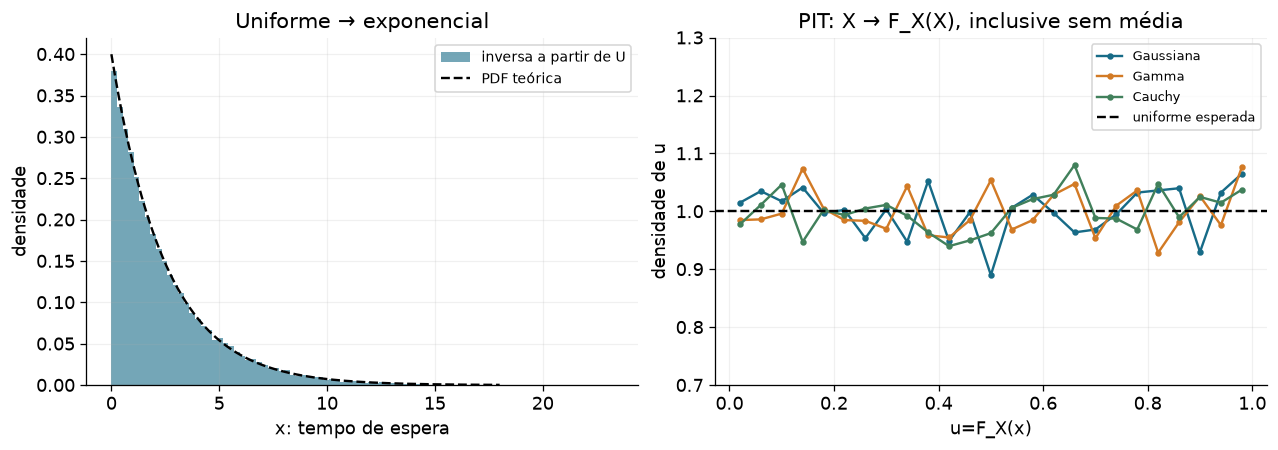

In [36]:
# Inversa da CDF: derivada manualmente para a exponencial.
rng_inversa = np.random.default_rng(5050)
uu = rng_inversa.random(40000)
theta_inversa = 2.5
xx_exp_inversa = -theta_inversa*np.log1p(-uu)
conferir('inversa exponencial conserva o quantil', stats.expon.cdf(xx_exp_inversa, scale=theta_inversa), uu)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
xx = np.linspace(0, 18, 700)
axs[0].hist(xx_exp_inversa, bins=90, density=True, alpha=.6, label='inversa a partir de U')
axs[0].plot(xx, stats.expon.pdf(xx, scale=theta_inversa), '--', color='black', label='PDF teórica')
axs[0].set(title='Uniforme → exponencial', xlabel='x: tempo de espera', ylabel='densidade'); axs[0].legend(fontsize=9)
distros_pit = [
    ('Gaussiana', stats.norm(1, 2)), ('Gamma', stats.gamma(2.3, scale=1.2)), ('Cauchy', stats.cauchy(0, 1)),
]
for nome, dist in distros_pit:
    amostra_x = dist.rvs(size=20000, random_state=rng_inversa)
    amostra_u = dist.cdf(amostra_x)
    counts, bins = np.histogram(amostra_u, np.linspace(0, 1, 26))
    axs[1].plot((bins[:-1]+bins[1:])/2, counts/(amostra_u.size*np.diff(bins)), '.-', label=nome)
axs[1].axhline(1, color='black', ls='--', label='uniforme esperada')
axs[1].set(title='PIT: X → F_X(X), inclusive sem média', xlabel='u=F_X(x)', ylabel='densidade de u', ylim=(.7, 1.3))
axs[1].legend(fontsize=8)
finalizar(fig, '33_inversa_e_transformacao_uniforme')


### 5.2 Slide 51: gerar uma distribuição bimodal

O slide mostra dois picos, sua acumulada, as linhas horizontais de quantis uniformes e o histograma obtido. Vamos reproduzir essa sequência com uma mistura explicitamente definida:

$$f_X(x)=\frac12\mathcal N(x\mid2,0.3^2)+\frac12\mathcal N(x\mid4,0.3^2).$$

$\mathcal N(x\mid\mu,\sigma^2)$ aqui denota a PDF normal avaliada em $x$, não uma variável nova. A CDF é a média das duas CDFs:

$$F_X(x)=\frac12\Phi\left(\frac{x-2}{0.3}\right)
+\frac12\Phi\left(\frac{x-4}{0.3}\right).$$

Ela cresce rapidamente perto dos picos e pouco no intervalo entre eles. Ao distribuir uniformemente os valores de $u$ no eixo vertical, a inversa manda muitos valores para os picos e poucos para a lacuna. Este é o motivo geométrico do histograma bimodal.

Não há uma inversa elementar simples para essa CDF. Vamos calculá-la por interpolação em uma grade fina, verificando a precisão por $F_X(Q(u))\approx u$. Esse erro é numérico e deve ser controlado; não é uma incerteza física extra. Os parâmetros foram escolhidos para reproduzir a estrutura do slide, não extraídos de dados observacionais.


Erro máximo em F(Q(u))−u: 1.867e-08


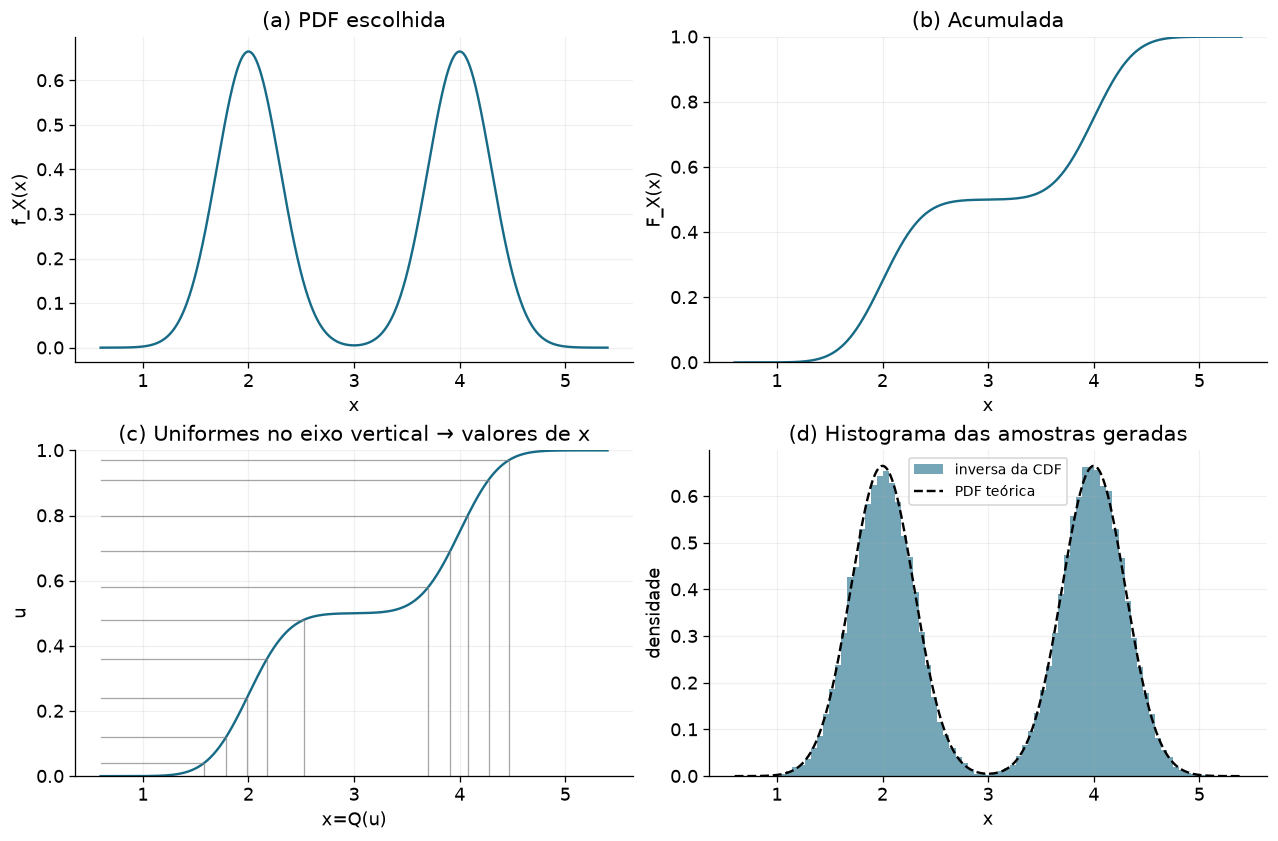

In [38]:
def pdf_bimodal_slide(x):
    return .5*stats.norm.pdf(x, 2, .3)+.5*stats.norm.pdf(x, 4, .3)
def cdf_bimodal_slide(x):
    return .5*stats.norm.cdf(x, 2, .3)+.5*stats.norm.cdf(x, 4, .3)

x_grade_inv = np.linspace(-1, 7, 24001)
F_grade_inv = cdf_bimodal_slide(x_grade_inv)
# Retiramos valores repetidos causados pela precisão de máquina nas caudas.
F_unicos, indices_unicos = np.unique(F_grade_inv, return_index=True)
def quantil_bimodal(u):
    return np.interp(u, F_unicos, x_grade_inv[indices_unicos])

rng_bimodal = np.random.default_rng(5051)
u_bimodal = rng_bimodal.random(45000)
x_bimodal = quantil_bimodal(u_bimodal)
erro_inv = np.max(np.abs(cdf_bimodal_slide(x_bimodal)-u_bimodal))
conferir('inversa bimodal numérica', cdf_bimodal_slide(x_bimodal), u_bimodal, rtol=0, atol=2e-7)
print(f'Erro máximo em F(Q(u))−u: {erro_inv:.3e}')

fig, axs = plt.subplots(2, 2, figsize=(11, 7.2))
xx = np.linspace(.6, 5.4, 1000)
axs[0, 0].plot(xx, pdf_bimodal_slide(xx))
axs[0, 0].set(title='(a) PDF escolhida', xlabel='x', ylabel='f_X(x)')
axs[0, 1].plot(xx, cdf_bimodal_slide(xx))
axs[0, 1].set(title='(b) Acumulada', xlabel='x', ylabel='F_X(x)', ylim=(0, 1))
axs[1, 0].plot(xx, cdf_bimodal_slide(xx))
u_guias = np.array([.04, .12, .24, .36, .48, .58, .69, .8, .91, .97])
x_guias = quantil_bimodal(u_guias)
for u, x in zip(u_guias, x_guias):
    axs[1, 0].plot([.6, x, x], [u, u, 0], color='gray', lw=.8, alpha=.7)
axs[1, 0].set(title='(c) Uniformes no eixo vertical → valores de x', xlabel='x=Q(u)', ylabel='u', ylim=(0, 1))
axs[1, 1].hist(x_bimodal, bins=75, density=True, alpha=.6, label='inversa da CDF')
axs[1, 1].plot(xx, pdf_bimodal_slide(xx), '--', color='black', label='PDF teórica')
axs[1, 1].set(title='(d) Histograma das amostras geradas', xlabel='x', ylabel='densidade')
axs[1, 1].legend(fontsize=9)
finalizar(fig, '34_slide51_inversa_bimodal')


### 5.3 Pseudoaleatoriedade, validação e uso em Monte Carlo

O gerador que usamos é um algoritmo determinístico: a mesma semente produz a mesma sequência na mesma implementação. Isso permite repetir e depurar as simulações. Não é uma afirmação sobre determinismo físico ou sobre a interpretação de eventos quânticos.

O teorema de transformação da CDF diz como transformar uma distribuição uniforme na distribuição alvo. Ele não prova que um gerador computacional tenha todas as propriedades de uma sequência IID ideal. Da mesma forma, um histograma correto não basta para demonstrar independência: uma sequência pode ter a marginal certa e ainda ser correlacionada.

Para o nosso uso, geramos amostras com `np.random.default_rng`, definimos sementes por exemplo e comparamos saídas com PDFs, quantis e relações analíticas. A unidade fundamental de uma simulação é o **modelo gerador completo**, com as dependências que assumimos, não apenas o nome de uma distribuição.

Na pesquisa, essa estrutura será útil ao simular catálogos, propagar incertezas e testar estimadores: construímos o modelo, geramos os dados, repetimos a análise e comparamos com o comportamento esperado. Amostras de uma posterior sobre parâmetros e amostras de dados simulados podem usar técnicas semelhantes de geração, mas respondem a perguntas diferentes.
